# Praktikum 2 Data Mining RKA

Benedictus Ryu Gunawan \
5054251001

Deepseek chat:
- https://chat.deepseek.com/share/tf5nhogfgt027uctix

# Environtment Set Up

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os
from pathlib import Path

ROOT_DIR = Path(os.getcwd()).resolve().parent
DATA_DIR = ROOT_DIR / "data"
OUTPUT_DIR = ROOT_DIR / "output"
TARGET = "harga"
SEED = 3407

# Get Dataset

In [2]:
train_df = pd.read_csv(DATA_DIR / "train.csv", na_values=["NA", "null", "?", "--","not recorded"])
test_df = pd.read_csv(DATA_DIR / "test.csv", na_values=["NA", "null", "?", "--","not recorded"])
train_df.index = train_df["id"]
test_df.index = test_df["id"]

train_df.drop(columns=["id"], inplace=True)
test_df.drop(columns=["id"], inplace=True)

train_df.shape, test_df.shape

((14416, 44), (5940, 43))

In [3]:
display(train_df.info())
display(test_df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 14416 entries, 1 to 14416
Data columns (total 44 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   kode_listing        14416 non-null  object 
 1   judul               13512 non-null  object 
 2   kategori            14416 non-null  object 
 3   jenis_listing       14416 non-null  object 
 4   jenis_penawaran     14416 non-null  object 
 5   periode_harga       14416 non-null  object 
 6   mata_uang           14416 non-null  object 
 7   satuan_luas         14416 non-null  object 
 8   lokasi_lengkap      13354 non-null  object 
 9   eksklusif           14416 non-null  object 
 10  kota                13354 non-null  object 
 11  area_kota           13354 non-null  object 
 12  distrik             12409 non-null  object 
 13  subdistrik          10254 non-null  object 
 14  lintang             13354 non-null  object 
 15  bujur               13354 non-null  object 
 16  tipe_prop

None

<class 'pandas.core.frame.DataFrame'>
Index: 5940 entries, 14417 to 20356
Data columns (total 43 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   kode_listing        5940 non-null   object 
 1   judul               5560 non-null   object 
 2   kategori            5940 non-null   object 
 3   jenis_listing       5940 non-null   object 
 4   jenis_penawaran     5940 non-null   object 
 5   periode_harga       5940 non-null   object 
 6   mata_uang           5940 non-null   object 
 7   satuan_luas         5940 non-null   object 
 8   lokasi_lengkap      5507 non-null   object 
 9   eksklusif           5940 non-null   object 
 10  kota                5507 non-null   object 
 11  area_kota           5507 non-null   object 
 12  distrik             5117 non-null   object 
 13  subdistrik          4256 non-null   object 
 14  lintang             5507 non-null   object 
 15  bujur               5507 non-null   object 
 16  tipe_p

None

In [4]:
display(train_df.head(5))

,kode_listing,judul,kategori,jenis_listing,jenis_penawaran,periode_harga,mata_uang,satuan_luas,lokasi_lengkap,eksklusif,...,nama_agen,nama_broker,email_agen,email_broker,email_kontak,telepon_broker,telepon_kontak,whatsapp_kontak,id_broker,harga
id,,,,,,,,,,,,,,,,,,,,,
1,LST014891,Apartment / completed / cash,buy,property,Residential for Sale,sell,EGP,sqm,Z1_0006 / Z2_0004 / Z3_0309 / Z4_0073,false,...,Person 000300,Person 001945,user002005@example.com,user001943@example.com,user002005@example.com,2.090000e+11,2.090000e+11,2.090000e+11,BRK000161,10000000.0
2,LST019439,Apartment / off_plan_primary / installments,buy,property,Residential for Sale,sell,EGP,sqm,Z1_0009 / Z2_0032 / Z3_0054 / Z4_0788,0,...,Person 001858,Person 000176,user000866@example.com,user000497@example.com,user000866@example.com,2.090000e+11,2.090000e+11,2.090000e+11,BRK000120,6039000.0
3,LST007196,Apartment / completed / cash,buy,property,Residential for Sale,sell,EGP,sqm,Z1_0006 / Z2_0004 / Z3_0309 / Z4_0073,false,...,Person 001125,Person 000308,user000262@example.com,user000262@example.com,user000262@example.com,2.090000e+11,2.090000e+11,2.090000e+11,BRK000107,6000000.0
4,LST005496,Villa / completed / installments,buy,property,Residential for Sale,sell,EGP,sqm,Z1_0006 / Z2_0004 / Z3_0309 / Z4_0073,0,...,Person 002025,Person 000904,user000788@example.com,user000788@example.com,user000788@example.com,2.090000e+11,2.090000e+11,2.090000e+11,BRK000282,42000000.0
5,LST017341,Apartment / off_plan_primary / cash,buy,property,Residential for Sale,sell,EGP,sqm,Z1_0006 / Z2_0004 / Z3_0405,0,...,Person 001651,Person 000007,user000839@example.com,user000345@example.com,user000839@example.com,2.090000e+11,2.090000e+11,2.090000e+11,BRK000655,8260000.0


In [5]:
train_df.drop(columns=["nomor_rera"], inplace=True)
test_df.drop(columns=["nomor_rera"], inplace=True)

In [6]:
cat_cols = train_df.select_dtypes(include=[object]).columns.tolist()
for col in cat_cols:
    # Make all upper
    train_df[col] = train_df[col].str.upper().str.strip()
    test_df[col] = test_df[col].str.upper().str.strip()


## Check Duplicate

In [7]:
print(f"Duplicate rows in train_df: {train_df.duplicated().sum()}")
print(f"Duplicate rows in test_df: {test_df.duplicated().sum()}")

Duplicate rows in train_df: 554
Duplicate rows in test_df: 0


In [8]:
train_df.drop_duplicates(inplace=True)
test_df.drop_duplicates(inplace=True)

## Hapus Only 1 Categorical value

In [9]:
cols_with_one_cardinality = [col for col in train_df.columns if train_df[col].nunique() == 1]
print(f"Columns with one cardinality: {cols_with_one_cardinality}")
train_df.drop(columns=cols_with_one_cardinality, inplace=True)
test_df.drop(columns=cols_with_one_cardinality, inplace=True)

Columns with one cardinality: ['kategori', 'jenis_listing', 'jenis_penawaran', 'periode_harga', 'mata_uang', 'satuan_luas']


## Memperbaiki Dtype

In [10]:
train_df["tanggal_listing"] = pd.to_datetime(train_df["tanggal_listing"], errors="coerce", format="mixed")
test_df["tanggal_listing"] = pd.to_datetime(test_df["tanggal_listing"], errors="coerce", format="mixed")

train_df["bulan"] = train_df["tanggal_listing"].dt.month
train_df["tahun"] = train_df["tanggal_listing"].dt.year

test_df["bulan"] = test_df["tanggal_listing"].dt.month
test_df["tahun"] = test_df["tanggal_listing"].dt.year

train_df.drop(columns=["tanggal_listing"], inplace=True)
test_df.drop(columns=["tanggal_listing"], inplace=True)

In [11]:
nomor_cols = [ "telepon_broker", "telepon_kontak", "whatsapp_kontak" ]
for col in nomor_cols:
    train_df[col] = train_df[col].astype(str).str.replace(r"\D", "", regex=True)
    test_df[col] = test_df[col].astype(str).str.replace(r"\D", "", regex=True)


In [12]:
train_df.head()

,kode_listing,judul,lokasi_lengkap,eksklusif,kota,area_kota,distrik,subdistrik,lintang,bujur,...,email_agen,email_broker,email_kontak,telepon_broker,telepon_kontak,whatsapp_kontak,id_broker,harga,bulan,tahun
id,,,,,,,,,,,,,,,,,,,,,
1,LST014891,APARTMENT / COMPLETED / CASH,Z1_0006 / Z2_0004 / Z3_0309 / Z4_0073,FALSE,Z1_0006,Z2_0004,Z3_0309,Z4_0073,30.03,31.55,...,USER002005@EXAMPLE.COM,USER001943@EXAMPLE.COM,USER002005@EXAMPLE.COM,2090000005090,2090000008870,2090000017190,BRK000161,10000000.0,3.0,2026.0
2,LST019439,APARTMENT / OFF_PLAN_PRIMARY / INSTALLMENTS,Z1_0009 / Z2_0032 / Z3_0054 / Z4_0788,0,Z1_0009,Z2_0032,Z3_0054,Z4_0788,27.13,33.83,...,USER000866@EXAMPLE.COM,USER000497@EXAMPLE.COM,USER000866@EXAMPLE.COM,2090000018580,2090000009550,2090000017190,BRK000120,6039000.0,3.0,2026.0
3,LST007196,APARTMENT / COMPLETED / CASH,Z1_0006 / Z2_0004 / Z3_0309 / Z4_0073,FALSE,Z1_0006,Z2_0004,Z3_0309,Z4_0073,30.07,31.60,...,USER000262@EXAMPLE.COM,USER000262@EXAMPLE.COM,USER000262@EXAMPLE.COM,2090000003440,2090000011870,2090000017190,BRK000107,6000000.0,3.0,2026.0
4,LST005496,VILLA / COMPLETED / INSTALLMENTS,Z1_0006 / Z2_0004 / Z3_0309 / Z4_0073,0,Z1_0006,Z2 0004,Z3_0309,NaN,30.04,31.54,...,USER000788@EXAMPLE.COM,USER000788@EXAMPLE.COM,USER000788@EXAMPLE.COM,2090000019650,2090000002010,2090000017190,BRK000282,42000000.0,3.0,2026.0
5,LST017341,APARTMENT / OFF_PLAN_PRIMARY / CASH,Z1_0006 / Z2_0004 / Z3_0405,0,Z1_0006,Z2_0004,NaN,NaN,29.99,31.56,...,USER000839@EXAMPLE.COM,USER000345@EXAMPLE.COM,USER000839@EXAMPLE.COM,2090000010470,2090000022880,2090000022880,BRK000655,8260000.0,3.0,2026.0


In [13]:
# Some of numerical feature have the

num_cols_with_wrong_type = ["jumlah_foto", "luas", "kamar_mandi", "kamar_tidur", "bujur", "lintang","harga"]

for col in num_cols_with_wrong_type:
    print(f"Columns Name: {col}")
    print("Unique Values in Train DataFrame:")
    print(train_df[col].unique())
    if col in test_df.columns:
        print("Unique Values in Test DataFrame:")
        print(test_df[col].unique())

    print("")

Columns Name: jumlah_foto
Unique Values in Train DataFrame:
['8 PHOTOS' '12' '14' '9' '11' '17' '9.0' '15' '20 PHOTOS' '10'
 '13 PHOTOS' '28.0' '16 PHOTOS' nan '10 PHOTOS' '8' '13.0' '13' '19' '7'
 '25 PHOTOS' '7.0' '20' '25' '11.0' '21' '6' '16' '17 PHOTOS' '90'
 '7 PHOTOS' '22' '6 PHOTOS' '10.0' '18' '16.0' '9 PHOTOS' '8.0' '12.0'
 '5.0' '24.0' '23 PHOTOS' '11 PHOTOS' '29' '12 PHOTOS' '4' '14 PHOTOS'
 '24 PHOTOS' '24' '22 PHOTOS' '15.0' '100' '30' '1 PHOTOS' '110'
 '21 PHOTOS' '29 PHOTOS' '21.0' '5' '19.0' '30.0' '15 PHOTOS' '18.0' '27'
 '23' '26 PHOTOS' '14.0' '4.0' '28' '19 PHOTOS' '18 PHOTOS' '30 PHOTOS'
 '26' '90 PHOTOS' '17.0' '6.0' '27 PHOTOS' '80.0' '120' '70' '130 PHOTOS'
 '2' '3 PHOTOS' '3' '140.0' '60' '20.0' '5 PHOTOS' '160' '22.0' '100.0'
 '130.0' '170' '190' '120 PHOTOS' '27.0' '23.0' '1' '4 PHOTOS' '270.0'
 '130' '26.0' '28 PHOTOS' '210' '110 PHOTOS' '180' '1.0' '140'
 '100 PHOTOS' '29.0' '200' '25.0']
Unique Values in Test DataFrame:
['9' '12 PHOTOS' '11' '6 PHOTOS' '1

In [14]:
import numpy as np
import pandas as pd
import re


# ================================================================
# CONFIG
# ================================================================

TARGET_COL = 'harga'      # ONLY exists in train_df — never touch in test_df

FEATURE_NUMERIC_COLS = [
    'jumlah_foto',
    'luas',
    'kamar_mandi',
    'kamar_tidur',
    'bujur',
    'lintang',
]


# ================================================================
# UNIVERSAL NUMERIC EXTRACTOR
# ',' and '.' both mean DECIMAL SEPARATOR
# ================================================================

ZERO_TOKENS    = {'STUDIO'}
MISSING_TOKENS = {'NONE', 'NAN', 'NA', 'N/A', 'NULL', '-', '', '?'}


def to_number(x):
    """Convert any value to float, or NaN. Comma and dot both = decimal."""
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, float, np.integer, np.floating)):
        return float(x)

    s = str(x).strip()
    if not s:
        return np.nan

    upper = s.upper()
    if upper in ZERO_TOKENS:
        return 0.0
    if upper in MISSING_TOKENS:
        return np.nan

    s = s.replace('+', '').replace(',', '.')

    matches = re.findall(r'-?\d+(?:\.\d+)?', s)
    if not matches:
        return np.nan

    try:
        return float(matches[0])
    except ValueError:
        return np.nan


# ================================================================
# 1. APPLY TO FEATURE COLUMNS — BOTH train & test
# ================================================================

for col in FEATURE_NUMERIC_COLS:
    for df in (train_df, test_df):
        if col in df.columns:
            df[col] = df[col].apply(to_number)


# ================================================================
# 2. APPLY TO TARGET — ONLY in train_df
#    (never touch test_df — target doesn't exist there)
# ================================================================

if TARGET_COL in train_df.columns:
    train_df[TARGET_COL] = train_df[TARGET_COL].apply(to_number)

if TARGET_COL in test_df.columns:
    print(f"[!] Warning: '{TARGET_COL}' found in test_df — dropping it.")
    test_df.drop(columns=[TARGET_COL], inplace=True, errors='ignore')


# ================================================================
# 3. VERIFICATION
# ================================================================

print("=" * 78)
print("NUMERIC EXTRACTION — VERIFICATION")
print("=" * 78)

# --- features ---
for col in FEATURE_NUMERIC_COLS:
    if col not in train_df.columns:
        continue
    tr, te = train_df[col], test_df[col]

    print(f"\n[{col}]")
    print(f"  dtype          : {tr.dtype}")
    print(f"  train  min/max : {tr.min():>15,.3f}   {tr.max():>15,.3f}")
    print(f"  test   min/max : {te.min():>15,.3f}   {te.max():>15,.3f}")
    print(f"  train  NaNs    : {tr.isna().sum():>6d}  ({tr.isna().mean()*100:.2f}%)")
    print(f"  test   NaNs    : {te.isna().sum():>6d}  ({te.isna().mean()*100:.2f}%)")
    print(f"  sample (train) : {list(tr.dropna().head(5).round(3))}")

# --- target ---
print(f"\n[{TARGET_COL}]  (target — TRAIN ONLY)")
if TARGET_COL in train_df.columns:
    tr = train_df[TARGET_COL]
    print(f"  dtype          : {tr.dtype}")
    print(f"  present in test: {TARGET_COL in test_df.columns}")
    print(f"  train  min/max : {tr.min():>18,.2f}   {tr.max():>18,.2f}")
    print(f"  train  NaNs    : {tr.isna().sum()}")
    print(f"  sample         : {list(tr.dropna().head(5))}")
else:
    print(f"  [!!] '{TARGET_COL}' NOT found in train_df — check your target name")


# ================================================================
# 4. SANITY CHECK — no stray non-numeric values remain
# ================================================================

print("\n" + "=" * 78)
print("SANITY CHECK — any non-numeric values left?")
print("=" * 78)

def check(df, name, cols):
    for col in cols:
        if col not in df.columns:
            continue
        bad = df[col].apply(
            lambda v: not (pd.isna(v) or isinstance(v, (int, float, np.number)))
        )
        n_bad = int(bad.sum())
        if n_bad:
            print(f"  [!!] {name}.{col}: {n_bad} non-numeric values")
            print(f"       examples: {df.loc[bad, col].head(5).tolist()}")
        else:
            print(f"  [OK] {name}.{col}")

check(train_df, 'train', FEATURE_NUMERIC_COLS)
check(test_df,  'test',  FEATURE_NUMERIC_COLS)
check(train_df, 'train', [TARGET_COL])


# ================================================================
# 5. FINAL DTYPE SUMMARY
# ================================================================

print("\n" + "=" * 78)
print("FINAL DTYPES")
print("=" * 78)
print(f"\nTrain dtypes for numeric columns:")
for col in FEATURE_NUMERIC_COLS + [TARGET_COL]:
    if col in train_df.columns:
        print(f"  {col:20s} {train_df[col].dtype}")

print(f"\nTest dtypes for numeric columns:")
for col in FEATURE_NUMERIC_COLS:
    if col in test_df.columns:
        print(f"  {col:20s} {test_df[col].dtype}")
print(f"  {TARGET_COL:20s} NOT PRESENT (target)")

NUMERIC EXTRACTION — VERIFICATION

[jumlah_foto]
  dtype          : float64
  train  min/max :           1.000           270.000
  test   min/max :           1.000           300.000
  train  NaNs    :   1631  (11.77%)
  test   NaNs    :    736  (12.39%)
  sample (train) : [8.0, 12.0, 14.0, 9.0, 11.0]

[luas]
  dtype          : float64
  train  min/max :           1.000        21,484.300
  test   min/max :           1.000         4,637.300
  train  NaNs    :   2280  (16.45%)
  test   NaNs    :    944  (15.89%)
  sample (train) : [145.5, 97.3, 139.1, 171.5, 110.9]

[kamar_mandi]
  dtype          : float64
  train  min/max :           1.000            70.000
  test   min/max :           1.000            50.000
  train  NaNs    :   2155  (15.55%)
  test   NaNs    :    855  (14.39%)
  sample (train) : [3.0, 1.0, 3.0, 2.0, 1.0]

[kamar_tidur]
  dtype          : float64
  train  min/max :           0.000            50.000
  test   min/max :           0.000            50.000
  train  NaNs    :

# Categorical EDA

In [15]:
# Check if there's any kode_listing overlap
train_kode_listing = set(train_df["kode_listing"].unique())
test_kode_listing = set(test_df["kode_listing"].unique())
print(f"Overlap in kode_listing between train and test: {len(train_kode_listing.intersection(test_kode_listing))} out of {len(test_kode_listing)} in test set")

train_df.drop(columns=["kode_listing"], inplace=True)
test_df.drop(columns=["kode_listing"], inplace=True)

cat_cols = train_df.select_dtypes(include=["object"]).columns.tolist()

Overlap in kode_listing between train and test: 0 out of 5940 in test set


## Cardinality Analysis

Column: judul, Cardinality: 634
Column: lokasi_lengkap, Cardinality: 1166
Column: eksklusif, Cardinality: 3
Column: kota, Cardinality: 18
Column: area_kota, Cardinality: 88
Column: distrik, Cardinality: 507
Column: subdistrik, Cardinality: 937
Column: tipe_properti, Cardinality: 49
Column: perabot, Cardinality: 3
Column: status_pembangunan, Cardinality: 45
Column: level_listing, Cardinality: 3
Column: premium, Cardinality: 6
Column: terverifikasi, Cardinality: 3
Column: unggulan, Cardinality: 6
Column: bangunan_baru, Cardinality: 3
Column: langsung_developer, Cardinality: 3
Column: ada_tampilan_360, Cardinality: 6
Column: fasilitas, Cardinality: 8667
Column: metode_pembayaran, Cardinality: 3
Column: nama_agen, Cardinality: 1799
Column: nama_broker, Cardinality: 611
Column: email_agen, Cardinality: 1838
Column: email_broker, Cardinality: 607
Column: email_kontak, Cardinality: 1838
Column: telepon_broker, Cardinality: 608
Column: telepon_kontak, Cardinality: 1666
Column: whatsapp_kontak,

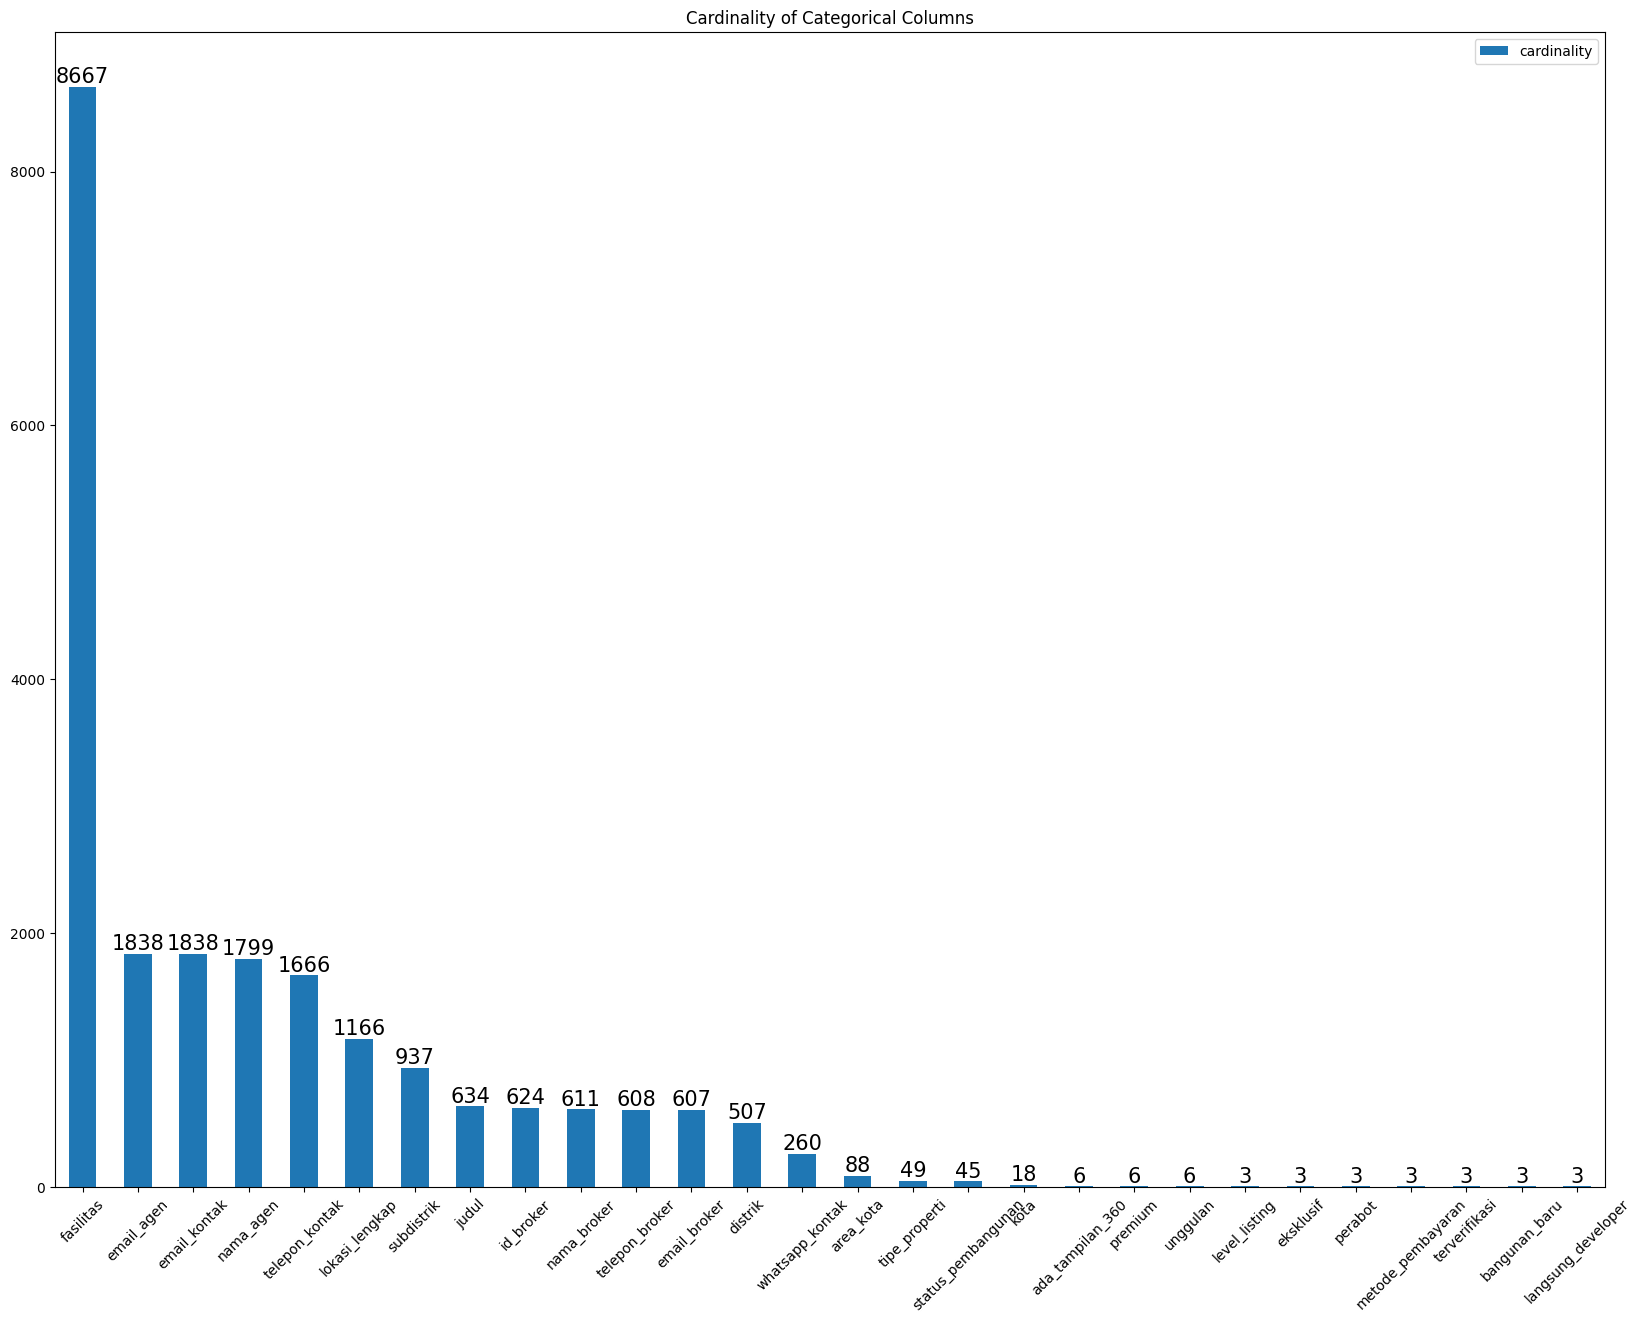

In [16]:
cardinality = {col: train_df[col].nunique() for col in cat_cols}
cardinality_df = pd.DataFrame.from_dict(cardinality, orient="index", columns=["cardinality"]).sort_values(by="cardinality", ascending=False)

cardinality_df.plot(kind="bar", figsize=(20, 15), title="Cardinality of Categorical Columns")
for i, v in enumerate(cardinality_df["cardinality"]):
    plt.text(i, v + 0.5, str(v), ha='center', va='bottom', fontsize=15)
plt.xticks(rotation=45)

for col in cat_cols:
    print(f"Column: {col}, Cardinality: {train_df[col].nunique()}")

### Low Cardinality EDA & Processing

In [17]:
low_cardinality_cols = [col for col in cat_cols if train_df[col].nunique() <= 10]

for col in low_cardinality_cols:
    print(f"Value counts for column '{col}':")
    print(train_df[col].value_counts())
    print(train_df[col].unique())
    print("-" * 50) 

Value counts for column 'eksklusif':
eksklusif
NO       4682
FALSE    4639
0        4541
Name: count, dtype: int64
['FALSE' '0' 'NO']
--------------------------------------------------
Value counts for column 'perabot':
perabot
NO        4848
PARTLY    1185
YES        848
Name: count, dtype: int64
[nan 'NO' 'PARTLY' 'YES']
--------------------------------------------------
Value counts for column 'level_listing':
level_listing
STANDARD    9410
PREMIUM     2319
FEATURED    2133
Name: count, dtype: int64
['STANDARD' 'PREMIUM' 'FEATURED']
--------------------------------------------------
Value counts for column 'premium':
premium
NO       3917
0        3847
FALSE    3779
1         824
YES       762
TRUE      733
Name: count, dtype: int64
['FALSE' '0' 'NO' 'YES' 'TRUE' '1']
--------------------------------------------------
Value counts for column 'terverifikasi':
terverifikasi
0        4626
NO       4619
FALSE    4617
Name: count, dtype: int64
['NO' 'FALSE' '0']
-------------------------

In [18]:
# ---------------------------------------------------------------
# 1. Canonical value sets
# ---------------------------------------------------------------
TRUE_VALS  = {"YES", "TRUE", "1", "Y", "YA"}
FALSE_VALS = {"NO", "FALSE", "0", "N", "TIDAK"}

# ---------------------------------------------------------------
# 2. Columns that should become boolean
# ---------------------------------------------------------------
binary_cols = [
    "eksklusif",
    "premium",
    "terverifikasi",
    "unggulan",
    "bangunan_baru",
    "langsung_developer",
    "ada_tampilan_360",
]

# ---------------------------------------------------------------
# 3. Normalizer: anything → boolean (nullable)
# ---------------------------------------------------------------
def to_boolean(s: pd.Series) -> pd.Series:
    # Keep real NaNs aside
    original_na = s.isna()

    # Normalize string representation
    cleaned = s.astype(str).str.upper().str.strip()

    # Map
    result = pd.Series(pd.NA, index=s.index, dtype="boolean")
    result[cleaned.isin(TRUE_VALS)]  = True
    result[cleaned.isin(FALSE_VALS)] = False
    result[original_na] = pd.NA

    return result

# ---------------------------------------------------------------
# 4. Apply to both train and test
# ---------------------------------------------------------------
for col in binary_cols:
    for df in (train_df, test_df):
        if col in df.columns:
            df[col] = to_boolean(df[col])

# ---------------------------------------------------------------
# 5. Categorical / string columns — normalize case only
# ---------------------------------------------------------------
categorical_cols = ["perabot", "level_listing", "metode_pembayaran"]

for col in categorical_cols:
    for df in (train_df, test_df):
        if col in df.columns:
            df[col] = df[col].astype(str).str.upper().str.strip()
            # restore NaNs that got stringified
            df.loc[df[col].isin(["NAN", "NONE", "", "NULL"]), col] = np.nan

In [19]:
for col in binary_cols:
    if col in train_df.columns:
        print(f"\n=== {col} ===")
        print("train dtype:", train_df[col].dtype)
        print(train_df[col].value_counts(dropna=False))
        print("test dtype:", test_df[col].dtype)
        print(test_df[col].value_counts(dropna=False))

for col in categorical_cols:
    if col in train_df.columns:
        print(f"\n=== {col} ===")
        print(train_df[col].value_counts(dropna=False))


=== eksklusif ===
train dtype: boolean
eksklusif
False    13862
Name: count, dtype: Int64
test dtype: boolean
eksklusif
False    5940
Name: count, dtype: Int64

=== premium ===
train dtype: boolean
premium
False    11543
True      2319
Name: count, dtype: Int64
test dtype: boolean
premium
False    4922
True     1018
Name: count, dtype: Int64

=== terverifikasi ===
train dtype: boolean
terverifikasi
False    13862
Name: count, dtype: Int64
test dtype: boolean
terverifikasi
False    5940
Name: count, dtype: Int64

=== unggulan ===
train dtype: boolean
unggulan
False    11729
True      2133
Name: count, dtype: Int64
test dtype: boolean
unggulan
False    5075
True      865
Name: count, dtype: Int64

=== bangunan_baru ===
train dtype: boolean
bangunan_baru
False    13862
Name: count, dtype: Int64
test dtype: boolean
bangunan_baru
False    5940
Name: count, dtype: Int64

=== langsung_developer ===
train dtype: boolean
langsung_developer
False    13862
Name: count, dtype: Int64
test dtype: b

In [20]:
# Melihat distribusi kardinalitas dari kolom-kolom kategorikal pada low cardinality_cols

low_cardinality_cols = [col for col in cat_cols if train_df[col].nunique() <= 10]

for col in low_cardinality_cols:
    print(f"\n=== {col} ===")
    print("Train Cardinality:", train_df[col].nunique())
    print("Test Cardinality:", test_df[col].nunique())



=== eksklusif ===
Train Cardinality: 1
Test Cardinality: 1

=== perabot ===
Train Cardinality: 3
Test Cardinality: 3

=== level_listing ===
Train Cardinality: 3
Test Cardinality: 3

=== premium ===
Train Cardinality: 2
Test Cardinality: 2

=== terverifikasi ===
Train Cardinality: 1
Test Cardinality: 1

=== unggulan ===
Train Cardinality: 2
Test Cardinality: 2

=== bangunan_baru ===
Train Cardinality: 1
Test Cardinality: 1

=== langsung_developer ===
Train Cardinality: 1
Test Cardinality: 1

=== ada_tampilan_360 ===
Train Cardinality: 2
Test Cardinality: 2

=== metode_pembayaran ===
Train Cardinality: 3
Test Cardinality: 3


In [21]:
# Drop columns with one cardinality
cols_with_one_cardinality = [col for col in train_df.columns if train_df[col].nunique() == 1]
if cols_with_one_cardinality:
    print(f"Dropping columns with one cardinality: {cols_with_one_cardinality}")
    train_df.drop(columns=cols_with_one_cardinality, inplace=True)
    test_df.drop(columns=cols_with_one_cardinality, inplace=True)


Dropping columns with one cardinality: ['eksklusif', 'terverifikasi', 'bangunan_baru', 'langsung_developer']


### High Cardinality EDA & Processing

In [22]:
cat_cols = train_df.select_dtypes(include=["object"]).columns.tolist()

In [23]:
high_cardinality_cols = [col for col in cat_cols if train_df[col].nunique() > 10]

print("High Cardinality Columns:")
for col in high_cardinality_cols:
    print(f"\n=== {col} ===")
    print("Train Cardinality:", train_df[col].nunique())
    print("Test Cardinality:", test_df[col].nunique())

    print("Unique values in train:", train_df[col].unique())
    print("Unique values in test:", test_df[col].unique())

High Cardinality Columns:

=== judul ===
Train Cardinality: 634
Test Cardinality: 464
Unique values in train: ['APARTMENT / COMPLETED / CASH'
 'APARTMENT / OFF_PLAN_PRIMARY / INSTALLMENTS'
 'VILLA / COMPLETED / INSTALLMENTS' 'APARTMENT / OFF_PLAN_PRIMARY / CASH'
 'VILLA / COMPLETED / CASH' 'APARTMENT / COMPLETED_PRIMARY / CASH'
 'APARTMENT / CASH' 'APARTMENT / COMPLETED_PRIMARY'
 'APARTMENT / OFF_PLAN / CASH | INSTALLMENTS'
 'APARTMENT / OFF_PLAN_PRIMARY / CASH | INSTALLMENTS'
 'APARTMENT / COMPLETED_PRIMARY / INSTALLMENTS'
 'TWIN HOUSE / COMPLETED / CASH' 'APARTMENT / OFF_PLAN / CASH'
 'VILLA / OFF_PLAN_PRIMARY / CASH | INSTALLMENTS'
 'APARTMENT  / OFF_PLAN_PRIMARY / INSTALLMENTS' 'VILLA / COMPLETED'
 'APARTMENT / COMPLETED /  CASH' 'VILLA / OFF PLAN PRIMARY / INSTALLMENTS'
 'VILLA / OFF_PLAN_PRIMARY / INSTALLMENTS' 'APARTMENT  / COMPLETED / CASH'
 nan 'PENTHOUSE / COMPLETED / CASH' 'IVILLA / OFF_PLAN / INSTALLMENTS'
 'APARTMENT / COPLETED / CASH'
 'TOWNHOUSE / OFF_PLAN / CASH | INSTA

In [24]:
import re
from difflib import SequenceMatcher
from sklearn.preprocessing import MultiLabelBinarizer


# ================================================================
# SECTION 0 — HELPERS
# ================================================================

def _upper(x):
    if pd.isna(x):
        return np.nan
    return str(x).upper().strip()


def _to_float(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().replace(',', '.')
    try:
        return float(s)
    except ValueError:
        return np.nan


def _ratio(a, b):
    return SequenceMatcher(None, a, b).ratio()


# ================================================================
# SECTION 1 — CANONICAL VOCABULARIES (from your data)
# ================================================================

PROPERTY_TYPE_MAP = {
    'APARTMENT': 'APARTMENT', 'APARTENT': 'APARTMENT', 'APRTMENT': 'APARTMENT',
    'APARMENT': 'APARTMENT', 'APATMENT': 'APARTMENT', 'AARTMENT': 'APARTMENT',
    'APARTMET': 'APARTMENT', 'APARTMNT': 'APARTMENT', 'PARTMENT': 'APARTMENT',
    'VILLA': 'VILLA', 'VILA': 'VILLA', 'VLLA': 'VILLA',
    'IVILLA': 'VILLA', 'IVLLA': 'VILLA',
    'PENTHOUSE': 'PENTHOUSE', 'PENTHOSE': 'PENTHOUSE',
    'PENTHOUE': 'PENTHOUSE', 'PENHOUSE': 'PENTHOUSE',
    'CHALET': 'CHALET', 'CHAET': 'CHALET', 'CHALT': 'CHALET',
    'CHLET': 'CHALET', 'CALET': 'CHALET',
    'TOWNHOUSE': 'TOWNHOUSE', 'TOWNHOUE': 'TOWNHOUSE', 'TOWNOUSE': 'TOWNHOUSE',
    'TWNHOUSE': 'TOWNHOUSE', 'TOWHOUSE': 'TOWNHOUSE', 'TOWNHUSE': 'TOWNHOUSE',
    'TONHOUSE': 'TOWNHOUSE', 'TOWNHOSE': 'TOWNHOUSE',
    'TWIN HOUSE': 'TWIN HOUSE', 'TWIN OUSE': 'TWIN HOUSE',
    'TWN HOUSE': 'TWIN HOUSE', 'TIN HOUSE': 'TWIN HOUSE',
    'TWIN HOSE': 'TWIN HOUSE', 'TWINHOUSE': 'TWIN HOUSE',
    'DUPLEX': 'DUPLEX', 'DUPEX': 'DUPLEX', 'DULEX': 'DUPLEX',
    'DPLEX': 'DUPLEX', 'DUPLX': 'DUPLEX',
    'HOTEL APARTMENT': 'HOTEL APARTMENT', 'HOTEL APATMENT': 'HOTEL APARTMENT',
    'HOTEL APARMENT': 'HOTEL APARTMENT', 'HTEL APARTMENT': 'HOTEL APARTMENT',
    'WHOLE BUILDING': 'WHOLE BUILDING', 'WHOLE BUILDNG': 'WHOLE BUILDING',
    'LAND': 'LAND', 'CABIN': 'CABIN', 'PALACE': 'PALACE', 'ROOF': 'ROOF',
    'BULK SALE UNIT': 'BULK SALE UNIT',
    'HALF FLOOR': 'HALF FLOOR', 'FULL FLOOR': 'FULL FLOOR',
}

PROPERTY_TYPES = set(PROPERTY_TYPE_MAP.values())
STATUSES = {'COMPLETED', 'COMPLETED_PRIMARY', 'OFF_PLAN', 'OFF_PLAN_PRIMARY'}
PAYMENTS = {'CASH', 'INSTALLMENTS', 'CASH | INSTALLMENTS'}

_PRIMARY_TOKENS = {'PRIMARY', 'PRIMRY', 'PRMARY', 'PRIMAY',
                   'PRIARY', 'PIMARY'}


# ================================================================
# SECTION 2 — NORMALIZERS
# ================================================================

def normalize_property_type(x):
    if pd.isna(x):
        return np.nan
    s = re.sub(r'\s+', ' ', _upper(x))
    if s in PROPERTY_TYPE_MAP:
        return PROPERTY_TYPE_MAP[s]
    best, score = None, 0.0
    for k, v in PROPERTY_TYPE_MAP.items():
        r = _ratio(s, k)
        if r > score:
            best, score = v, r
    return best if score >= 0.80 else s


def normalize_status(x):
    if pd.isna(x):
        return np.nan
    s = _upper(x)
    s = re.sub(r'\s+', '_', s)
    s = re.sub(r'_+', '_', s)
    tokens = s.split('_')

    has_primary = any(
        t in _PRIMARY_TOKENS or _ratio(t, 'PRIMARY') > 0.72
        for t in tokens
    )
    joined = ''.join(tokens)
    has_off = (
        s.startswith('OF')
        or 'OFF' in joined
        or 'OFPLAN' in joined
        or 'OF_PLAN' in s
    )
    if has_off:
        return 'OFF_PLAN_PRIMARY' if has_primary else 'OFF_PLAN'
    return 'COMPLETED_PRIMARY' if has_primary else 'COMPLETED'


def normalize_payment(x):
    if pd.isna(x):
        return np.nan
    s = _upper(x).replace('|', ' | ')
    s = re.sub(r'\s+', ' ', s).strip()
    tokens = {t.strip() for t in s.split('|') if t.strip()}
    if tokens == {'CASH'}:
        return 'CASH'
    if tokens == {'INSTALLMENTS'}:
        return 'INSTALLMENTS'
    if tokens == {'CASH', 'INSTALLMENTS'}:
        return 'CASH | INSTALLMENTS'
    return ' | '.join(sorted(tokens)) if tokens else np.nan


def clean_location_code(x):
    if pd.isna(x):
        return np.nan
    return re.sub(r'\s+', '_', str(x).upper().strip())


def clean_count(x, suffix_regex):
    if pd.isna(x):
        return np.nan
    s = _upper(x)
    if s in {'STUDIO'}:
        return 0.0
    if s in {'NONE', 'NAN', 'NA', '', 'N/A'}:
        return np.nan
    s = re.sub(suffix_regex, '', s).strip().replace('+', '').strip()
    if not s:
        return np.nan
    try:
        return float(s)
    except ValueError:
        return np.nan


def clean_luas(x):
    if pd.isna(x):
        return np.nan
    s = _upper(x).replace('M²', '').replace('M2', '').replace(',', '.')
    s = re.sub(r'[^0-9.\-]', '', s).strip()
    if not s or s == '.':
        return np.nan
    try:
        return float(s)
    except ValueError:
        return np.nan


def clean_fasilitas(x):
    if pd.isna(x):
        return np.nan
    parts = re.split(r'[|,;]', str(x))
    parts = [re.sub(r'\s+', '_', p.strip().upper()) for p in parts if p.strip()]
    seen, ordered = set(), []
    for p in parts:
        if p not in seen:
            seen.add(p)
            ordered.append(p)
    return ' | '.join(sorted(ordered)) if ordered else np.nan


# ================================================================
# SECTION 3 — BOOLEAN COLUMNS (nullable boolean dtype)
# ================================================================

TRUE_VALS  = {"YES", "TRUE", "1", "Y", "YA"}
FALSE_VALS = {"NO", "FALSE", "0", "N", "TIDAK"}

BINARY_COLS = [
    "eksklusif", "premium", "terverifikasi", "unggulan",
    "bangunan_baru", "langsung_developer", "ada_tampilan_360",
]


def to_boolean(s):
    original_na = s.isna()
    cleaned = s.astype(str).str.upper().str.strip()
    result = pd.Series(pd.NA, index=s.index, dtype="boolean")
    result[cleaned.isin(TRUE_VALS)]  = True
    result[cleaned.isin(FALSE_VALS)] = False
    result[original_na] = pd.NA
    return result


# ================================================================
# SECTION 4 — SPLIT JUDUL & LOKASI_LENGKAP
# ================================================================

def _classify_judul_part(p):
    if p in PROPERTY_TYPES:
        return 'type'
    if p in STATUSES:
        return 'status'
    if p in PAYMENTS:
        return 'payment'
    return None


def split_judul(value):
    if pd.isna(value):
        return (np.nan, np.nan, np.nan)
    parts = [p.strip() for p in str(value).split('/') if p.strip()]
    tipe = status = bayar = np.nan
    for p in parts:
        role = _classify_judul_part(p)
        if role == 'type' and pd.isna(tipe):
            tipe = p
        elif role == 'status' and pd.isna(status):
            status = p
        elif role == 'payment' and pd.isna(bayar):
            bayar = p
    return (tipe, status, bayar)


def expand_judul(df, col='judul'):
    if col not in df.columns:
        return df
    parts = df[col].apply(split_judul)
    df['judul_tipe']       = [p[0] for p in parts]
    df['judul_status']     = [p[1] for p in parts]
    df['judul_pembayaran'] = [p[2] for p in parts]
    return df.drop(columns=[col])


def split_lokasi(value):
    out = [np.nan, np.nan, np.nan, np.nan]
    if pd.isna(value):
        return tuple(out)
    parts = [p.strip() for p in str(value).split('/') if p.strip()]
    for i, p in enumerate(parts[:4]):
        out[i] = p
    return tuple(out)


def expand_lokasi(df, col='lokasi_lengkap'):
    if col not in df.columns:
        return df
    parts = df[col].apply(split_lokasi)
    df['lok_kota']       = [p[0] for p in parts]
    df['lok_area_kota']  = [p[1] for p in parts]
    df['lok_distrik']    = [p[2] for p in parts]
    df['lok_subdistrik'] = [p[3] for p in parts]
    return df.drop(columns=[col])


def _same_series(a, b):
    return a.fillna('__NA__').equals(b.fillna('__NA__'))


def drop_if_redundant(df, pairs):
    to_drop = []
    for s_col, d_col in pairs:
        if s_col in df.columns and d_col in df.columns:
            if _same_series(df[s_col], df[d_col]):
                to_drop.append(s_col)
    return df.drop(columns=to_drop, errors='ignore')


# ================================================================
# SECTION 5 — MAIN CLEANING FUNCTION
# ================================================================

def clean_dataframe(df):
    df = df.copy()

    # -- trim whitespace on every object column first --
    for c in df.select_dtypes(include=['object']).columns:
        df[c] = df[c].apply(lambda v: v.strip() if isinstance(v, str) else v)

    # -- judul --
    if 'judul' in df.columns:
        df['judul'] = df['judul'].apply(
            lambda v: str(v).strip() if isinstance(v, str) else v
        )

    # -- location codes --
    for col in ['kota', 'area_kota', 'distrik', 'subdistrik']:
        if col in df.columns:
            df[col] = df[col].apply(clean_location_code)

    # -- coordinates --
    for col in ['lintang', 'bujur']:
        if col in df.columns:
            df[col] = df[col].apply(_to_float)

    # -- property type --
    if 'tipe_properti' in df.columns:
        df['tipe_properti'] = df['tipe_properti'].apply(normalize_property_type)

    # -- status --
    if 'status_pembangunan' in df.columns:
        df['status_pembangunan'] = df['status_pembangunan'].apply(normalize_status)

    # -- payment --
    if 'metode_pembayaran' in df.columns:
        df['metode_pembayaran'] = df['metode_pembayaran'].apply(normalize_payment)

    # -- counts --
    if 'kamar_tidur' in df.columns:
        df['kamar_tidur'] = df['kamar_tidur'].apply(
            lambda x: clean_count(x, r'\s*BEDROOMS?\s*'))
    if 'kamar_mandi' in df.columns:
        df['kamar_mandi'] = df['kamar_mandi'].apply(
            lambda x: clean_count(x, r'\s*BATHS?\s*'))
    if 'jumlah_foto' in df.columns:
        df['jumlah_foto'] = df['jumlah_foto'].apply(
            lambda x: clean_count(x, r'\s*PHOTOS?\s*'))

    # -- luas --
    if 'luas' in df.columns:
        df['luas'] = df['luas'].apply(clean_luas)

    # -- fasilitas --
    if 'fasilitas' in df.columns:
        df['fasilitas'] = df['fasilitas'].apply(clean_fasilitas)

    # -- identifiers / emails (UPPERCASE — as you requested) --
    for col in ['nama_agen', 'nama_broker', 'id_broker']:
        if col in df.columns:
            df[col] = df[col].apply(_upper)

    for col in ['email_agen', 'email_broker', 'email_kontak']:
        if col in df.columns:
            df[col] = df[col].apply(
                lambda v: str(v).upper().strip() if isinstance(v, str) else v
            )

    # -- booleans --
    for col in BINARY_COLS:
        if col in df.columns:
            df[col] = to_boolean(df[col])

    # -- nullable integer for counts --
    for col in ['kamar_tidur', 'kamar_mandi', 'jumlah_foto']:
        if col in df.columns:
            df[col] = df[col].round().astype('Int64')

    return df


# ================================================================
# SECTION 6 — APPLY CLEANING
# ================================================================

train_df = clean_dataframe(train_df)
test_df  = clean_dataframe(test_df)


# ================================================================
# SECTION 7 — SPLIT judul & lokasi_lengkap
# ================================================================

train_df = expand_judul(train_df)
test_df  = expand_judul(test_df)

train_df = expand_lokasi(train_df)
test_df  = expand_lokasi(test_df)


# ================================================================
# SECTION 8 — VERIFY & DROP REDUNDANT SPLIT COLUMNS
# ================================================================

judul_pairs = [
    ('judul_tipe',       'tipe_properti'),
    ('judul_status',     'status_pembangunan'),
    ('judul_pembayaran', 'metode_pembayaran'),
]
lokasi_pairs = [
    ('lok_kota',       'kota'),
    ('lok_area_kota',  'area_kota'),
    ('lok_distrik',    'distrik'),
    ('lok_subdistrik', 'subdistrik'),
]

train_df = drop_if_redundant(train_df, judul_pairs + lokasi_pairs)
test_df  = drop_if_redundant(test_df,  judul_pairs + lokasi_pairs)


# ================================================================
# SECTION 9 — RECONCILE TRAIN/TEST CATEGORIES
# ================================================================

LOW_CARD_COLS = ['tipe_properti', 'status_pembangunan', 'metode_pembayaran',
                 'kota', 'area_kota']

for col in LOW_CARD_COLS:
    if col in train_df.columns and col in test_df.columns:
        known = set(train_df[col].dropna().unique())
        mask = ~test_df[col].isin(known) & test_df[col].notna()
        n_fixed = int(mask.sum())
        if n_fixed:
            test_df.loc[mask, col] = 'UNKNOWN'
            print(f"  [align] {col}: {n_fixed} unseen test values → 'UNKNOWN'")


# ================================================================
# SECTION 10 — FREQUENCY-ENCODE IDENTIFIERS + HIGH-CARD LOCATIONS
# ================================================================

FREQ_COLS = [
    'nama_agen', 'nama_broker',
    'email_agen', 'email_broker', 'email_kontak',
    'id_broker',
    'distrik', 'subdistrik',
]

for col in FREQ_COLS:
    if col not in train_df.columns:
        continue
    freq = train_df[col].value_counts(normalize=True)
    train_df[f'{col}_freq'] = train_df[col].map(freq).fillna(0.0).astype('float32')
    test_df[f'{col}_freq']  = test_df[col].map(freq).fillna(0.0).astype('float32')


# ================================================================
# SECTION 11 — DROP RAW IDENTIFIERS + GRANULAR LOCATIONS
# ================================================================

DROP_RAW = [
    'nama_agen', 'nama_broker',
    'email_agen', 'email_broker', 'email_kontak',
    'id_broker',
    'distrik', 'subdistrik',
]

train_df.drop(columns=[c for c in DROP_RAW if c in train_df.columns],
              inplace=True, errors='ignore')
test_df.drop(columns=[c for c in DROP_RAW if c in test_df.columns],
             inplace=True, errors='ignore')


# ================================================================
# SECTION 12 — MULTI-HOT fasilitas
# ================================================================

def _split_fas(x):
    if pd.isna(x):
        return []
    return [p.strip() for p in str(x).split('|') if p.strip()]

if 'fasilitas' in train_df.columns:
    mlb = MultiLabelBinarizer()
    tr_fas = pd.DataFrame(
        mlb.fit_transform(train_df['fasilitas'].apply(_split_fas)),
        columns=[f'fas_{c}' for c in mlb.classes_],
        index=train_df.index,
    ).astype('int8')
    te_fas = pd.DataFrame(
        mlb.transform(test_df['fasilitas'].apply(_split_fas)),
        columns=[f'fas_{c}' for c in mlb.classes_],
        index=test_df.index,
    ).astype('int8')

    train_df = pd.concat([train_df.drop(columns=['fasilitas']), tr_fas], axis=1)
    test_df  = pd.concat([test_df.drop(columns=['fasilitas']),  te_fas], axis=1)
    print(f"\n[fasilitas] expanded into {len(mlb.classes_)} binary columns")


# ================================================================
# SECTION 13 — FINAL SANITY CHECK
# ================================================================

print("\n" + "=" * 70)
print(f"FINAL  TRAIN shape = {train_df.shape}   TEST shape = {test_df.shape}")
print("=" * 70)

print("\nRemaining object columns (cardinality):")
for c in sorted(train_df.select_dtypes(include='object').columns):
    tr_n = train_df[c].nunique(dropna=True)
    te_n = test_df[c].nunique(dropna=True) if c in test_df.columns else 0
    flag = "!!" if tr_n > 50 else "OK"
    print(f"  [{flag}] {c:25s} train={tr_n:5d}  test={te_n:5d}")

print("\nData type summary:")
print(train_df.dtypes.value_counts().to_string())

print("\nAll final columns:")
for c in sorted(train_df.columns):
    print(f"  {c}")

  [align] tipe_properti: 1 unseen test values → 'UNKNOWN'
  [align] area_kota: 1 unseen test values → 'UNKNOWN'

[fasilitas] expanded into 8 binary columns

FINAL  TRAIN shape = (13862, 43)   TEST shape = (5940, 42)

Remaining object columns (cardinality):
  [!!] area_kota                 train=   61  test=   52
  [OK] judul_pembayaran          train=    3  test=    3
  [OK] judul_status              train=    4  test=    4
  [OK] judul_tipe                train=   14  test=   16
  [OK] kota                      train=   12  test=   10
  [OK] level_listing             train=    3  test=    3
  [!!] lok_distrik               train=  430  test=  322
  [!!] lok_subdistrik            train=  835  test=  591
  [OK] metode_pembayaran         train=    3  test=    3
  [OK] perabot                   train=    3  test=    3
  [OK] status_pembangunan        train=    4  test=    4
  [!!] telepon_broker            train=  608  test=  513
  [!!] telepon_kontak            train= 1666  test= 1243
  

In [25]:
cat_cols = train_df.select_dtypes(include=["object"]).columns.tolist()
high_cardinality_cols = [col for col in cat_cols if train_df[col].nunique() > 10]

print("High Cardinality Columns:")
for col in high_cardinality_cols:
    print(f"\n=== {col} ===")
    print("Train Cardinality:", train_df[col].nunique())
    print("Test Cardinality:", test_df[col].nunique())

    print("Unique values in train:", train_df[col].unique())
    print("Unique values in test:", test_df[col].unique())

High Cardinality Columns:

=== kota ===
Train Cardinality: 12
Test Cardinality: 10
Unique values in train: ['Z1_0006' 'Z1_0009' 'Z1_0003' nan 'Z1_0011' 'Z1_0012' 'Z1_0008' 'Z1_0001'
 'Z1_0004' 'Z1_0007' 'Z1_0010' 'Z1_0005' 'Z1_0002']
Unique values in test: ['Z1_0006' nan 'Z1_0009' 'Z1_0001' 'Z1_0011' 'Z1_0003' 'Z1_0012' 'Z1_0004'
 'Z1_0008' 'Z1_0005' 'Z1_0007']

=== area_kota ===
Train Cardinality: 61
Test Cardinality: 52
Unique values in train: ['Z2_0004' 'Z2_0032' 'Z2_0018' 'Z2_0050' 'Z2_0014' nan 'Z2_0044' 'Z2_0027'
 'Z2_0034' 'Z2_0008' 'Z2_0057' 'Z2_0002' 'Z2_0005' 'Z2_0020' 'Z2_0023'
 'Z2_0054' 'Z2_0046' 'Z2_0025' 'Z2_0003' 'Z2_0049' 'Z2_0041' 'Z2_0061'
 'Z2_0029' 'Z2_0038' 'Z2_0017' 'Z2_0019' 'Z2_0040' 'Z2_0052' 'Z2_0058'
 'Z2_0051' 'Z2_0033' 'Z2_0024' 'Z2_0062' 'Z2_0012' 'Z2_0013' 'Z2_0009'
 'Z2_0053' 'Z2_0047' 'Z2_0010' 'Z2_0007' 'Z2_0039' 'Z2_0045' 'Z2_0035'
 'Z2_0056' 'Z2_0037' 'Z2_0026' 'Z2_0060' 'Z2_0030' 'Z2_0022' 'Z2_0031'
 'Z2_0021' 'Z2_0042' 'Z2_0036' 'Z2_0043' 'Z2_0048

In [26]:
# ================================================================
# SECTION 12 — EXTRACT `fasilitas` AS YES/NO BINARY FEATURES
# ================================================================

def _tokenize_fas(value):
    """Split an amenity string on '|', ',', or ';' → list of UPPER tokens."""
    if pd.isna(value):
        return []
    parts = re.split(r'[|,;]', str(value))
    return [p.strip().upper().replace(' ', '_')
            for p in parts if p.strip()]


def make_binary_features(train_df, test_df, col, prefix):
    """
    For every unique token found in `col` across BOTH DataFrames,
    create a `{prefix}__{TOKEN}` column with 'YES' / 'NO'.
    """
    if col not in train_df.columns:
        print(f"[skip] '{col}' not in train_df — nothing to extract")
        return train_df, test_df

    # --- build vocabulary from BOTH frames ---
    vocab = set()
    for df in (train_df, test_df):
        if col in df.columns:
            for v in df[col].dropna():
                vocab.update(_tokenize_fas(v))
    vocab = sorted(vocab)

    print(f"\n[{col}] found {len(vocab)} unique tokens:")
    for t in vocab:
        print(f"   - {t}")

    # --- build YES/NO flags ---
    for df in (train_df, test_df):
        if col not in df.columns:
            continue
        token_sets = df[col].apply(
            lambda v: set(_tokenize_fas(v)) if not pd.isna(v) else set()
        )
        for tok in vocab:
            fname = f"{prefix}__{tok}"
            df[fname] = token_sets.apply(
                lambda s, t=tok: 'YES' if t in s else 'NO'
            )

    return train_df, test_df


# apply to `fasilitas`
train_df, test_df = make_binary_features(
    train_df, test_df, col='fasilitas', prefix='fas'
)

# drop the raw string column
train_df.drop(columns=['fasilitas'], inplace=True, errors='ignore')
test_df.drop(columns=['fasilitas'],  inplace=True, errors='ignore')

print(f"\n[fasilitas] extraction complete.")
new_fas_cols = [c for c in train_df.columns if c.startswith('fas__')]
print(f"  → created {len(new_fas_cols)} new YES/NO columns:")
for c in new_fas_cols:
    n_yes = int((train_df[c] == 'YES').sum())
    print(f"      {c:25s}  YES={n_yes:5d}")

[skip] 'fasilitas' not in train_df — nothing to extract

[fasilitas] extraction complete.
  → created 0 new YES/NO columns:


In [27]:
cat_cols = train_df.select_dtypes(include=["object"]).columns.tolist()
high_cardinality_cols = [col for col in cat_cols if train_df[col].nunique() > 10]

for col in ['email_agen', 'email_broker', 'email_kontak']:
    for df in (train_df, test_df):
        if col in df.columns:
            df[col] = df[col].str.upper().str.strip()

print("High Cardinality Columns:")
for col in high_cardinality_cols:
    print(f"\n=== {col} ===")
    print("Train Cardinality:", train_df[col].nunique())
    print("Test Cardinality:", test_df[col].nunique())

    print("Unique values in train:", train_df[col].unique())
    print("Unique values in test:", test_df[col].unique())

High Cardinality Columns:

=== kota ===
Train Cardinality: 12
Test Cardinality: 10
Unique values in train: ['Z1_0006' 'Z1_0009' 'Z1_0003' nan 'Z1_0011' 'Z1_0012' 'Z1_0008' 'Z1_0001'
 'Z1_0004' 'Z1_0007' 'Z1_0010' 'Z1_0005' 'Z1_0002']
Unique values in test: ['Z1_0006' nan 'Z1_0009' 'Z1_0001' 'Z1_0011' 'Z1_0003' 'Z1_0012' 'Z1_0004'
 'Z1_0008' 'Z1_0005' 'Z1_0007']

=== area_kota ===
Train Cardinality: 61
Test Cardinality: 52
Unique values in train: ['Z2_0004' 'Z2_0032' 'Z2_0018' 'Z2_0050' 'Z2_0014' nan 'Z2_0044' 'Z2_0027'
 'Z2_0034' 'Z2_0008' 'Z2_0057' 'Z2_0002' 'Z2_0005' 'Z2_0020' 'Z2_0023'
 'Z2_0054' 'Z2_0046' 'Z2_0025' 'Z2_0003' 'Z2_0049' 'Z2_0041' 'Z2_0061'
 'Z2_0029' 'Z2_0038' 'Z2_0017' 'Z2_0019' 'Z2_0040' 'Z2_0052' 'Z2_0058'
 'Z2_0051' 'Z2_0033' 'Z2_0024' 'Z2_0062' 'Z2_0012' 'Z2_0013' 'Z2_0009'
 'Z2_0053' 'Z2_0047' 'Z2_0010' 'Z2_0007' 'Z2_0039' 'Z2_0045' 'Z2_0035'
 'Z2_0056' 'Z2_0037' 'Z2_0026' 'Z2_0060' 'Z2_0030' 'Z2_0022' 'Z2_0031'
 'Z2_0021' 'Z2_0042' 'Z2_0036' 'Z2_0043' 'Z2_0048

In [28]:
train_df.head()

,kota,area_kota,lintang,bujur,tipe_properti,kamar_tidur,kamar_mandi,luas,perabot,status_pembangunan,...,distrik_freq,subdistrik_freq,fas_EQUIPMENT,fas_EXTRA_ROOM,fas_FITNESS,fas_OUTDOOR,fas_PARKING,fas_POOL,fas_SECURITY,fas_STORAGE
id,,,,,,,,,,,,,,,,,,,,,
1,Z1_0006,Z2_0004,30.03,31.55,APARTMENT,2,3,145.5,NaN,COMPLETED,...,0.241428,0.262192,0,1,1,1,1,1,1,1
2,Z1_0009,Z2_0032,27.13,33.83,APARTMENT,2,1,97.3,NO,OFF_PLAN_PRIMARY,...,0.016766,0.008213,0,0,1,1,1,1,1,0
3,Z1_0006,Z2_0004,30.07,31.60,APARTMENT,2,3,139.1,NaN,COMPLETED,...,0.241428,0.262192,0,0,0,1,0,0,1,0
4,Z1_0006,Z2_0004,30.04,31.54,VILLA,<NA>,<NA>,NaN,NaN,COMPLETED,...,0.241428,0.000000,0,0,0,1,1,0,1,1
5,Z1_0006,Z2_0004,29.99,31.56,APARTMENT,3,2,171.5,NO,OFF_PLAN_PRIMARY,...,0.000000,0.000000,0,0,0,0,0,0,0,0


### Giving the Ordinal Property

In [29]:
# Make the other cols from it have ordinal values, and then we can use them as features in our model. For example, we can map the "level_listing" column to ordinal values based on the following mapping:
from scipy import stats
from sklearn.feature_selection import mutual_info_regression


# ================================================================
# 1. DETECT TARGET COLUMN
# ================================================================

# adjust if your target has a different name
TARGET_CANDIDATES = ['harga', 'price', 'HARGA', 'PRICE', 'target', 'y']

target_col = next((c for c in TARGET_CANDIDATES if c in train_df.columns), None)
if target_col is None:
    raise ValueError(f"No target column found. Looked for: {TARGET_CANDIDATES}")

print(f"Target column: '{target_col}'")
y = train_df[target_col]
print(f"  dtype={y.dtype}  min={y.min()}  max={y.max()}  nan={y.isna().sum()}")

# drop rows with missing target for ranking
mask_y = y.notna()
y = y[mask_y]


# ================================================================
# 2. HANDLE TERNARY (3-VALUE) COLUMNS
# ================================================================

# These are the exactly-3-level categoricals found in your report
TERNARY_ORDINAL = {
    # ordered (ordinal): low < medium < high
    'perabot':          {'NO': 0, 'PARTLY': 1, 'YES': 2},
    'level_listing':    {'STANDARD': 0, 'PREMIUM': 1, 'FEATURED': 2},
}

TERNARY_NOMINAL = [
    # 3 distinct categories, no natural order
    'metode_pembayaran',
]

print("\n[ternary handling]")
for col, mapping in TERNARY_ORDINAL.items():
    for df in (train_df, test_df):
        if col in df.columns:
            df[f'{col}_ord'] = df[col].map(mapping).astype('Int8')
    print(f"  + {col}_ord        (ordinal: {mapping})")

for col in TERNARY_NOMINAL:
    for df in (train_df, test_df):
        if col in df.columns:
            df[f'{col}_is_CASH']  = (df[col] == 'CASH').astype('Int8')
            df[f'{col}_is_INST']  = (df[col] == 'INSTALLMENTS').astype('Int8')
            df[f'{col}_is_BOTH']  = (df[col] == 'CASH | INSTALLMENTS').astype('Int8')
    print(f"  + {col}_is_*       (one-hot into 3 binary flags)")

# drop the raw string ternary columns
for col in list(TERNARY_ORDINAL) + TERNARY_NOMINAL:
    train_df.drop(columns=[col], inplace=True, errors='ignore')
    test_df.drop(columns=[col],  inplace=True, errors='ignore')


# ================================================================
# 3. DROP ZERO-VARIANCE COLUMNS
# ================================================================

zero_var = []
for c in train_df.columns:
    if c == target_col:
        continue
    if c not in test_df.columns:
        continue
    s = train_df[c]
    # for boolean: check if all same
    if s.dtype.name == 'boolean' or s.dtype == bool:
        if s.nunique(dropna=True) <= 1 and test_df[c].nunique(dropna=True) <= 1:
            zero_var.append(c)
    # for numeric: check constant
    elif pd.api.types.is_numeric_dtype(s):
        if s.nunique(dropna=True) <= 1 and test_df[c].nunique(dropna=True) <= 1:
            zero_var.append(c)
    # for object: check constant
    elif s.nunique(dropna=True) <= 1 and test_df[c].nunique(dropna=True) <= 1:
        zero_var.append(c)

print(f"\n[zero-variance] dropping {len(zero_var)} columns:")
for c in zero_var:
    print(f"   - {c}")

train_df.drop(columns=zero_var, inplace=True, errors='ignore')
test_df.drop(columns=[c for c in zero_var if c in test_df.columns],
             inplace=True, errors='ignore')


# ================================================================
# 4. RANK ALL FEATURES BY EFFECT ON PRICE
# ================================================================

def eta_squared(cat_series, y_series):
    """Correlation ratio η² for categorical vs numeric — 0 to 1."""
    df = pd.DataFrame({'x': cat_series, 'y': y_series}).dropna()
    if df['x'].nunique() < 2 or len(df) < 10:
        return np.nan
    grand_mean = df['y'].mean()
    ss_total = ((df['y'] - grand_mean) ** 2).sum()
    if ss_total == 0:
        return 0.0
    ss_between = df.groupby('x')['y'].apply(
        lambda g: len(g) * (g.mean() - grand_mean) ** 2
    ).sum()
    return float(ss_between / ss_total)


def rank_features(train_df, target_col):
    """Return a DataFrame of features ranked by predictive strength."""

    y = train_df[target_col]
    mask = y.notna()
    y = y[mask]

    rows = []
    for col in train_df.columns:
        if col == target_col:
            continue

        x = train_df.loc[mask, col]

        # skip all-missing
        if x.notna().sum() < 10:
            continue

        is_num = pd.api.types.is_numeric_dtype(x) and x.dtype.name not in ('boolean',)
        is_bool = x.dtype.name == 'boolean' or x.dtype == bool
        is_cat = not (is_num or is_bool)

        # ---------- numeric feature ----------
        if is_num:
            xf = pd.to_numeric(x, errors='coerce')
            valid = xf.notna() & y.notna()
            if valid.sum() < 10:
                continue
            pearson_r, pearson_p = stats.pearsonr(xf[valid], y[valid])
            spearman_r, _       = stats.spearmanr(xf[valid], y[valid])
            rows.append({
                'feature': col,
                'type': 'numeric',
                'n_unique': int(xf.nunique(dropna=True)),
                'pearson_abs': abs(pearson_r),
                'spearman_abs': abs(spearman_r),
                'eta_squared': np.nan,
                'mutual_info': np.nan,
            })

        # ---------- boolean feature ----------
        elif is_bool:
            xb = x.astype('float').replace({pd.NA: np.nan})
            valid = xb.notna() & y.notna()
            if valid.sum() < 10 or xb[valid].nunique() < 2:
                continue
            eta = eta_squared(xb[valid].astype(int), y[valid])
            t_stat, _ = stats.ttest_ind(
                y[valid][xb[valid] == 1],
                y[valid][xb[valid] == 0],
                equal_var=False,
            )
            rows.append({
                'feature': col,
                'type': 'boolean',
                'n_unique': int(xb[valid].nunique()),
                'pearson_abs': np.nan,
                'spearman_abs': np.nan,
                'eta_squared': eta,
                'mutual_info': np.nan,
            })

        # ---------- categorical feature ----------
        else:
            xc = x.astype(str)
            valid = xc.notna() & y.notna()
            if valid.sum() < 10 or xc[valid].nunique() < 2:
                continue
            eta = eta_squared(xc[valid], y[valid])
            rows.append({
                'feature': col,
                'type': 'categorical',
                'n_unique': int(xc[valid].nunique()),
                'pearson_abs': np.nan,
                'spearman_abs': np.nan,
                'eta_squared': eta,
                'mutual_info': np.nan,
            })

    result = pd.DataFrame(rows)

    # ---------- mutual information (works for all dtypes) ----------
    feature_cols = result['feature'].tolist()
    X_all = train_df.loc[mask, feature_cols].copy()
    for c in X_all.columns:
        if X_all[c].dtype.name == 'boolean':
            X_all[c] = X_all[c].astype('float').replace({pd.NA: np.nan})
        elif X_all[c].dtype == 'object' or str(X_all[c].dtype) == 'string':
            X_all[c] = X_all[c].astype('category').cat.codes.replace(-1, np.nan)
        else:
            X_all[c] = pd.to_numeric(X_all[c], errors='coerce')

    mi = mutual_info_regression(
        X_all.fillna(X_all.median(numeric_only=True)).fillna(0),
        y,
        random_state=42,
    )
    result['mutual_info'] = mi

    # ---------- combined score ----------
    # normalize each metric to [0,1] and average
    def norm(s):
        if s.notna().sum() == 0:
            return pd.Series(0, index=s.index)
        lo, hi = s.min(), s.max()
        if hi == lo:
            return pd.Series(0, index=s.index)
        return (s - lo) / (hi - lo)

    result['score'] = (
        norm(result['mutual_info']).fillna(0) * 0.5
        + norm(result['eta_squared']).fillna(0) * 0.3
        + norm(result['pearson_abs']).fillna(0) * 0.1
        + norm(result['spearman_abs']).fillna(0) * 0.1
    )

    result = result.sort_values('score', ascending=False).reset_index(drop=True)
    result.insert(0, 'rank', range(1, len(result) + 1))

    return result


ranking = rank_features(train_df, target_col)

print("\n" + "=" * 100)
print(f"FEATURE RANKING BY EFFECT ON '{target_col}'  (higher score = stronger effect)")
print("=" * 100)
print(ranking.to_string(index=False))


# ================================================================
# 5. TOP-K SELECTION
# ================================================================

TOP_K = 30
top_features = ranking.head(TOP_K)['feature'].tolist()

print(f"\nTop {TOP_K} features:")
for i, f in enumerate(top_features, 1):
    print(f"  {i:2d}. {f}")

# optional: save list
with open('top_features.txt', 'w') as fh:
    for f in top_features:
        fh.write(f + '\n')

print(f"\nSaved to top_features.txt")


# ================================================================
# 6. VERIFY TERNARY COLUMNS ARE NOW 3-WAY BINARY
# ================================================================

print("\n" + "=" * 60)
print("TERNARY COLUMNS — final form")
print("=" * 60)
for c in ['perabot_ord', 'level_listing_ord',
          'metode_pembayaran_is_CASH',
          'metode_pembayaran_is_INST',
          'metode_pembayaran_is_BOTH']:
    if c in train_df.columns:
        print(f"  {c:35s}  nunique={train_df[c].nunique(dropna=True)}  "
              f"nan={train_df[c].isna().sum()}")

Target column: 'harga'
  dtype=float64  min=113116.0  max=1000000000.0  nan=0

[ternary handling]
  + perabot_ord        (ordinal: {'NO': 0, 'PARTLY': 1, 'YES': 2})
  + level_listing_ord        (ordinal: {'STANDARD': 0, 'PREMIUM': 1, 'FEATURED': 2})
  + metode_pembayaran_is_*       (one-hot into 3 binary flags)

[zero-variance] dropping 0 columns:

FEATURE RANKING BY EFFECT ON 'harga'  (higher score = stronger effect)
 rank                   feature        type  n_unique  pearson_abs  spearman_abs  eta_squared  mutual_info    score
    1            telepon_kontak categorical      1666          NaN           NaN     0.288117     0.393015 0.691428
    2            telepon_broker categorical       608          NaN           NaN     0.202615     0.478920 0.687865
    3                      luas     numeric      3667     0.370304      0.711786          NaN     0.433826 0.632074
    4             tipe_properti categorical        15          NaN           NaN     0.205131     0.324859 0.53704

In [30]:
display(train_df.head())
display(test_df.head())

,kota,area_kota,lintang,bujur,tipe_properti,kamar_tidur,kamar_mandi,luas,status_pembangunan,premium,...,fas_OUTDOOR,fas_PARKING,fas_POOL,fas_SECURITY,fas_STORAGE,perabot_ord,level_listing_ord,metode_pembayaran_is_CASH,metode_pembayaran_is_INST,metode_pembayaran_is_BOTH
id,,,,,,,,,,,,,,,,,,,,,
1,Z1_0006,Z2_0004,30.03,31.55,APARTMENT,2,3,145.5,COMPLETED,False,...,1,1,1,1,1,<NA>,0,1,0,0
2,Z1_0009,Z2_0032,27.13,33.83,APARTMENT,2,1,97.3,OFF_PLAN_PRIMARY,False,...,1,1,1,1,0,0,0,0,1,0
3,Z1_0006,Z2_0004,30.07,31.60,APARTMENT,2,3,139.1,COMPLETED,False,...,1,0,0,1,0,<NA>,0,1,0,0
4,Z1_0006,Z2_0004,30.04,31.54,VILLA,<NA>,<NA>,NaN,COMPLETED,False,...,1,1,0,1,1,<NA>,0,0,1,0
5,Z1_0006,Z2_0004,29.99,31.56,APARTMENT,3,2,171.5,OFF_PLAN_PRIMARY,False,...,0,0,0,0,0,0,0,1,0,0


,kota,area_kota,lintang,bujur,tipe_properti,kamar_tidur,kamar_mandi,luas,status_pembangunan,premium,...,fas_OUTDOOR,fas_PARKING,fas_POOL,fas_SECURITY,fas_STORAGE,perabot_ord,level_listing_ord,metode_pembayaran_is_CASH,metode_pembayaran_is_INST,metode_pembayaran_is_BOTH
id,,,,,,,,,,,,,,,,,,,,,
14417,Z1_0006,Z2_0004,30.06,31.45,APARTMENT,3,3,159.0,COMPLETED,False,...,1,1,0,1,1,0,0,1,0,0
14418,NaN,NaN,NaN,NaN,APARTMENT,2,<NA>,18.7,COMPLETED_PRIMARY,False,...,1,1,1,1,1,<NA>,0,1,0,0
14419,Z1_0006,Z2_0004,30.03,31.54,APARTMENT,3,3,NaN,COMPLETED,False,...,0,0,1,1,0,0,0,1,0,0
14420,Z1_0006,Z2_0004,30.05,31.51,APARTMENT,3,3,194.7,OFF_PLAN_PRIMARY,False,...,1,0,0,1,0,<NA>,0,1,0,0
14421,NaN,NaN,NaN,NaN,CHALET,1,1,61.4,OFF_PLAN_PRIMARY,False,...,1,1,1,1,1,2,0,0,0,1


# Numerical EDA

In [31]:
num_cols = train_df.select_dtypes(include=[int,float]).columns.tolist()
num_cols

['lintang',
 'bujur',
 'kamar_tidur',
 'kamar_mandi',
 'luas',
 'jumlah_foto',
 'harga',
 'bulan',
 'tahun',
 'nama_agen_freq',
 'nama_broker_freq',
 'email_agen_freq',
 'email_broker_freq',
 'email_kontak_freq',
 'id_broker_freq',
 'distrik_freq',
 'subdistrik_freq']

EDA — EXPLORATORY DATA ANALYSIS

SECTION 1 — DATASET OVERVIEW

--- TRAIN ---
Shape          : 13,862 rows × 45 columns
Memory usage   : 11.97 MB
Duplicate rows : 1
Columns:
    kota                      dtype=object     nunique=    12
    area_kota                 dtype=object     nunique=    61
    lintang                   dtype=float64    nunique=   196
    bujur                     dtype=float64    nunique=   345
    tipe_properti             dtype=object     nunique=    15
    kamar_tidur               dtype=Int64      nunique=    13
    kamar_mandi               dtype=Int64      nunique=    14
    luas                      dtype=float64    nunique=  3667
    status_pembangunan        dtype=object     nunique=     4
    premium                   dtype=boolean    nunique=     2
    unggulan                  dtype=boolean    nunique=     2
    jumlah_foto               dtype=Int64      nunique=    46
    ada_tampilan_360          dtype=boolean    nunique=     2
    telepon_broker   

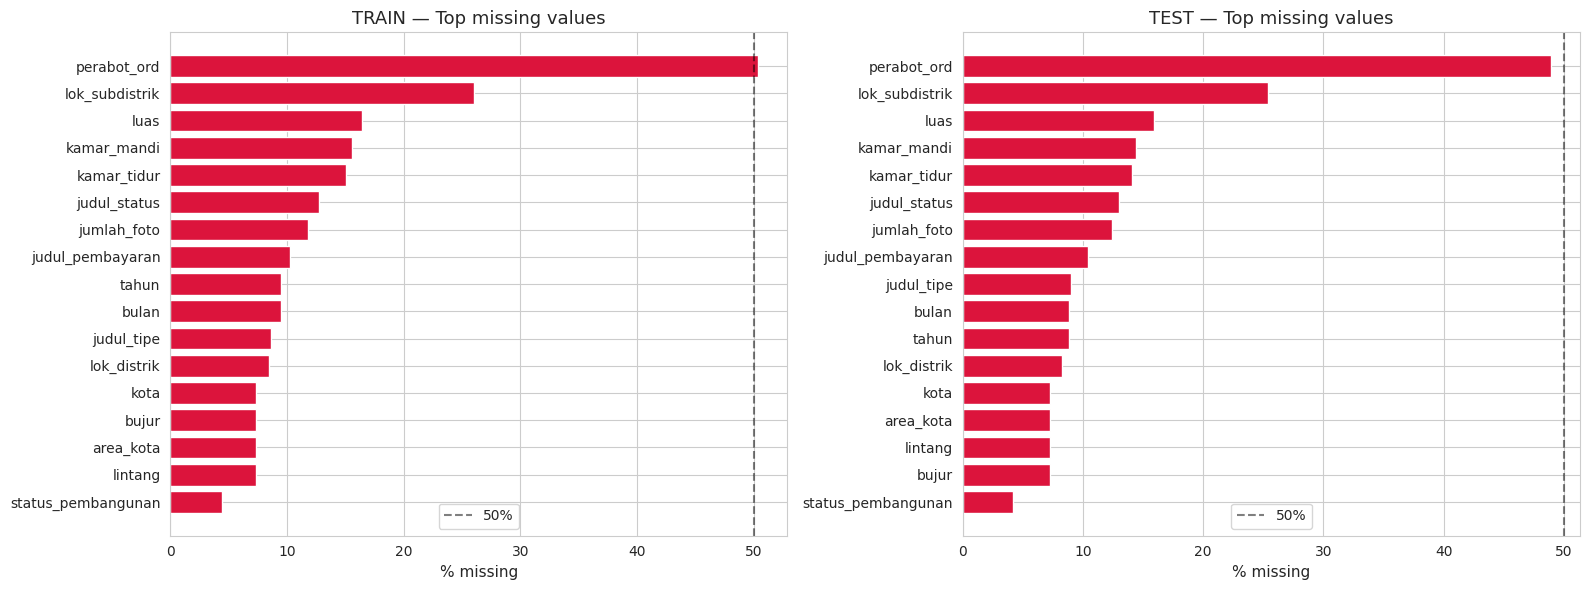


SECTION 3 — TARGET VARIABLE: harga
count                     13,862.0000
mean                  15,793,085.3945
median                 9,100,000.0000
std                   32,838,691.1397
variance   1,078,379,635,770,531.2500
min                      113,116.0000
Q1                     5,278,000.0000
Q3                    17,000,000.0000
IQR                   11,722,000.0000
max                1,000,000,000.0000
range                999,886,884.0000
skewness                      16.8462
kurtosis                     410.4517
CV                             2.0793

Jarque-Bera test: statistic=97961450.41, p-value=0
→ NOT normal (p<0.05)


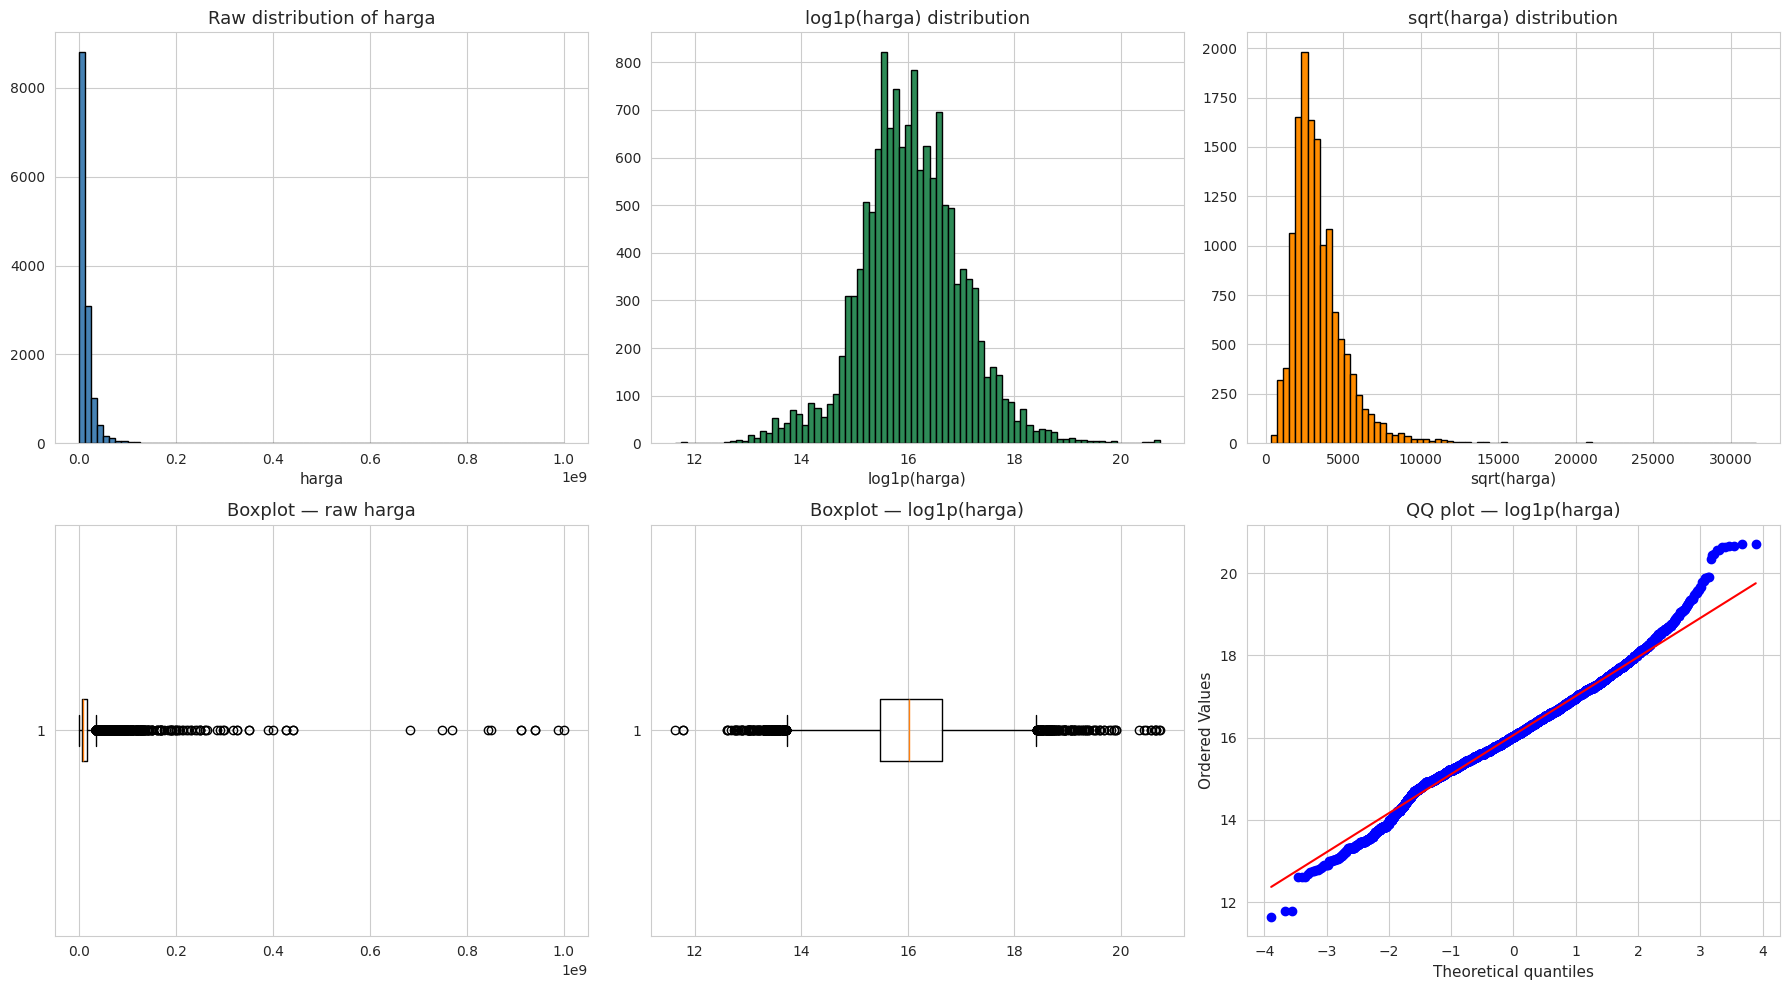


log1p(harga) Jarque-Bera p-value: 1.482e-150
→ even after log, not fully normal (common for real estate)

SECTION 4 — UNIVARIATE STATISTICS

--- TRAIN ---
           column  count  missing  pct_miss       mean      std        min         Q1     median         Q3         max  skewness   kurtosis
          lintang  12840     1022    7.3727    29.9183   0.8280    25.0600    29.9900    30.0300    30.0700     31.5000   -2.4003     6.5920
            bujur  12840     1022    7.3727    31.2577   1.1570    27.2300    30.9800    31.4600    31.5900     34.9100   -0.6711     2.7860
      kamar_tidur  11779     2083   15.0267     3.1738   2.4567     0.0000     2.0000     3.0000     4.0000     50.0000   10.4179   148.1360
      kamar_mandi  11707     2155   15.5461     3.1277   2.4724     1.0000     2.0000     3.0000     4.0000     70.0000   11.5650   213.0302
             luas  11582     2280   16.4478   192.4766 304.3484     1.0000   110.7000   162.4000   229.1000 21,484.3000   42.1382 2,547.743

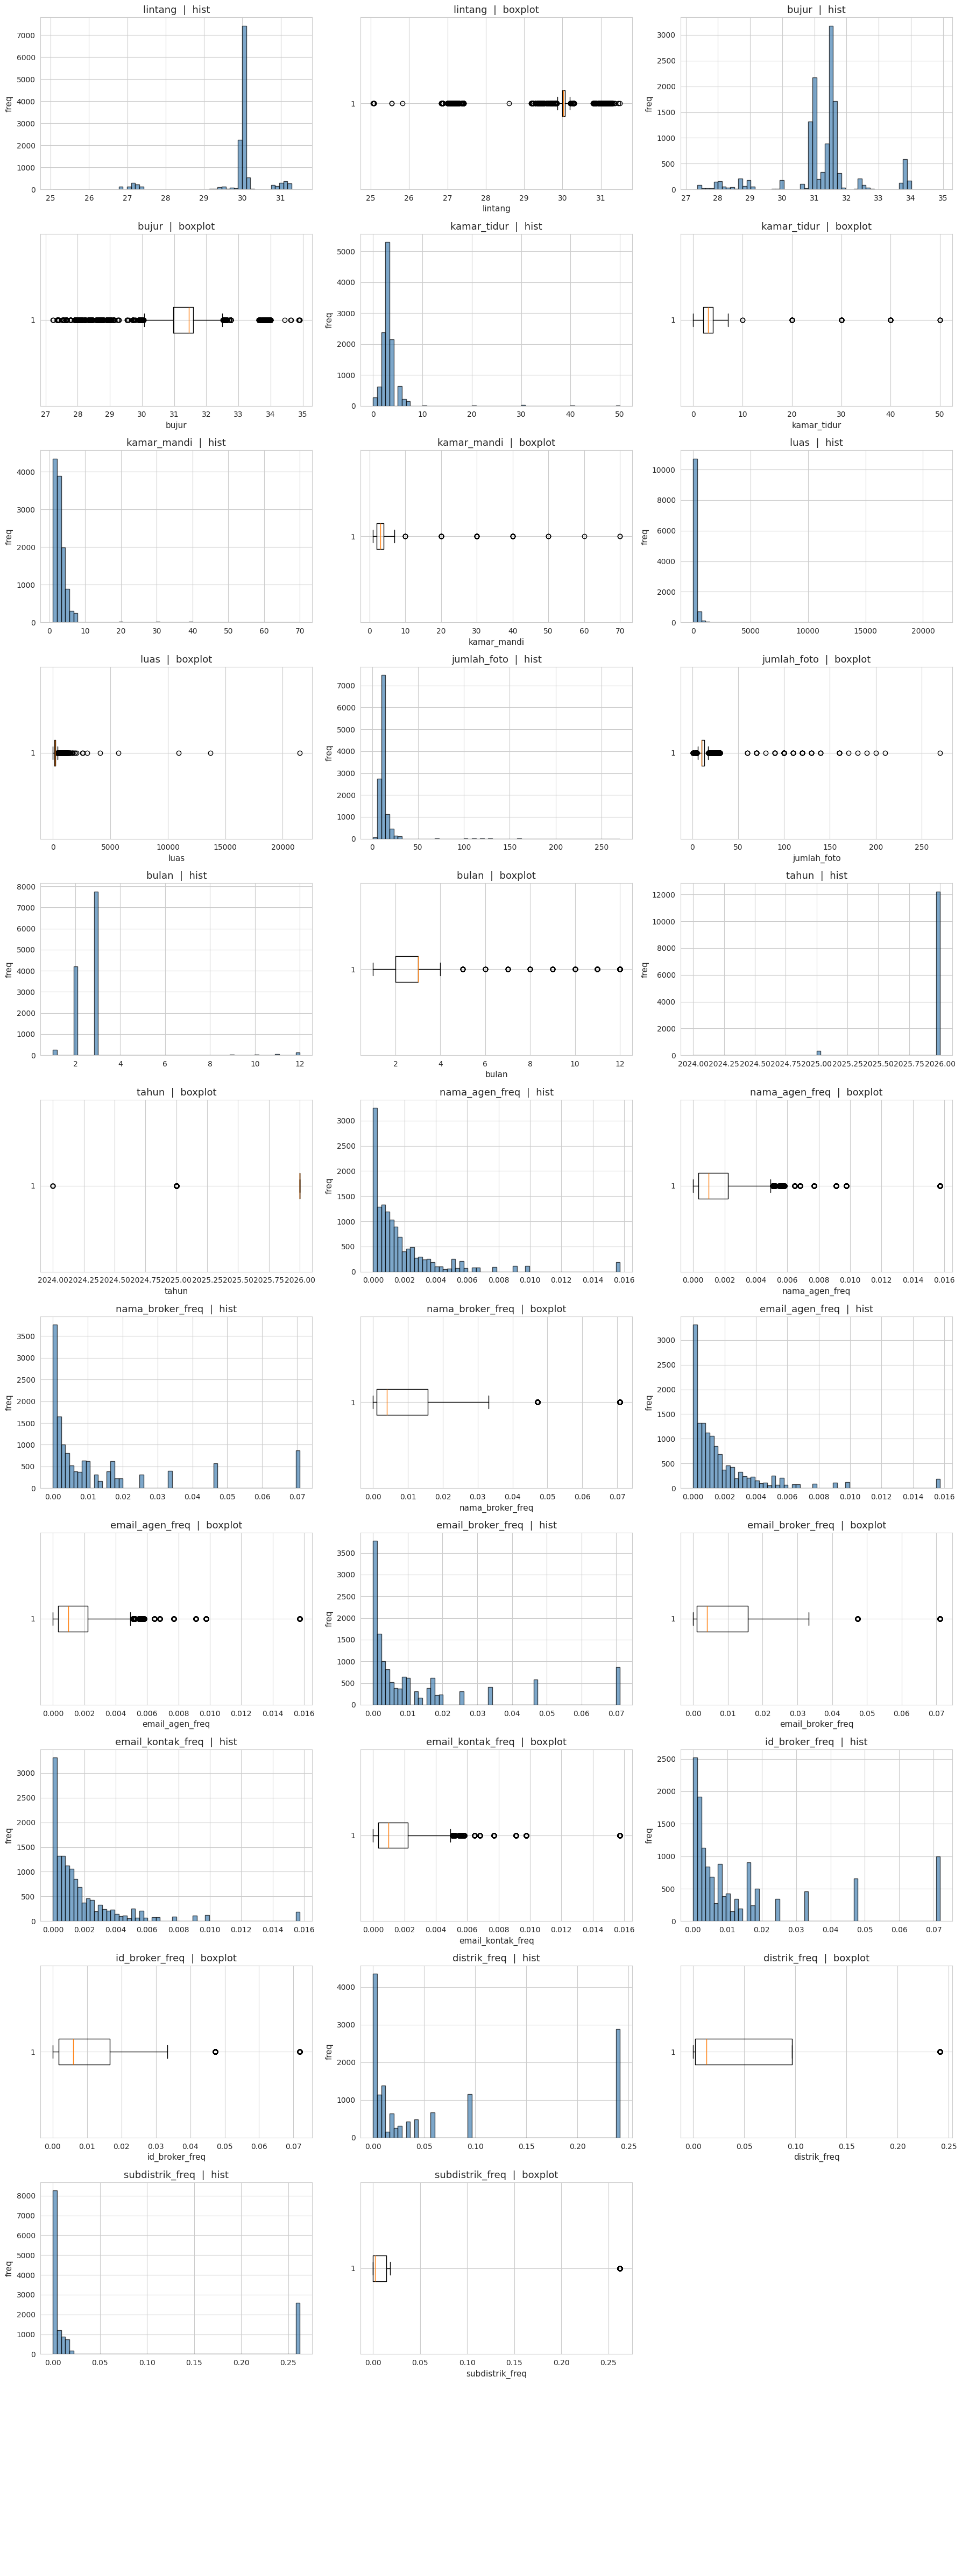


SECTION 6 — BIVARIATE ANALYSIS vs TARGET (harga)
          feature     n  pearson_r  pearson_|r|  pearson_p  spearman_r  spearman_|r|  spearman_p
             luas 11582     0.3703       0.3703     0.0000      0.7118        0.7118      0.0000
      kamar_mandi 11707     0.2339       0.2339     0.0000      0.5750        0.5750      0.0000
      kamar_tidur 11779     0.1807       0.1807     0.0000      0.4788        0.4788      0.0000
            bujur 12840    -0.0602       0.0602     0.0000     -0.0862        0.0862      0.0000
          lintang 12840     0.0571       0.0571     0.0000      0.0310        0.0310      0.0004
  email_agen_freq 13862    -0.0506       0.0506     0.0000     -0.0657        0.0657      0.0000
email_kontak_freq 13862    -0.0506       0.0506     0.0000     -0.0657        0.0657      0.0000
   nama_agen_freq 13862    -0.0497       0.0497     0.0000     -0.0633        0.0633      0.0000
  subdistrik_freq 13862     0.0420       0.0420     0.0000      0.1320       

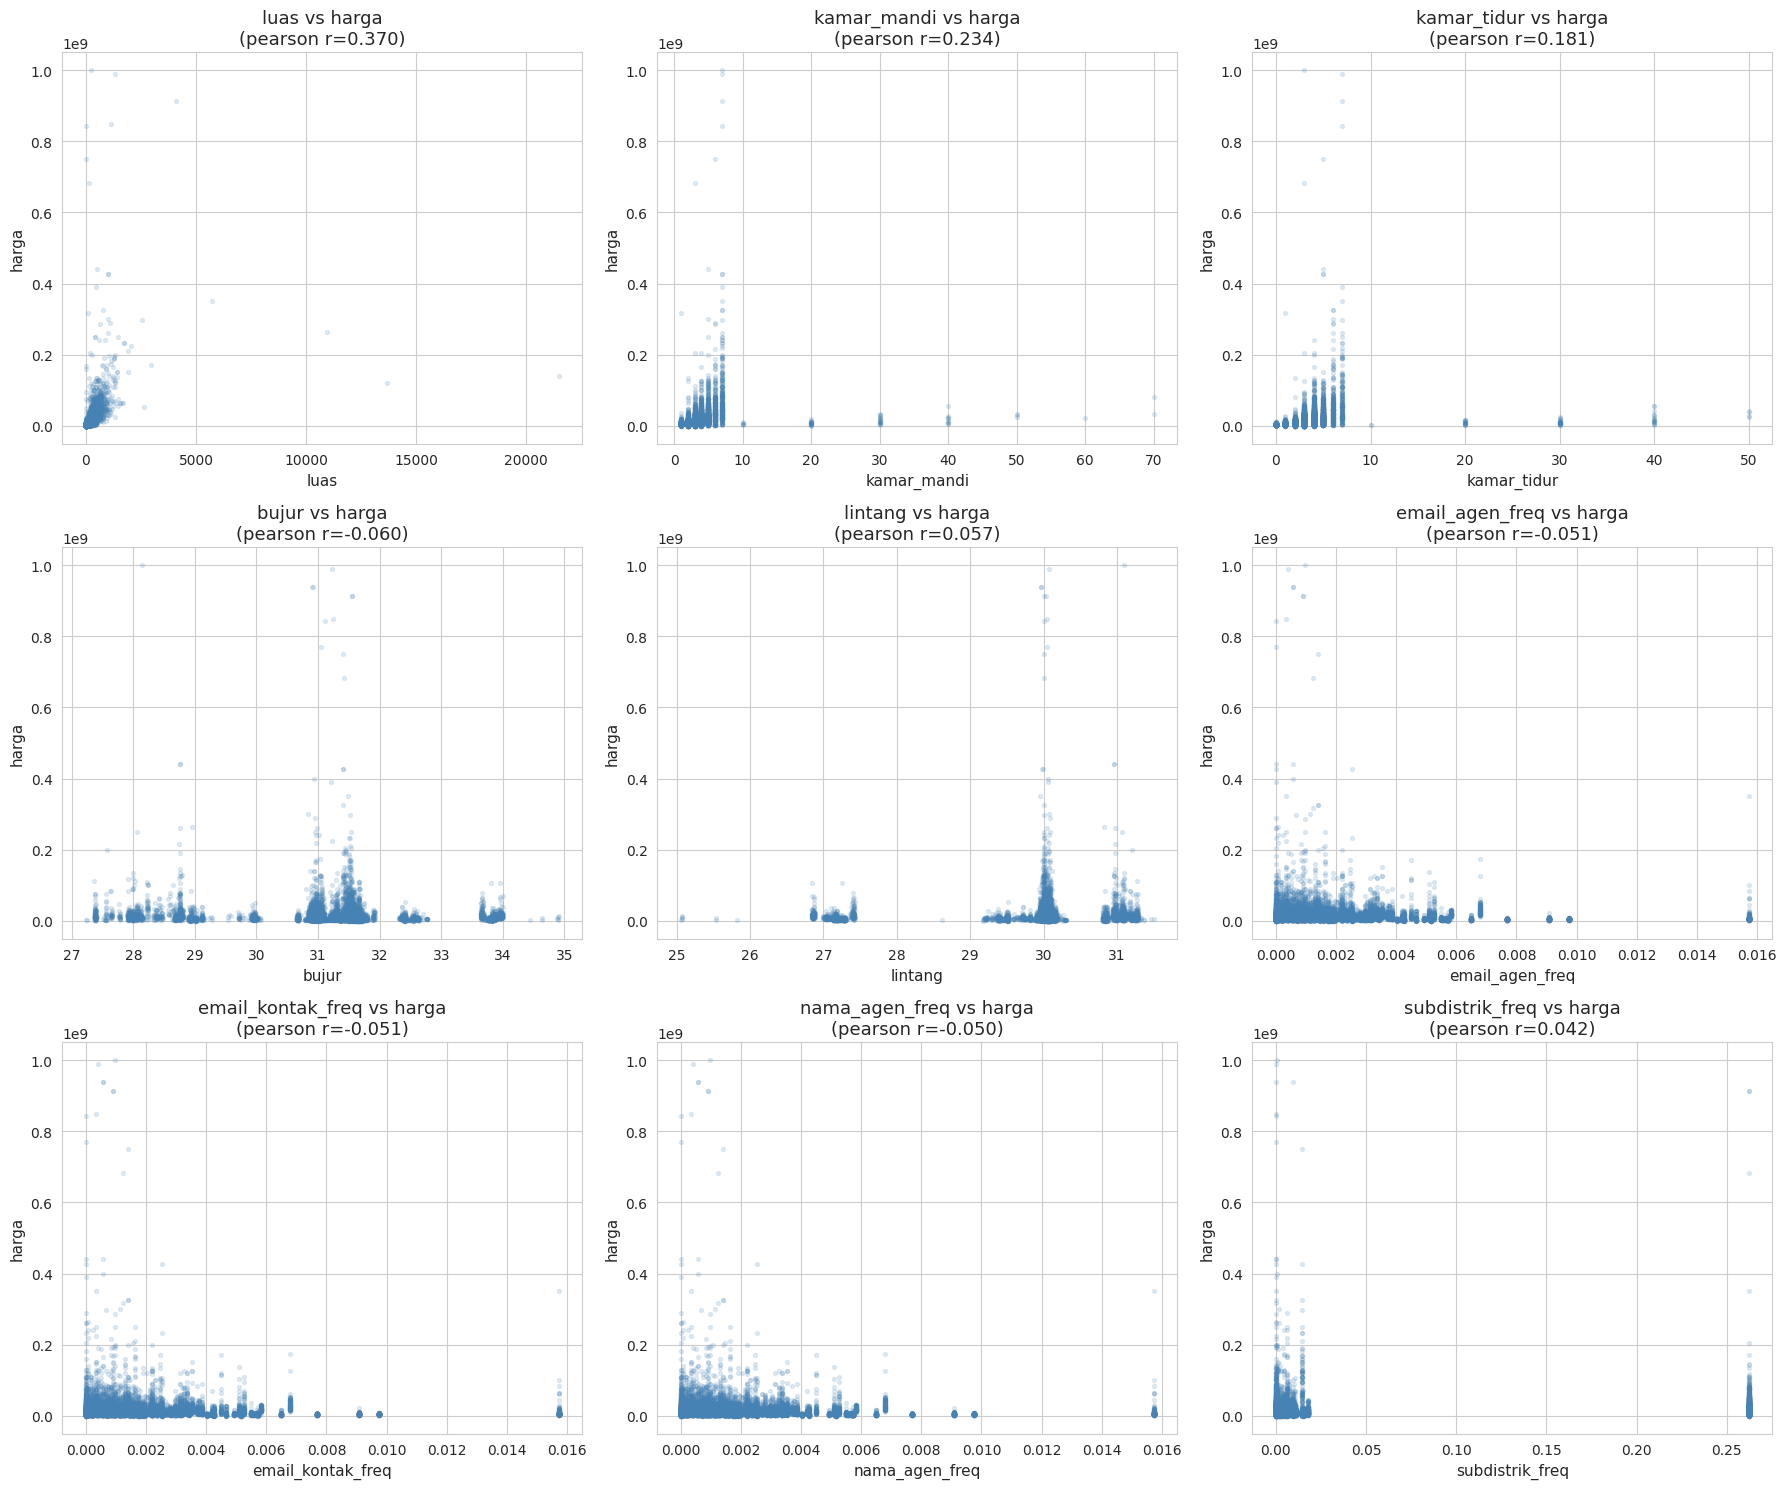


SECTION 7 — CORRELATION MATRIX


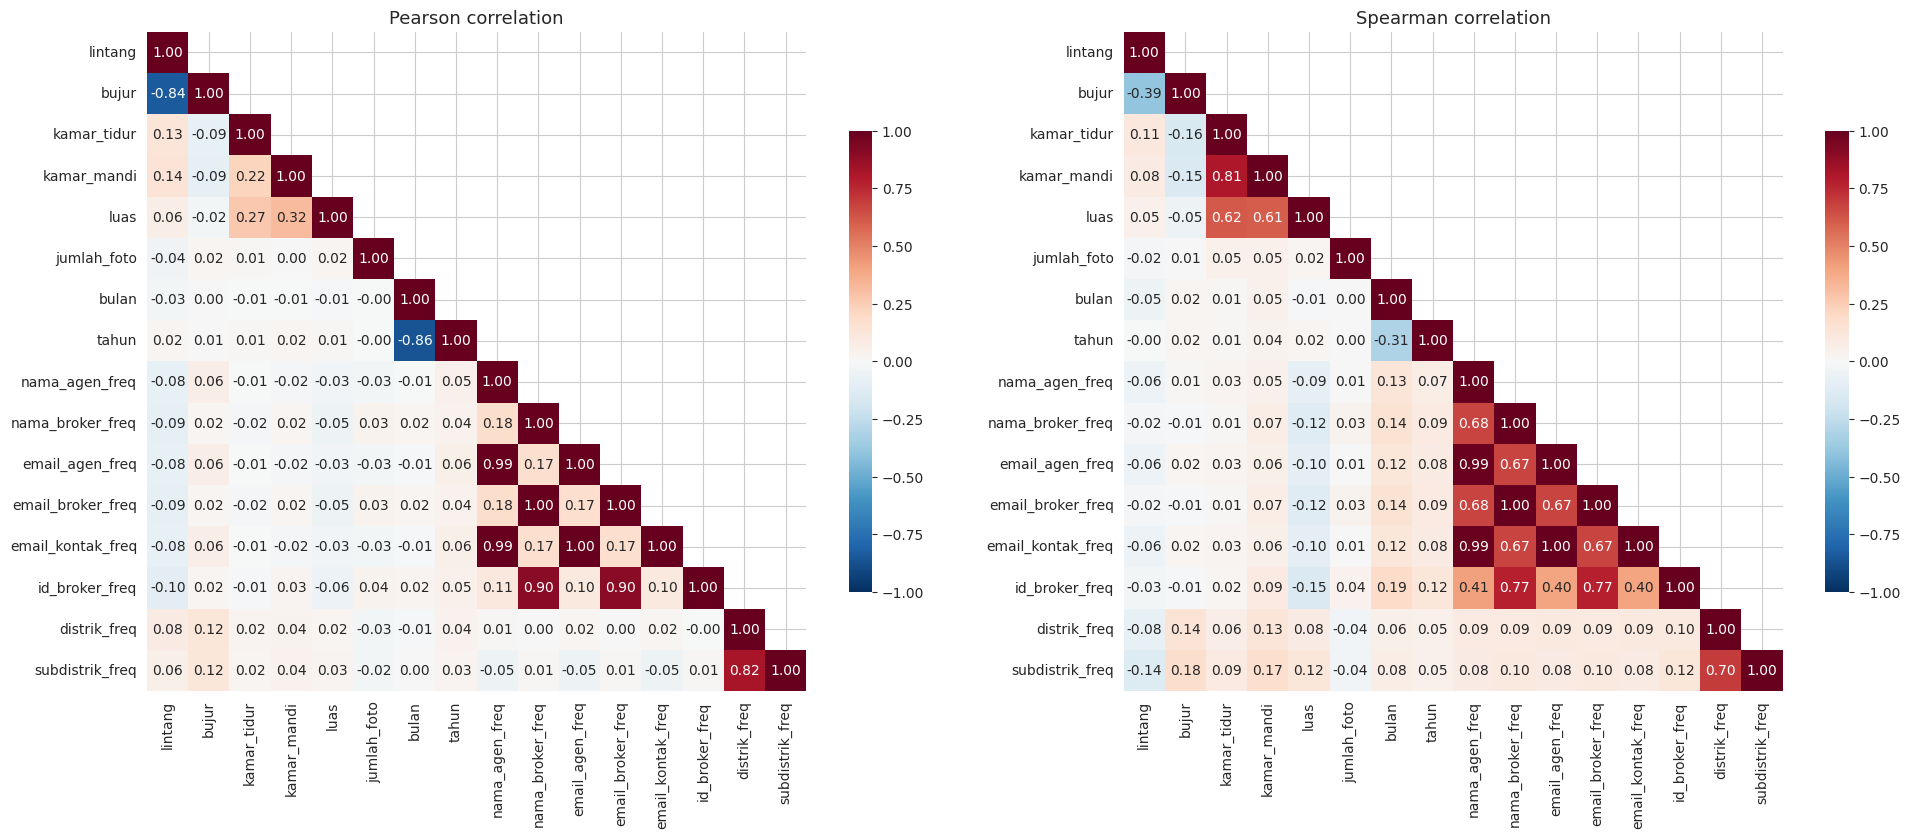


Highly correlated feature pairs (|r| > 0.7):
        feature_1         feature_2  pearson_r  abs_r
  email_agen_freq email_kontak_freq     1.0000 1.0000
 nama_broker_freq email_broker_freq     1.0000 1.0000
   nama_agen_freq email_kontak_freq     0.9940 0.9940
   nama_agen_freq   email_agen_freq     0.9940 0.9940
email_broker_freq    id_broker_freq     0.9035 0.9035
 nama_broker_freq    id_broker_freq     0.9035 0.9035
            bulan             tahun    -0.8633 0.8633
          lintang             bujur    -0.8409 0.8409
     distrik_freq   subdistrik_freq     0.8225 0.8225

SECTION 8 — OUTLIER ANALYSIS (IQR method)
           column     n  n_outliers  pct_outliers  lower_bound  upper_bound
     distrik_freq 13862        2880       20.7762      -0.1400       0.2382
          lintang 12840        2629       20.4751      29.8700      30.1900
  subdistrik_freq 13862        2586       18.6553      -0.0213       0.0355
            bujur 12840        2318       18.0530      30.0650     

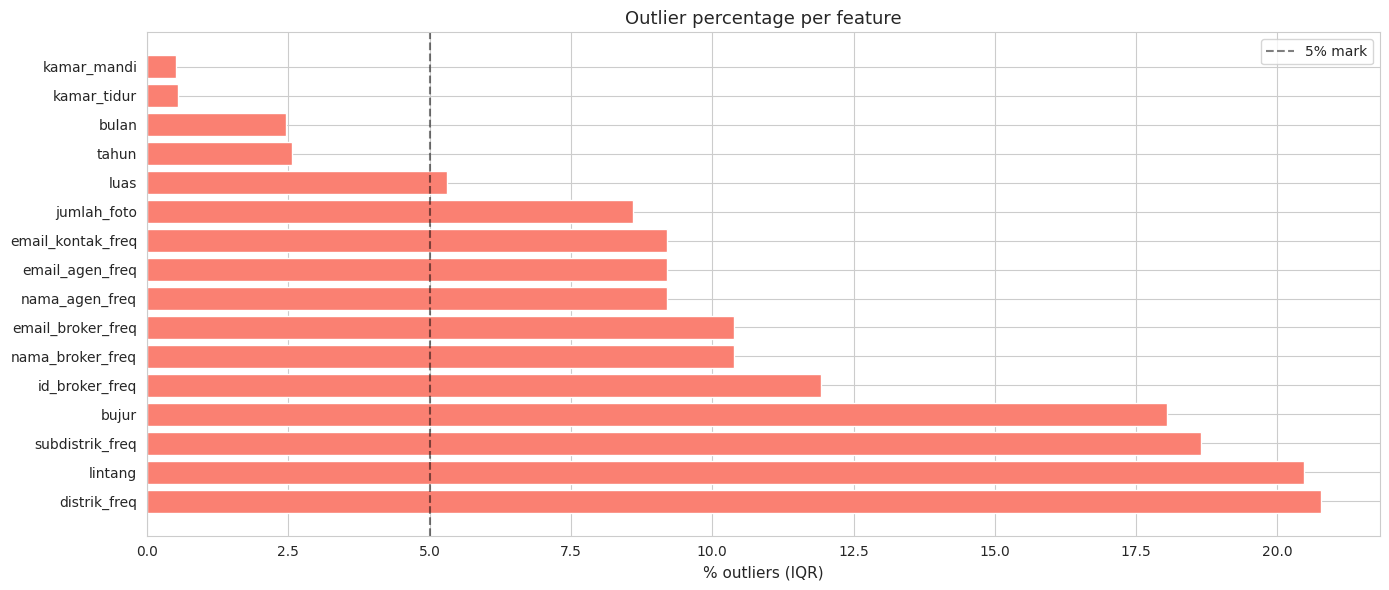


SECTION 9 — TRAIN vs TEST DISTRIBUTION SHIFT
          feature  train_mean  test_mean  train_std  test_std  ks_statistic  ks_pvalue shift?
email_kontak_freq      0.0018     0.0018     0.0025    0.0025        0.0353     0.0001    YES
  email_agen_freq      0.0018     0.0018     0.0025    0.0025        0.0353     0.0001    YES
   nama_agen_freq      0.0018     0.0018     0.0025    0.0025        0.0330     0.0002    YES
      jumlah_foto     12.0398    12.2045     9.0905   10.4173        0.0176     0.2045     no
            bujur     31.2577    31.2791     1.1570    1.1720        0.0149     0.3589     no
  subdistrik_freq      0.0516     0.0518     0.1009    0.1011        0.0147     0.3259     no
     distrik_freq      0.0671     0.0680     0.0932    0.0938        0.0114     0.6430     no
             luas    192.4766   190.7790   304.3484  187.5129        0.0114     0.7505     no
   id_broker_freq      0.0141     0.0144     0.0197    0.0201        0.0105     0.7459     no
email_broker_f

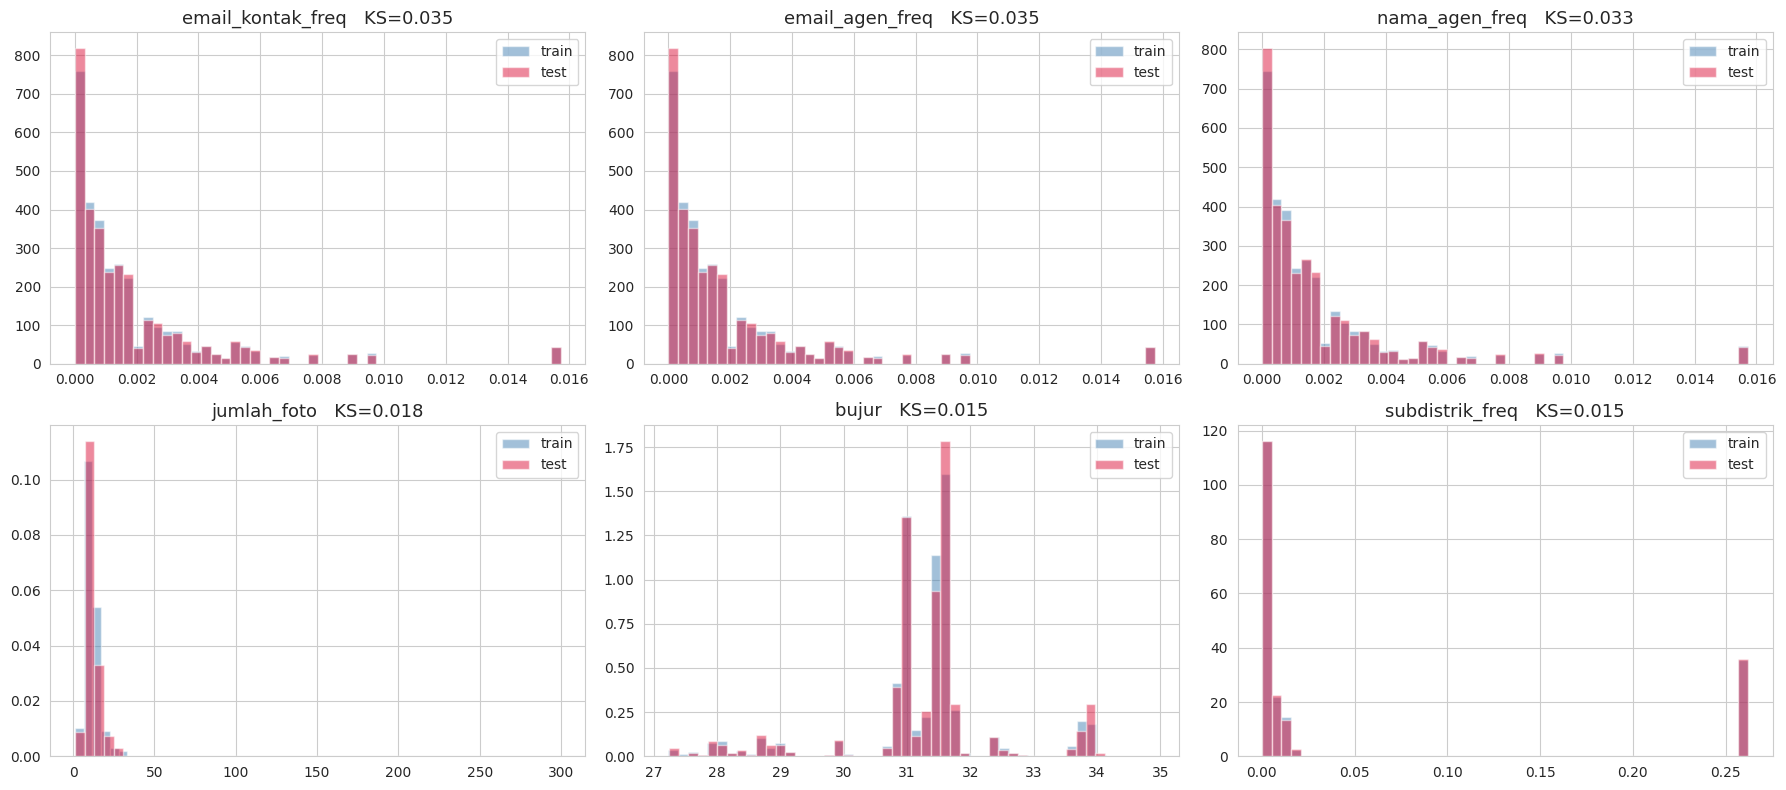


SECTION 10 — TARGET STRATIFICATION (quartile analysis)

Mean feature value per target quartile:
_harga_q              Q1_low         Q2         Q3    Q4_high
lintang              29.8110    29.8630    29.9700    30.0300
bujur                31.3930    31.3780    31.1640    31.0930
kamar_tidur           2.5970     2.7710     3.1380     4.2550
kamar_mandi           2.3430     2.5530     3.1280     4.5220
luas                 95.2870   144.1550   187.6610   368.3930
jumlah_foto          11.7560    11.7270    11.9130    12.7960
bulan                 2.8830     2.7990     2.7800     2.7450
tahun             2,025.9540 2,025.9710 2,025.9810 2,025.9910
nama_agen_freq        0.0020     0.0020     0.0010     0.0020
nama_broker_freq      0.0120     0.0100     0.0140     0.0140
email_agen_freq       0.0020     0.0020     0.0010     0.0020
email_broker_freq     0.0120     0.0100     0.0140     0.0140
email_kontak_freq     0.0020     0.0020     0.0010     0.0020
id_broker_freq        0.0130     0.

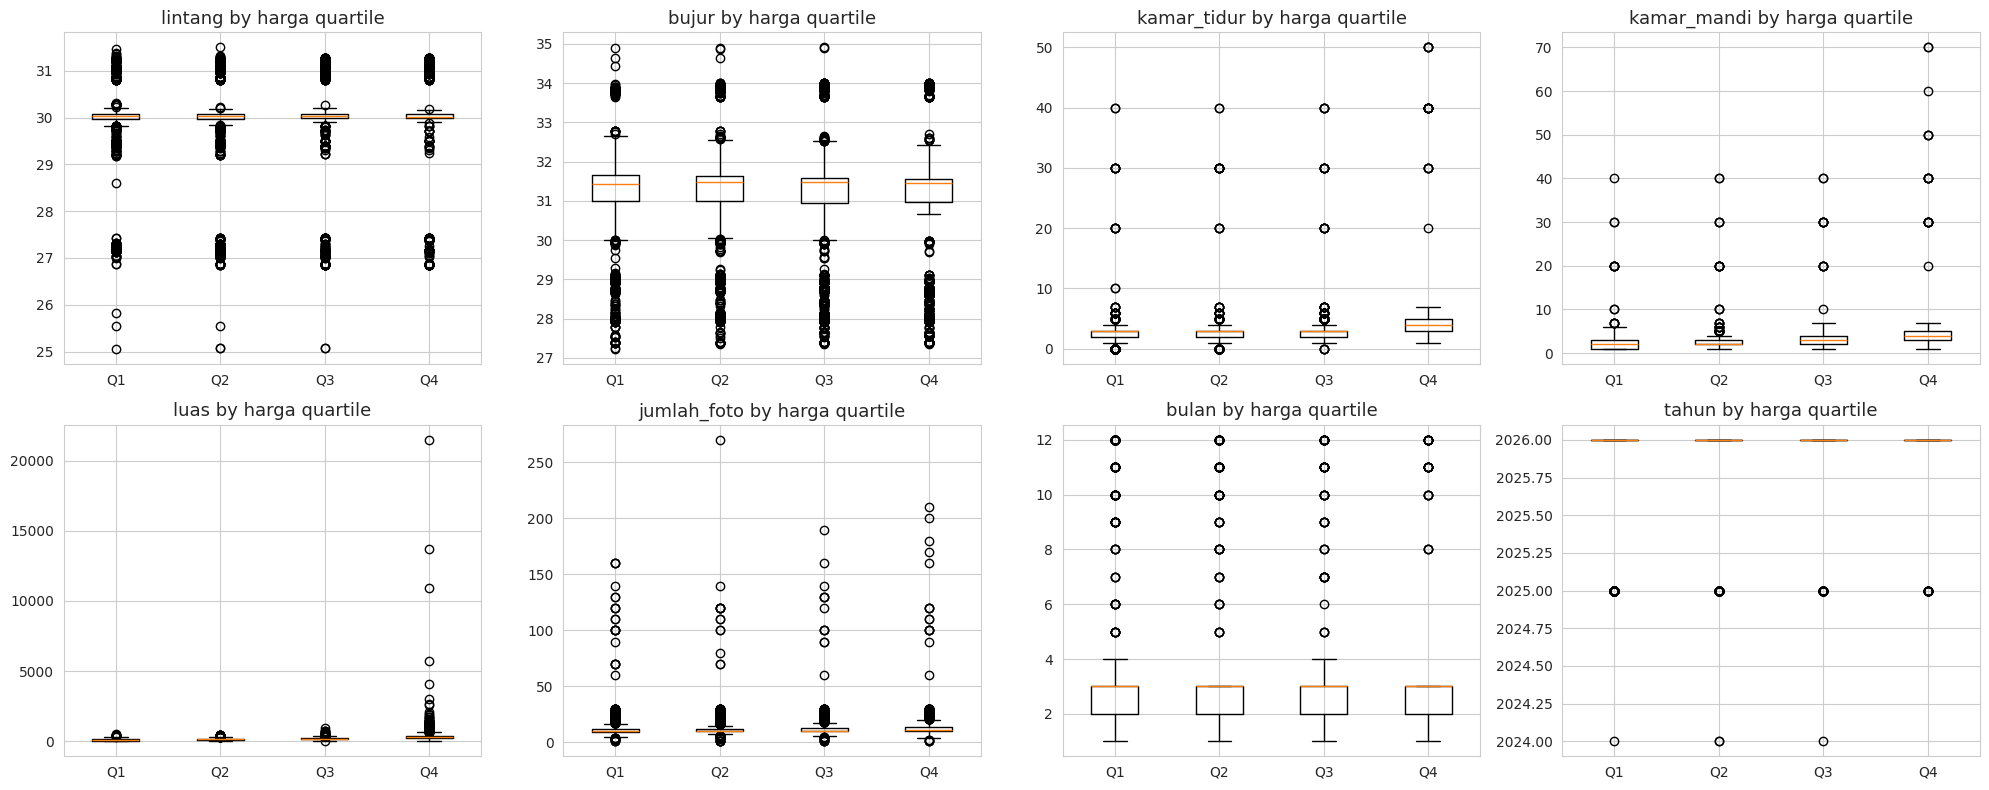


SECTION 11 — TIME FEATURES (bulan & tahun)

--- bulan ---
bulan
1.0000      270
2.0000     4212
3.0000     7753
4.0000        6
5.0000       14
6.0000       11
7.0000       14
8.0000       16
9.0000       23
10.0000      40
11.0000      65
12.0000     125

Average harga by bulan:
         count            mean          median
bulan                                         
1.0000     270 11,324,460.0000  7,000,000.0000
2.0000    4212 14,423,732.0000  8,130,166.0000
3.0000    7753 17,139,262.0000 10,000,000.0000
4.0000       6  7,040,000.0000  5,070,000.0000
5.0000      14  6,436,826.0000  5,182,000.0000
6.0000      11  5,551,812.0000  4,496,331.0000
7.0000      14  9,553,571.0000  9,175,000.0000
8.0000      16 10,605,750.0000  7,850,000.0000
9.0000      23  6,182,609.0000  5,000,000.0000
10.0000     40 11,137,800.0000  5,150,000.0000
11.0000     65 10,918,336.0000  6,100,000.0000
12.0000    125  7,560,550.0000  5,200,000.0000


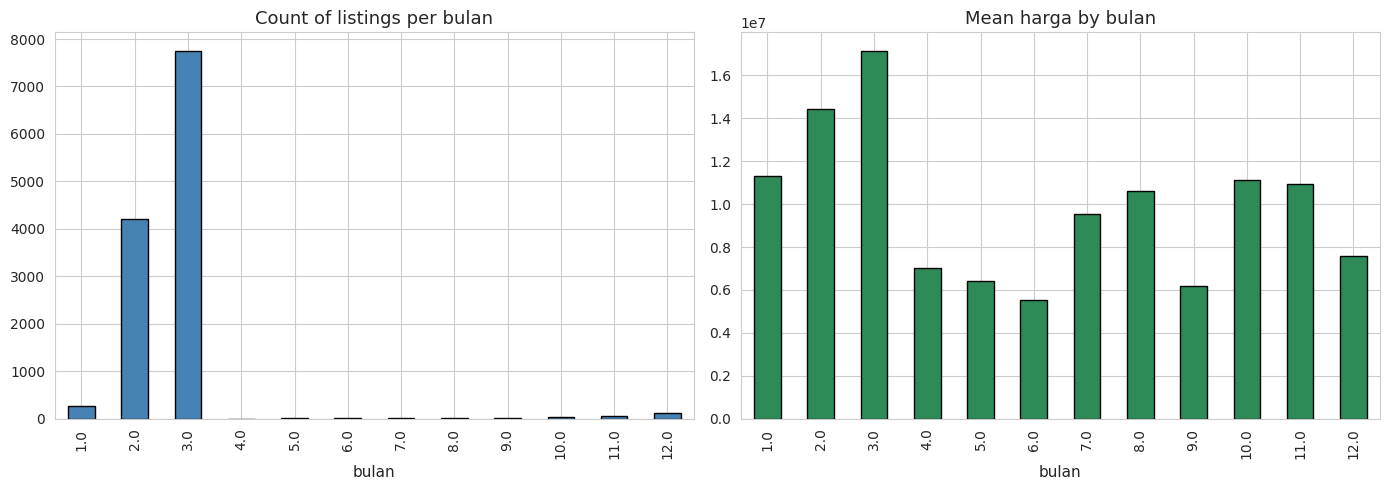


--- tahun ---
tahun
2,024.0000        4
2,025.0000      318
2,026.0000    12227

Average harga by tahun:
            count            mean         median
tahun                                           
2,024.0000      4  8,337,500.0000 7,250,000.0000
2,025.0000    318  9,925,441.0000 5,500,000.0000
2,026.0000  12227 16,049,789.0000 9,300,000.0000


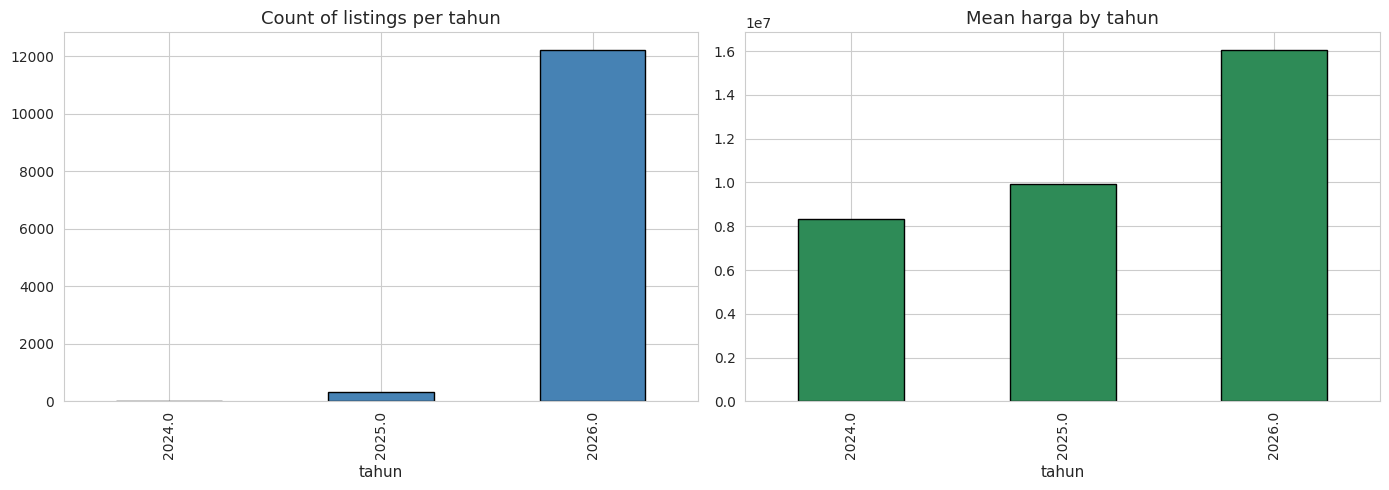


SECTION 12 — SUMMARY: TOP FEATURES FOR PREDICTION
 rank           feature  mutual_info  pearson_abs  spearman_abs  score
    1              luas       0.4302       0.3000        0.6284 0.9272
    2       kamar_mandi       0.2806       0.1907        0.5279 0.6335
    3    id_broker_freq       0.5036       0.0166        0.0091 0.5079
    4       kamar_tidur       0.2260       0.1437        0.4375 0.5017
    5  nama_broker_freq       0.4328       0.0102        0.0091 0.4311
    6 email_broker_freq       0.4311       0.0102        0.0097 0.4296
    7 email_kontak_freq       0.3139       0.0506        0.0657 0.3730
    8   email_agen_freq       0.3131       0.0506        0.0657 0.3722
    9    nama_agen_freq       0.3128       0.0497        0.0633 0.3701
   10             bujur       0.2549       0.0586        0.0725 0.3248
   11      distrik_freq       0.2500       0.0187        0.1129 0.2919
   12   subdistrik_freq       0.2038       0.0420        0.1320 0.2761
   13           lintang   

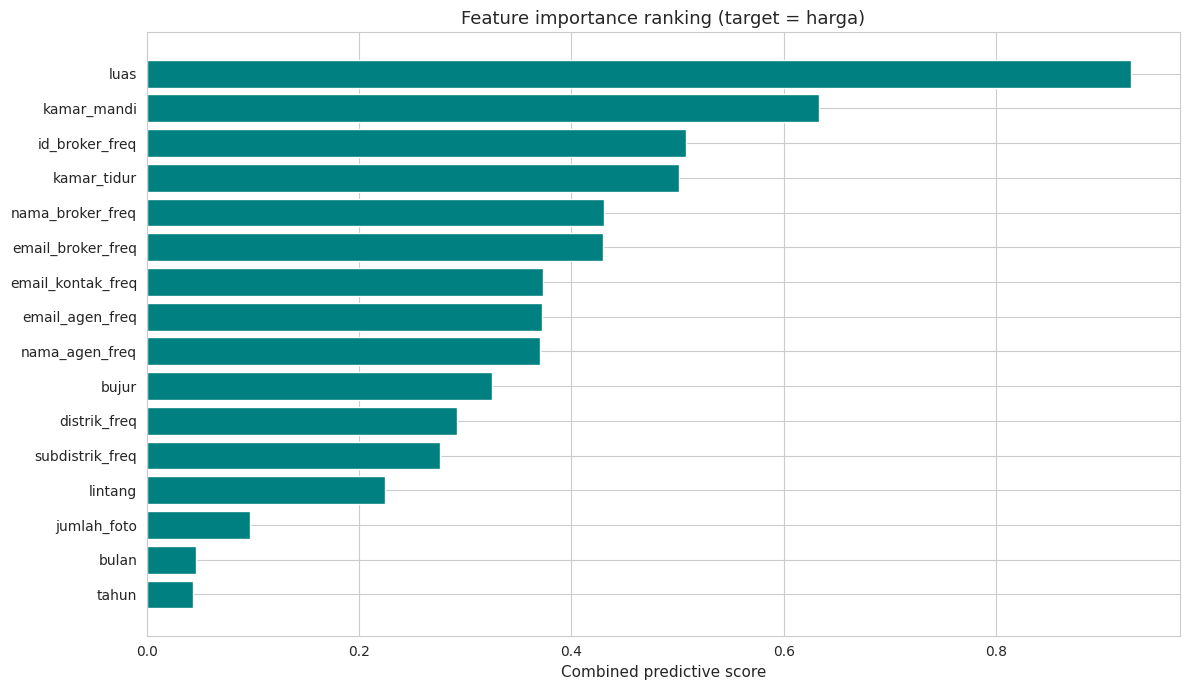


🎯 TOP 5 FEATURES for predicting harga:
   1. luas                  score=0.9272  MI=0.4302
   2. kamar_mandi           score=0.6335  MI=0.2806
   3. id_broker_freq        score=0.5079  MI=0.5036
   4. kamar_tidur           score=0.5017  MI=0.2260
   5. nama_broker_freq      score=0.4311  MI=0.4328

SECTION 13 — EDA INSIGHTS & RECOMMENDATIONS

Key findings to review:
  1. TARGET DISTRIBUTION
     - harga is right-skewed → consider log1p(harga) as target
     - Check whether residuals are more normal after log

  2. MISSING VALUES
     - Any column with >30% missing needs careful imputation strategy
     - Consider dropping columns with >60% missing

  3. OUTLIERS
     - Columns with >5% IQR outliers deserve investigation
     - Consider clip / winsorize for tree models (not strictly needed)

  4. MULTICOLLINEARITY
     - Pairs with |r| > 0.85 should be reduced (keep one, drop other)
     - Especially lintang/bujur (usually correlated) or *_freq pairs

  5. TRAIN/TEST SHIFT
     - Featu

In [32]:
# ================================================================
# COMPLETE EDA — Exploratory Data Analysis
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import skew, kurtosis, normaltest, jarque_bera

# global plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

TARGET = 'harga'

NUMERIC_COLS = [
    'lintang', 'bujur', 'kamar_tidur', 'kamar_mandi', 'luas',
    'jumlah_foto', 'bulan', 'tahun',
    'nama_agen_freq', 'nama_broker_freq',
    'email_agen_freq', 'email_broker_freq', 'email_kontak_freq',
    'id_broker_freq', 'distrik_freq', 'subdistrik_freq',
]

print("=" * 90)
print("EDA — EXPLORATORY DATA ANALYSIS")
print("=" * 90)


# ================================================================
# 1. DATASET OVERVIEW
# ================================================================

print("\n" + "=" * 90)
print("SECTION 1 — DATASET OVERVIEW")
print("=" * 90)

def overview(df, name):
    print(f"\n--- {name} ---")
    print(f"Shape          : {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(f"Memory usage   : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
    print(f"Duplicate rows : {df.duplicated().sum():,}")
    print(f"Columns:")
    for c in df.columns:
        print(f"    {c:25s} dtype={str(df[c].dtype):10s} nunique={df[c].nunique(dropna=True):>6d}")

overview(train_df, 'TRAIN')
overview(test_df,  'TEST')

# dtype distribution
print("\n\nData type breakdown (TRAIN):")
print(train_df.dtypes.value_counts().to_string())


# ================================================================
# 2. MISSING VALUES ANALYSIS
# ================================================================

print("\n" + "=" * 90)
print("SECTION 2 — MISSING VALUES")
print("=" * 90)

def missing_report(df, name):
    miss = pd.DataFrame({
        'missing': df.isna().sum(),
        'pct':     df.isna().mean() * 100,
    }).sort_values('pct', ascending=False)
    miss = miss[miss['missing'] > 0]
    print(f"\n--- {name} — columns with missing values ---")
    if miss.empty:
        print("  (no missing values)")
    else:
        print(miss.to_string())
    return miss

miss_train = missing_report(train_df, 'TRAIN')
miss_test  = missing_report(test_df,  'TEST')

# visual — top-20 missing
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (miss, name) in zip(axes, [(miss_train, 'TRAIN'), (miss_test, 'TEST')]):
    if not miss.empty:
        top = miss.head(20)
        ax.barh(top.index[::-1], top['pct'][::-1], color='crimson')
        ax.set_xlabel('% missing')
        ax.set_title(f'{name} — Top missing values')
        ax.axvline(50, color='black', linestyle='--', alpha=0.5, label='50%')
        ax.legend()
plt.tight_layout()
plt.show()


# ================================================================
# 3. TARGET VARIABLE (harga)
# ================================================================

print("\n" + "=" * 90)
print("SECTION 3 — TARGET VARIABLE: harga")
print("=" * 90)

if TARGET in train_df.columns:
    y = train_df[TARGET].dropna()

    stats_summary = {
        'count':    len(y),
        'mean':     y.mean(),
        'median':   y.median(),
        'std':      y.std(),
        'variance': y.var(),
        'min':      y.min(),
        'Q1':       y.quantile(0.25),
        'Q3':       y.quantile(0.75),
        'IQR':      y.quantile(0.75) - y.quantile(0.25),
        'max':      y.max(),
        'range':    y.max() - y.min(),
        'skewness': skew(y),
        'kurtosis': kurtosis(y),
        'CV':       y.std() / y.mean(),
    }
    print(pd.Series(stats_summary).to_string())

    # normality
    jb_stat, jb_p = jarque_bera(y)
    print(f"\nJarque-Bera test: statistic={jb_stat:.2f}, p-value={jb_p:.4g}")
    print("→ " + ("NOT normal (p<0.05)" if jb_p < 0.05 else "consistent with normal"))

    # visualizations
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    # raw histogram
    axes[0, 0].hist(y, bins=80, color='steelblue', edgecolor='black')
    axes[0, 0].set_title('Raw distribution of harga')
    axes[0, 0].set_xlabel('harga')

    # log histogram
    y_log = np.log1p(y)
    axes[0, 1].hist(y_log, bins=80, color='seagreen', edgecolor='black')
    axes[0, 1].set_title('log1p(harga) distribution')
    axes[0, 1].set_xlabel('log1p(harga)')

    # sqrt histogram
    y_sqrt = np.sqrt(y)
    axes[0, 2].hist(y_sqrt, bins=80, color='darkorange', edgecolor='black')
    axes[0, 2].set_title('sqrt(harga) distribution')
    axes[0, 2].set_xlabel('sqrt(harga)')

    # boxplot raw
    axes[1, 0].boxplot(y, vert=False)
    axes[1, 0].set_title('Boxplot — raw harga')

    # boxplot log
    axes[1, 1].boxplot(y_log, vert=False)
    axes[1, 1].set_title('Boxplot — log1p(harga)')

    # QQ plot of log
    stats.probplot(y_log, dist='norm', plot=axes[1, 2])
    axes[1, 2].set_title('QQ plot — log1p(harga)')

    plt.tight_layout()
    plt.show()

    # log-normality test
    jb_stat_log, jb_p_log = jarque_bera(y_log)
    print(f"\nlog1p(harga) Jarque-Bera p-value: {jb_p_log:.4g}")
    if jb_p_log > 0.05:
        print("→ log transform makes harga approximately normal ✅")
    else:
        print("→ even after log, not fully normal (common for real estate)")


# ================================================================
# 4. UNIVARIATE STATISTICS — ALL NUMERIC FEATURES
# ================================================================

print("\n" + "=" * 90)
print("SECTION 4 — UNIVARIATE STATISTICS")
print("=" * 90)

def univariate_table(df, cols, name):
    rows = []
    for c in cols:
        if c not in df.columns:
            continue
        s = df[c].dropna()
        if s.empty:
            continue
        rows.append({
            'column':   c,
            'count':    len(s),
            'missing':  df[c].isna().sum(),
            'pct_miss': df[c].isna().mean() * 100,
            'mean':     s.mean(),
            'std':      s.std(),
            'min':      s.min(),
            'Q1':       s.quantile(0.25),
            'median':   s.median(),
            'Q3':       s.quantile(0.75),
            'max':      s.max(),
            'skewness': skew(s),
            'kurtosis': kurtosis(s),
        })
    return pd.DataFrame(rows).round(4)

stats_train = univariate_table(train_df, NUMERIC_COLS, 'TRAIN')
print("\n--- TRAIN ---")
print(stats_train.to_string(index=False))

stats_test = univariate_table(test_df, NUMERIC_COLS, 'TEST')
print("\n--- TEST ---")
print(stats_test.to_string(index=False))


# ================================================================
# 5. DISTRIBUTION GRIDS — HISTOGRAM + BOXPLOT PER FEATURE
# ================================================================

print("\n" + "=" * 90)
print("SECTION 5 — DISTRIBUTION PLOTS")
print("=" * 90)

# exclude target from the numeric feature loop
feat_cols = [c for c in NUMERIC_COLS if c != TARGET and c in train_df.columns]

n_cols = 3
n_rows = int(np.ceil(len(feat_cols) / n_cols))

fig, axes = plt.subplots(n_rows * 2, n_cols, figsize=(18, 4 * n_rows * 2))
axes = axes.flatten()

for i, col in enumerate(feat_cols):
    s = train_df[col].dropna()
    # histogram
    ax_h = axes[i * 2]
    ax_h.hist(s, bins=60, color='steelblue', edgecolor='black', alpha=0.7)
    ax_h.set_title(f'{col}  |  hist')
    ax_h.set_ylabel('freq')
    # boxplot
    ax_b = axes[i * 2 + 1]
    ax_b.boxplot(s, vert=False)
    ax_b.set_title(f'{col}  |  boxplot')
    ax_b.set_xlabel(col)

# hide unused axes
for j in range(len(feat_cols) * 2, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


# ================================================================
# 6. BIVARIATE — EACH FEATURE vs TARGET
# ================================================================

print("\n" + "=" * 90)
print("SECTION 6 — BIVARIATE ANALYSIS vs TARGET (harga)")
print("=" * 90)

if TARGET in train_df.columns:
    # correlation table
    def corr_to_target(df, cols, target):
        rows = []
        y = df[target]
        for c in cols:
            if c not in df.columns or c == target:
                continue
            valid = df[c].notna() & y.notna()
            if valid.sum() < 10:
                continue
            x = df.loc[valid, c]
            yy = y[valid]
            if x.nunique() < 2:
                continue
            pearson_r,  pearson_p  = stats.pearsonr(x, yy)
            spearman_r, spearman_p = stats.spearmanr(x, yy)
            rows.append({
                'feature':       c,
                'n':             int(valid.sum()),
                'pearson_r':     pearson_r,
                'pearson_|r|':   abs(pearson_r),
                'pearson_p':     pearson_p,
                'spearman_r':    spearman_r,
                'spearman_|r|':  abs(spearman_r),
                'spearman_p':    spearman_p,
            })
        return pd.DataFrame(rows).sort_values('pearson_|r|', ascending=False)

    corr_tab = corr_to_target(train_df, NUMERIC_COLS, TARGET)
    print(corr_tab.round(4).to_string(index=False))

    # scatter grid: feature vs target
    feature_for_scatter = corr_tab.head(9)['feature'].tolist()
    n_cols = 3
    n_rows = int(np.ceil(len(feature_for_scatter) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
    axes = axes.flatten()
    for i, col in enumerate(feature_for_scatter):
        ax = axes[i]
        ax.scatter(train_df[col], train_df[TARGET],
                   alpha=0.15, s=8, color='steelblue')
        ax.set_title(f'{col} vs {TARGET}\n(pearson r={corr_tab.loc[corr_tab.feature==col,"pearson_r"].values[0]:.3f})')
        ax.set_xlabel(col)
        ax.set_ylabel(TARGET)
    for j in range(len(feature_for_scatter), len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()


# ================================================================
# 7. CORRELATION MATRIX
# ================================================================

print("\n" + "=" * 90)
print("SECTION 7 — CORRELATION MATRIX")
print("=" * 90)

# Pearson
corr_matrix = train_df[NUMERIC_COLS].corr(method='pearson')

# mask upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[0],
            square=True, cbar_kws={'shrink': .7})
axes[0].set_title('Pearson correlation')

# Spearman
corr_spearman = train_df[NUMERIC_COLS].corr(method='spearman')
sns.heatmap(corr_spearman, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[1],
            square=True, cbar_kws={'shrink': .7})
axes[1].set_title('Spearman correlation')

plt.tight_layout()
plt.show()

# strong pairs (|r| > 0.7)
print("\nHighly correlated feature pairs (|r| > 0.7):")
strong_pairs = (
    corr_matrix.where(np.triu(np.ones_like(corr_matrix, dtype=bool), k=1))
    .stack()
    .reset_index()
)
strong_pairs.columns = ['feature_1', 'feature_2', 'pearson_r']
strong_pairs['abs_r'] = strong_pairs['pearson_r'].abs()
strong_pairs = strong_pairs[strong_pairs['abs_r'] > 0.7].sort_values('abs_r', ascending=False)
if strong_pairs.empty:
    print("  (none)")
else:
    print(strong_pairs.to_string(index=False))


# ================================================================
# 8. OUTLIER ANALYSIS (IQR method)
# ================================================================

print("\n" + "=" * 90)
print("SECTION 8 — OUTLIER ANALYSIS (IQR method)")
print("=" * 90)

def outliers_iqr(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < lo) | (s > hi)
    return int(mask.sum()), lo, hi, mask.mean() * 100

rows = []
for col in NUMERIC_COLS:
    if col not in train_df.columns:
        continue
    s = train_df[col].dropna()
    n_out, lo, hi, pct = outliers_iqr(s)
    rows.append({
        'column':       col,
        'n':            len(s),
        'n_outliers':   n_out,
        'pct_outliers': pct,
        'lower_bound':  lo,
        'upper_bound':  hi,
    })
outliers_df = pd.DataFrame(rows).sort_values('pct_outliers', ascending=False)
print(outliers_df.round(4).to_string(index=False))

# visual
fig, ax = plt.subplots(figsize=(14, 6))
ax.barh(outliers_df['column'], outliers_df['pct_outliers'], color='salmon')
ax.set_xlabel('% outliers (IQR)')
ax.set_title('Outlier percentage per feature')
ax.axvline(5, color='black', linestyle='--', alpha=0.5, label='5% mark')
ax.legend()
plt.tight_layout()
plt.show()


# ================================================================
# 9. TRAIN vs TEST DISTRIBUTION COMPARISON
# ================================================================

print("\n" + "=" * 90)
print("SECTION 9 — TRAIN vs TEST DISTRIBUTION SHIFT")
print("=" * 90)

rows = []
for col in [c for c in NUMERIC_COLS if c != TARGET]:
    if col not in train_df.columns or col not in test_df.columns:
        continue
    a = train_df[col].dropna()
    b = test_df[col].dropna()
    if len(a) < 10 or len(b) < 10:
        continue
    # KS test
    ks_stat, ks_p = stats.ks_2samp(a, b)
    rows.append({
        'feature':       col,
        'train_mean':    a.mean(),
        'test_mean':     b.mean(),
        'train_std':     a.std(),
        'test_std':      b.std(),
        'ks_statistic':  ks_stat,
        'ks_pvalue':     ks_p,
        'shift?':        'YES' if ks_p < 0.01 else 'no',
    })
shift_df = pd.DataFrame(rows).sort_values('ks_statistic', ascending=False)
print(shift_df.round(4).to_string(index=False))

# visual — overlaid histograms for top-6 shifted
top_shift = shift_df.head(6)['feature'].tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.flatten(), top_shift):
    ax.hist(train_df[col].dropna(), bins=50, alpha=0.5, label='train', color='steelblue', density=True)
    ax.hist(test_df[col].dropna(),  bins=50, alpha=0.5, label='test',  color='crimson',  density=True)
    ax.set_title(f'{col}   KS={shift_df.loc[shift_df.feature==col,"ks_statistic"].values[0]:.3f}')
    ax.legend()
plt.tight_layout()
plt.show()


# ================================================================
# 10. TARGET STRATIFICATION — binned target vs features
# ================================================================

print("\n" + "=" * 90)
print("SECTION 10 — TARGET STRATIFICATION (quartile analysis)")
print("=" * 90)

if TARGET in train_df.columns:
    train_df['_harga_q'] = pd.qcut(train_df[TARGET], q=4,
                                    labels=['Q1_low', 'Q2', 'Q3', 'Q4_high'])
    strat = train_df.groupby('_harga_q', observed=True)[
        [c for c in NUMERIC_COLS if c != TARGET and c in train_df.columns]
    ].mean().round(3)
    print("\nMean feature value per target quartile:")
    print(strat.T.to_string())

    # visual
    fig, axes = plt.subplots(2, 4, figsize=(20, 8))
    for ax, col in zip(axes.flatten(),
                       [c for c in NUMERIC_COLS if c != TARGET][:8]):
        if col not in train_df.columns: continue
        data = [train_df.loc[train_df['_harga_q'] == q, col].dropna()
                for q in ['Q1_low', 'Q2', 'Q3', 'Q4_high']]
        ax.boxplot(data, labels=['Q1', 'Q2', 'Q3', 'Q4'])
        ax.set_title(f'{col} by harga quartile')
    plt.tight_layout()
    plt.show()

    # cleanup
    train_df.drop(columns=['_harga_q'], inplace=True)


# ================================================================
# 11. TIME FEATURES (bulan & tahun)
# ================================================================

print("\n" + "=" * 90)
print("SECTION 11 — TIME FEATURES (bulan & tahun)")
print("=" * 90)

for col in ['bulan', 'tahun']:
    if col not in train_df.columns:
        continue
    print(f"\n--- {col} ---")
    vc = train_df[col].value_counts().sort_index()
    print(vc.to_string())

    # average target by month/year
    if TARGET in train_df.columns:
        agg = train_df.groupby(col, observed=True)[TARGET].agg(['count', 'mean', 'median'])
        print(f"\nAverage {TARGET} by {col}:")
        print(agg.round(0).to_string())

    # visual
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    vc.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
    axes[0].set_title(f'Count of listings per {col}')
    if TARGET in train_df.columns:
        train_df.groupby(col, observed=True)[TARGET].mean().plot(
            kind='bar', ax=axes[1], color='seagreen', edgecolor='black')
        axes[1].set_title(f'Mean {TARGET} by {col}')
    plt.tight_layout()
    plt.show()


# ================================================================
# 12. SUMMARY — TOP FEATURES BY PREDICTIVE STRENGTH
# ================================================================

print("\n" + "=" * 90)
print("SECTION 12 — SUMMARY: TOP FEATURES FOR PREDICTION")
print("=" * 90)

if TARGET in train_df.columns:
    # mutual information
    from sklearn.feature_selection import mutual_info_regression

    X = train_df[[c for c in NUMERIC_COLS if c != TARGET]].copy()
    y = train_df[TARGET]
    mask = y.notna() & X.notna().any(axis=1)
    X = X[mask]
    y = y[mask]

    # median-impute (quick) — full pipeline would impute properly
    X = X.fillna(X.median(numeric_only=True))
    mi = mutual_info_regression(X, y, random_state=42)

    summary = pd.DataFrame({
        'feature':        X.columns,
        'mutual_info':    mi,
        'pearson_abs':    [abs(stats.pearsonr(X[c], y)[0]) if X[c].nunique() > 1 else 0
                           for c in X.columns],
        'spearman_abs':   [abs(stats.spearmanr(X[c], y)[0]) if X[c].nunique() > 1 else 0
                           for c in X.columns],
    })

    # normalise
    def norm(s):
        return (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else s * 0

    summary['score'] = (
        norm(summary['mutual_info']) * 0.5
        + norm(summary['pearson_abs']) * 0.3
        + norm(summary['spearman_abs']) * 0.2
    )
    summary = summary.sort_values('score', ascending=False).reset_index(drop=True)
    summary.insert(0, 'rank', range(1, len(summary) + 1))
    print(summary.round(4).to_string(index=False))

    # visual
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.barh(summary['feature'][::-1], summary['score'][::-1], color='teal')
    ax.set_xlabel('Combined predictive score')
    ax.set_title(f'Feature importance ranking (target = {TARGET})')
    plt.tight_layout()
    plt.show()

    # print top recommendation
    print(f"\n🎯 TOP 5 FEATURES for predicting {TARGET}:")
    for _, row in summary.head(5).iterrows():
        print(f"   {row['rank']}. {row['feature']:20s}  score={row['score']:.4f}  "
              f"MI={row['mutual_info']:.4f}")


# ================================================================
# 13. FINAL REPORT — RECOMMENDATIONS
# ================================================================

print("\n" + "=" * 90)
print("SECTION 13 — EDA INSIGHTS & RECOMMENDATIONS")
print("=" * 90)

print("""
Key findings to review:
  1. TARGET DISTRIBUTION
     - harga is right-skewed → consider log1p(harga) as target
     - Check whether residuals are more normal after log

  2. MISSING VALUES
     - Any column with >30% missing needs careful imputation strategy
     - Consider dropping columns with >60% missing

  3. OUTLIERS
     - Columns with >5% IQR outliers deserve investigation
     - Consider clip / winsorize for tree models (not strictly needed)

  4. MULTICOLLINEARITY
     - Pairs with |r| > 0.85 should be reduced (keep one, drop other)
     - Especially lintang/bujur (usually correlated) or *_freq pairs

  5. TRAIN/TEST SHIFT
     - Features flagged 'YES' in KS test need monitoring
     - Consider adversarial validation to confirm shift is benign

  6. TOP PREDICTORS
     - Features at the top of the ranking (Section 12) should drive feature
       engineering
     - Weak features at bottom can be pruned without much loss

  7. NEXT STEPS
     - Feature engineering: interaction (luas × kamar_tidur, etc.),
       distance-to-center (from lintang/bujur), price-per-m²
     - Models to try: LightGBM, XGBoost, CatBoost (all handle mixed dtypes)
     - Cross-validate on log-target for better stability
""")

print("=" * 90)
print("EDA COMPLETE")
print("=" * 90)

# Missing Analysis

/home/ryz/miniforge3/envs/dsml/lib/python3.10/site-packages/missingno/missingno.py:61: UserWarning: Plotting a sparkline on an existing axis is not currently supported. To remove this warning, set sparkline=False.
  warnings.warn(
/home/ryz/miniforge3/envs/dsml/lib/python3.10/site-packages/missingno/missingno.py:61: UserWarning: Plotting a sparkline on an existing axis is not currently supported. To remove this warning, set sparkline=False.
  warnings.warn(


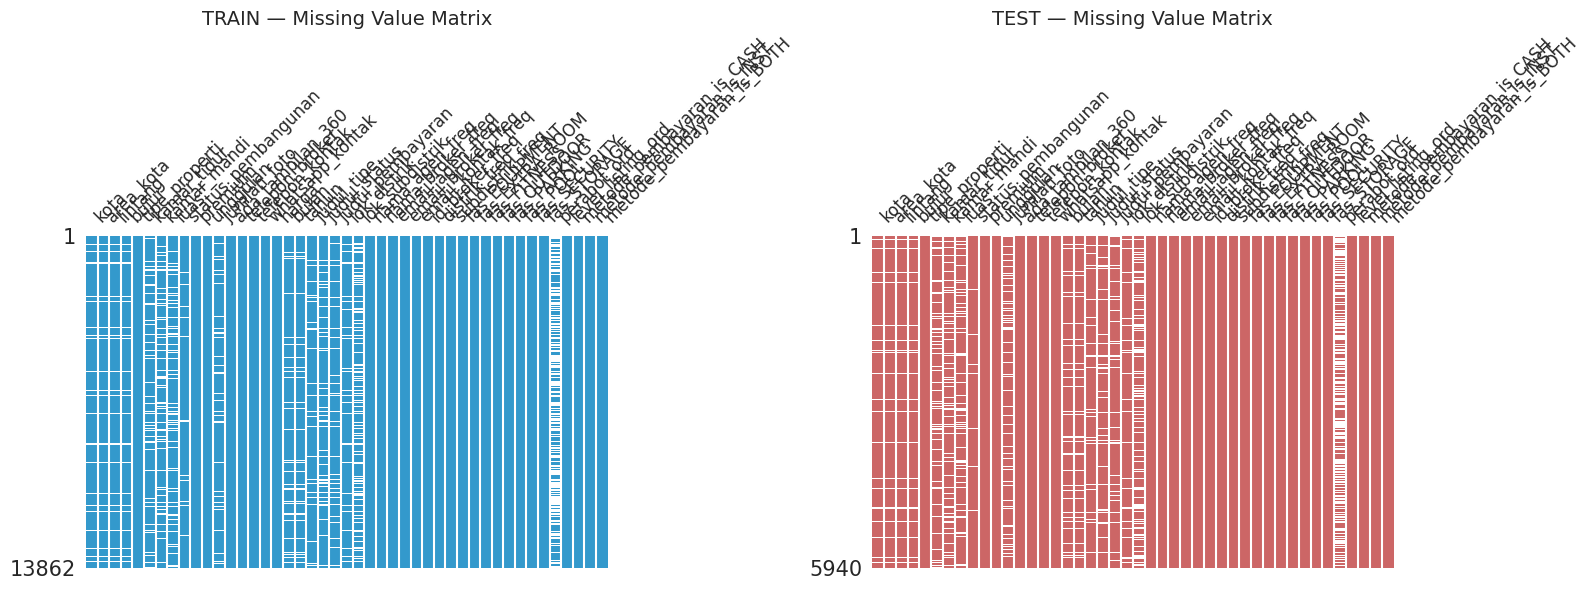

In [33]:
import missingno as msno

fig,ax = plt.subplots(1,2,figsize=(16,6))
msno.matrix(train_df, ax=ax[0], color=(0.2,0.6,0.8), fontsize=12)
ax[0].set_title('TRAIN — Missing Value Matrix', fontsize=14)
msno.matrix(test_df, ax=ax[1], color=(0.8,0.4,0.4), fontsize=12)
ax[1].set_title('TEST — Missing Value Matrix', fontsize=14)
plt.tight_layout()
plt.show()

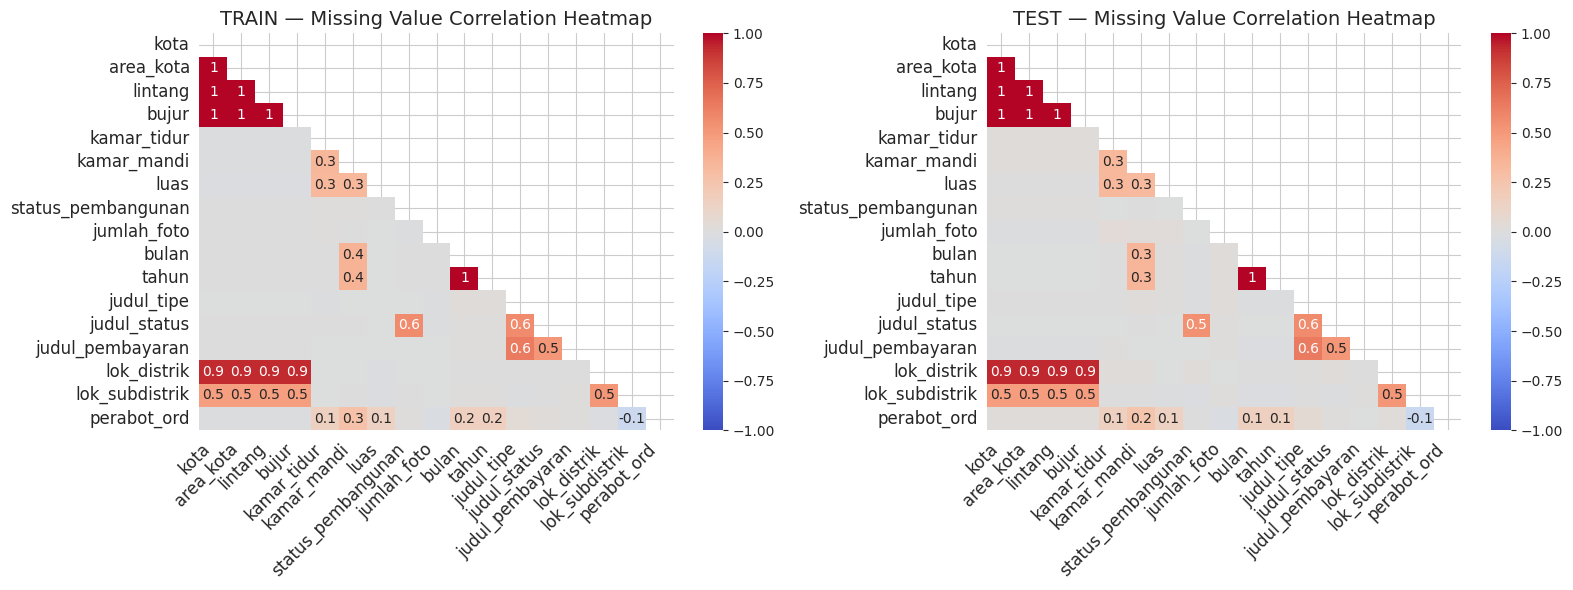

In [34]:
fig,ax = plt.subplots(1,2,figsize=(16,6))
msno.heatmap(train_df, ax=ax[0], cmap='coolwarm', fontsize=12)
ax[0].set_title('TRAIN — Missing Value Correlation Heatmap', fontsize=14)
msno.heatmap(test_df, ax=ax[1], cmap='coolwarm', fontsize=12)
ax[1].set_title('TEST — Missing Value Correlation Heatmap', fontsize=14)
plt.tight_layout()
plt.show()

## Impute Missing

In [35]:
# ================================================================
# CATBOOST-NATIVE MISSING HANDLING
#   • Numerical NaN  → left as-is (CatBoost assigns to leftmost bin)
#   • Categorical NaN → 'MISSING' as its own category
#   • Frequency NaN  → 0.0 (semantically "unseen entity")
#   • Missing-indicator flags added for high-missingness columns
# ================================================================

import numpy as np
import pandas as pd

print("=" * 80)
print("CATBOOST-NATIVE MISSING HANDLING")
print("=" * 80)

# record before state
before_missing = pd.DataFrame({
    'train': train_df.isna().sum(),
    'test':  test_df.isna().sum(),
})


# ================================================================
# STAGE 1 — MISSING-INDICATOR FLAGS
#   Missingness itself is signal (perabot 50% missing = different listing)
# ================================================================

INDICATOR_COLS = [
    'perabot_ord', 'lok_subdistrik', 'lok_distrik',
    'kamar_mandi', 'kamar_tidur', 'luas', 'jumlah_foto',
    'judul_status', 'judul_pembayaran', 'judul_tipe',
    'bulan', 'tahun',
    'lintang', 'bujur', 'kota', 'area_kota',
]

print("\n[Stage 1] Missing-indicator flags")
n_flags = 0
for col in INDICATOR_COLS:
    if col in train_df.columns:
        flag_name = f'{col}_is_missing'
        if flag_name not in train_df.columns:
            train_df[flag_name] = train_df[col].isna().astype('int8')
            test_df[flag_name]  = test_df[col].isna().astype('int8')
            n_flags += 1
print(f"   → {n_flags} new indicator flags created")


# ================================================================
# STAGE 2 — FREQUENCY COLUMNS → 0.0
#   Missing freq = entity unseen in train = true frequency 0
# ================================================================

FREQ_COLS = ['nama_agen_freq', 'nama_broker_freq',
             'email_agen_freq', 'email_broker_freq', 'email_kontak_freq',
             'id_broker_freq', 'distrik_freq', 'subdistrik_freq']

print("\n[Stage 2] Frequency columns → 0.0")
for col in FREQ_COLS:
    for df in (train_df, test_df):
        if col in df.columns:
            df[col] = df[col].fillna(0.0).astype('float32')
print(f"   → {len(FREQ_COLS)} freq columns filled")


# ================================================================
# STAGE 3 — CATEGORICALS AS STRINGS
#   CatBoost requires strings; 'MISSING' becomes its own category
# ================================================================

cat_cols = train_df.select_dtypes(
    include=['object', 'boolean', 'bool']
).columns.tolist()

print(f"\n[Stage 3] Preparing {len(cat_cols)} categorical columns as strings")
for c in cat_cols:
    train_df[c] = (train_df[c].astype(str)
                   .replace({'nan': 'MISSING', 'None': 'MISSING', '<NA>': 'MISSING'}))
    test_df[c]  = (test_df[c].astype(str)
                   .replace({'nan': 'MISSING', 'None': 'MISSING', '<NA>': 'MISSING'}))


# ================================================================
# STAGE 4 — NUMERICAL NaN LEFT AS-IS
#   CatBoost's `nan_mode='Min'` handles them natively
# ================================================================

print("\n[Stage 4] Numerical NaN preserved for CatBoost native handling")
print("   • CatBoost nan_mode='Min' assigns NaN to leftmost bin")
print("   • The *_is_missing flags explicitly capture the missing signal")


# ================================================================
# VERIFICATION
# ================================================================

print("\n" + "=" * 80)
print("VERIFICATION")
print("=" * 80)

after_missing = pd.DataFrame({
    'train_before': before_missing['train'].reindex(train_df.columns, fill_value=0),
    'train_after':  train_df.isna().sum(),
    'test_before':  before_missing['test'].reindex(test_df.columns, fill_value=0),
    'test_after':   test_df.isna().sum(),
})

cols_with_issue = after_missing[
    (after_missing['train_before'] > 0) |
    (after_missing['test_before']  > 0) |
    (after_missing['train_after']  > 0) |
    (after_missing['test_after']   > 0)
]

print("\nColumns that had (or still have) missing values:\n")
print(cols_with_issue.to_string())

n_remaining_train = train_df.isna().sum().sum()
n_remaining_test  = test_df.isna().sum().sum()

print(f"\nTotal NaN remaining — TRAIN : {n_remaining_train}")
print(f"Total NaN remaining — TEST  : {n_remaining_test}")
print("\n→ These NaNs will be handled natively by CatBoost during training.")
print("→ No imputation needed for numerical features.")


# ================================================================
# SUMMARY
# ================================================================

print("\n" + "=" * 80)
print("FINAL SHAPES")
print("=" * 80)
print(f"Train : {train_df.shape}")
print(f"Test  : {test_df.shape}")

print("\nDtype counts (TRAIN):")
print(train_df.dtypes.value_counts().to_string())

non_num = train_df.select_dtypes(include='object').columns.tolist()
print(f"\nCategorical columns (for CatBoost cat_features): {len(non_num)}")

CATBOOST-NATIVE MISSING HANDLING

[Stage 1] Missing-indicator flags
   → 16 new indicator flags created

[Stage 2] Frequency columns → 0.0
   → 8 freq columns filled

[Stage 3] Preparing 15 categorical columns as strings

[Stage 4] Numerical NaN preserved for CatBoost native handling
   • CatBoost nan_mode='Min' assigns NaN to leftmost bin
   • The *_is_missing flags explicitly capture the missing signal

VERIFICATION

Columns that had (or still have) missing values:

                    train_before  train_after  test_before  test_after
area_kota                   1022            0     433.0000      0.0000
bujur                       1022         1022     433.0000    433.0000
bulan                       1313         1313     523.0000    523.0000
judul_pembayaran            1421            0     620.0000      0.0000
judul_status                1761            0     772.0000      0.0000
judul_tipe                  1199            0     534.0000      0.0000
jumlah_foto                 16

In [36]:
print("Number of Missing Values per Column (TRAIN):")
print(train_df.isna().sum().to_string())
print("\nNumber of Missing Values per Column (TEST):")
print(test_df.isna().sum().to_string())

Number of Missing Values per Column (TRAIN):
kota                              0
area_kota                         0
lintang                        1022
bujur                          1022
tipe_properti                     0
kamar_tidur                    2083
kamar_mandi                    2155
luas                           2280
status_pembangunan                0
premium                           0
unggulan                          0
jumlah_foto                    1631
ada_tampilan_360                  0
telepon_broker                    0
telepon_kontak                    0
whatsapp_kontak                   0
harga                             0
bulan                          1313
tahun                          1313
judul_tipe                        0
judul_status                      0
judul_pembayaran                  0
lok_distrik                       0
lok_subdistrik                    0
nama_agen_freq                    0
nama_broker_freq                  0
email_agen_freq    

# Outlier Handling

In [37]:
# ================================================================
# OUTLIER HANDLING — v3 (Int64 → float fix)
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
TARGET = 'harga'


# ================================================================
# 1. AUTO-DETECT CANDIDATES (unchanged)
# ================================================================

def is_bounded_01(s):
    valid = s.dropna()
    return valid.empty or (valid.min() >= 0 and valid.max() <= 1)


def is_binary_like(s):
    return s.nunique(dropna=True) <= 2


def select_clip_candidates(df, target=None):
    candidates, skip = [], []
    for c in df.columns:
        if c == target:
            skip.append((c, 'target')); continue
        if df[c].dtype == object or str(df[c].dtype).startswith('string'):
            skip.append((c, 'categorical')); continue
        if str(df[c].dtype) == 'boolean' or df[c].dtype == bool:
            skip.append((c, 'boolean')); continue
        if not pd.api.types.is_numeric_dtype(df[c]):
            skip.append((c, 'non-numeric')); continue
        if is_binary_like(df[c]):
            skip.append((c, 'binary-like')); continue
        if is_bounded_01(df[c]) and c.endswith('_freq'):
            skip.append((c, 'freq-encoding [0,1]')); continue
        if df[c].dropna().nunique() < 10:
            skip.append((c, 'low variation')); continue
        candidates.append(c)
    return candidates, skip


candidates, skipped = select_clip_candidates(train_df, target=TARGET)

print("=" * 80)
print("OUTLIER HANDLING — COLUMN SELECTION")
print("=" * 80)
print(f"\nWill process ({len(candidates)}):")
for c in candidates:
    print(f"   + {c}")


# ================================================================
# 2. BOUND COMPUTATION (unchanged)
# ================================================================

METHOD      = 'iqr'
IQR_FACTOR  = 3.0
QUANTILE_LO = 0.005
QUANTILE_HI = 0.995


def compute_bounds(train_series, method='iqr', iqr_factor=3.0,
                   q_lo=0.005, q_hi=0.995):
    s = train_series.dropna()
    if s.empty:
        return np.nan, np.nan
    if method == 'iqr':
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - iqr_factor * iqr, q3 + iqr_factor * iqr
    else:
        lo, hi = s.quantile(q_lo), s.quantile(q_hi)
    lo = max(lo, s.min())
    hi = min(hi, s.max())
    return float(lo), float(hi)


# ================================================================
# 3. DIAGNOSTICS (unchanged)
# ================================================================

print("\n" + "=" * 80)
print(f"OUTLIER DIAGNOSTICS (method = {METHOD})")
print("=" * 80)

diag_rows = []
for c in candidates:
    lo, hi = compute_bounds(train_df[c], method=METHOD,
                            iqr_factor=IQR_FACTOR,
                            q_lo=QUANTILE_LO, q_hi=QUANTILE_HI)
    n_tr_out = int(((train_df[c] < lo) | (train_df[c] > hi)).sum())
    n_te_out = int(((test_df[c]  < lo) | (test_df[c]  > hi)).sum())
    diag_rows.append({
        'feature':      c,
        'lower':        round(lo, 3),
        'upper':        round(hi, 3),
        'train_out':    n_tr_out,
        'train_out_%':  round(n_tr_out / len(train_df) * 100, 3),
        'test_out':     n_te_out,
        'test_out_%':   round(n_te_out / len(test_df) * 100, 3),
    })

diag = pd.DataFrame(diag_rows).sort_values('train_out_%', ascending=False)
print(diag.to_string(index=False))


# ================================================================
# 4. COMPUTE BOUNDS DICT
# ================================================================

bounds = {c: compute_bounds(train_df[c], method=METHOD,
                            iqr_factor=IQR_FACTOR,
                            q_lo=QUANTILE_LO, q_hi=QUANTILE_HI)
          for c in candidates}


# ================================================================
# 5. APPLY CLIP — WITH Int64 → FLOAT FIX
# ================================================================

print("\n" + "=" * 80)
print("APPLYING CLIP (identical bounds to train and test)")
print("=" * 80)

for c in candidates:
    lo, hi = bounds[c]
    if np.isnan(lo) or np.isnan(hi):
        print(f"  [skip] {c:30s}  (no valid bounds)")
        continue

    # ---------- FIX: cast Int64/ints to float64 first ----------
    if (pd.api.types.is_integer_dtype(train_df[c])
            or str(train_df[c].dtype) in ('Int8', 'Int16', 'Int32', 'Int64',
                                          'UInt8', 'UInt16', 'UInt32', 'UInt64')):
        train_df[c] = train_df[c].astype('float64')
        test_df[c]  = test_df[c].astype('float64')

    before_tr = train_df[c].copy()
    before_te = test_df[c].copy()

    train_df[c] = train_df[c].clip(lo, hi)
    test_df[c]  = test_df[c].clip(lo, hi)

    n_tr = int((before_tr != train_df[c]).sum())
    n_te = int((before_te != test_df[c]).sum())
    print(f"  {c:30s}  clip tr: {n_tr:5d}  te: {n_te:5d}  "
          f"range→[{lo:.3f}, {hi:.3f}]")


# ================================================================
# 6. TARGET OUTLIER HANDLING (unchanged)
# ================================================================

print("\n" + "=" * 80)
print(f"TARGET ({TARGET}) — log-space trim")
print("=" * 80)

if TARGET in train_df.columns:
    y = train_df[TARGET]
    y_log = np.log1p(y)
    q_lo, q_hi = y_log.quantile(0.001), y_log.quantile(0.999)
    mask_keep = (y_log >= q_lo) & (y_log <= q_hi)
    n_cut = int((~mask_keep).sum())

    print(f"  Removing {n_cut} rows ({n_cut / len(train_df) * 100:.3f}%)")
    print(f"  Range before: {y.min():,.0f} → {y.max():,.0f}")
    train_df = train_df.loc[mask_keep].reset_index(drop=True)
    print(f"  Range after : {train_df[TARGET].min():,.0f} → {train_df[TARGET].max():,.0f}")


# ================================================================
# 7. VERIFY — train vs test shift
# ================================================================

print("\n" + "=" * 80)
print("VERIFY — train vs test shift (KS test)")
print("=" * 80)

from scipy.stats import ks_2samp

shift_rows = []
for c in candidates:
    a = train_df[c].dropna()
    b = test_df[c].dropna()
    if len(a) < 10 or len(b) < 10:
        continue
    ks_stat, ks_p = ks_2samp(a, b)
    shift_rows.append({
        'feature':    c,
        'train_mean': round(a.mean(), 3),
        'test_mean':  round(b.mean(), 3),
        'ks_stat':    round(ks_stat, 4),
        'ks_p':       round(ks_p, 4),
        'shift?':     'YES' if ks_p < 0.01 else 'no',
    })

shift_df = pd.DataFrame(shift_rows).sort_values('ks_stat', ascending=False)
print(shift_df.to_string(index=False))

n_shifted = (shift_df['shift?'] == 'YES').sum()
print(f"\n{n_shifted} / {len(shift_df)} features show shift (p < 0.01)")


# ================================================================
# 8. FINAL
# ================================================================

print("\n" + "=" * 80)
print("FINAL")
print("=" * 80)
print(f"train_df : {train_df.shape}")
print(f"test_df  : {test_df.shape}")
print(f"Features clipped : {sum(1 for c in candidates if not np.isnan(bounds[c][0]))}")

# dtype summary to confirm no more Int64 with floats
print("\nInt64 columns remaining (should be clean):")
int64_cols = [c for c in train_df.columns if str(train_df[c].dtype) == 'Int64']
print(f"  {int64_cols if int64_cols else 'none'}")

OUTLIER HANDLING — COLUMN SELECTION

Will process (7):
   + lintang
   + bujur
   + kamar_tidur
   + kamar_mandi
   + luas
   + jumlah_foto
   + bulan

OUTLIER DIAGNOSTICS (method = iqr)
    feature   lower    upper  train_out  train_out_%  test_out  test_out_%
    lintang 29.7500  30.3100       2535      18.2870      1125     18.9390
      bujur 29.1500  33.4200       1977      14.2620       888     14.9490
jumlah_foto  1.0000  22.0000        376       2.7120       172      2.8960
      bulan  1.0000   6.0000        283       2.0420        99      1.6670
       luas  1.0000 584.3000        277       1.9980       127      2.1380
kamar_tidur  0.0000  10.0000         62       0.4470        26      0.4380
kamar_mandi  1.0000  10.0000         53       0.3820        24      0.4040

APPLYING CLIP (identical bounds to train and test)
  lintang                         clip tr:  3557  te:  1558  range→[29.750, 30.310]
  bujur                           clip tr:  2999  te:  1321  range→[29.150, 3

In [38]:
# # ================================================================
# # OUTLIER HANDLING — v2 (fixed degenerate bounds + smart groups)
# # ================================================================

# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# from scipy.stats import ks_2samp
# import warnings
# warnings.filterwarnings('ignore')

# sns.set_style("whitegrid")
# TARGET = 'harga'


# # ================================================================
# # 1. FEATURE GROUPING — different rules per group
# # ================================================================

# # 1a. columns to NEVER clip (spatial geometry — clipping destroys signal)
# NEVER_CLIP = {'lintang', 'bujur', 'lat_bin_01', 'lon_bin_01',
#               'lat_lon_sum', 'lat_lon_diff',
#               'dist_to_center_km', 'dist_to_jakarta_km'}

# # 1b. columns that need BUSINESS-RULE caps, not statistical ones
# HARD_CAPS = {
#     # ratio features — cap at sane real-estate bounds
#     'luas_per_bedroom':      (5.0,    1000.0),
#     'luas_per_bathroom':     (5.0,    1500.0),
#     'luas_per_total_room':   (5.0,     500.0),
#     'bed_bath_ratio':        (0.25,     4.0),   # 1 bath per 4 beds to 4 baths per bed
#     'extra_bath':            (-5.0,    10.0),
#     'foto_per_room':         (0.1,      20.0),
#     'foto_per_100m2':        (0.05,     50.0),
#     'agent_broker_freq_ratio': (0.0,    5.0),
#     'email_freq_ratio':      (0.0,      5.0),
# }

# # 1c. columns that should use quantile method (skewed tails)
# QUANTILE_COLS = {
#     'luas', 'jumlah_foto', 'total_rooms',
#     'kamar_tidur', 'kamar_mandi',
#     'agent_broker_freq_sum',
#     'foto_log', 'luas_log', 'luas_sqrt',
#     'dist_to_center_km', 'dist_to_jakarta_km',
# }

# # 1d. columns to clip using standard IQR (mild)
# IQR_COLS = set()   # leave empty — we use quantile for the rest


# # ================================================================
# # 2. BOUND COMPUTATION — with safety checks
# # ================================================================

# def compute_iqr_bounds(s, factor=3.0):
#     s = s.dropna()
#     if s.empty or s.nunique() < 5:
#         return np.nan, np.nan
#     q1, q3 = s.quantile(0.25), s.quantile(0.75)
#     iqr = q3 - q1
#     if iqr == 0:
#         return np.nan, np.nan   # degenerate → skip
#     lo = max(q1 - factor * iqr, s.min())
#     hi = min(q3 + factor * iqr, s.max())
#     if lo >= hi:
#         return np.nan, np.nan   # collapsed → skip
#     return float(lo), float(hi)


# def compute_quantile_bounds(s, q_lo=0.005, q_hi=0.995):
#     s = s.dropna()
#     if s.empty or s.nunique() < 5:
#         return np.nan, np.nan
#     lo = float(s.quantile(q_lo))
#     hi = float(s.quantile(q_hi))
#     if lo >= hi:
#         return np.nan, np.nan
#     return lo, hi


# def get_bounds(series, col):
#     """Return (lo, hi) bounds using the right strategy for this column."""
#     # 1. NEVER clip
#     if col in NEVER_CLIP:
#         return np.nan, np.nan

#     # 2. Business rule caps
#     if col in HARD_CAPS:
#         return HARD_CAPS[col]

#     # 3. Quantile (safer for skewed)
#     if col in QUANTILE_COLS:
#         return compute_quantile_bounds(series, 0.005, 0.995)

#     # 4. Default: IQR with fallback to quantile if IQR collapses
#     lo, hi = compute_iqr_bounds(series, 3.0)
#     if np.isnan(lo) or np.isnan(hi):
#         lo, hi = compute_quantile_bounds(series, 0.005, 0.995)
#     return lo, hi


# # ================================================================
# # 3. AUTO-SELECT CANDIDATES (numeric, non-binary, non-freq)
# # ================================================================

# def is_binary_like(s):
#     return s.nunique(dropna=True) <= 2

# def select_candidates(df, target=None):
#     numeric, skip = [], []
#     for c in df.columns:
#         if c == target:
#             skip.append((c, 'target')); continue
#         if not pd.api.types.is_numeric_dtype(df[c]):
#             skip.append((c, 'non-numeric')); continue
#         if str(df[c].dtype) == 'boolean' or df[c].dtype == bool:
#             skip.append((c, 'boolean')); continue
#         if is_binary_like(df[c]):
#             skip.append((c, 'binary')); continue
#         # freq features already in [0,1]
#         if c.endswith('_freq') and df[c].dropna().between(0, 1).all():
#             skip.append((c, 'freq [0,1]')); continue
#         numeric.append(c)
#     return numeric, skip


# candidates, skipped = select_candidates(train_df, target=TARGET)
# print("=" * 80)
# print("CANDIDATES FOR CLIPPING")
# print("=" * 80)
# print(f"Will consider {len(candidates)} numeric columns")
# print(f"Explicitly excluded from IQR: {sorted(NEVER_CLIP)}")
# print(f"Hard-capped (business rules): {list(HARD_CAPS.keys())}")


# # ================================================================
# # 4. COMPUTE BOUNDS (train only) + DIAGNOSTICS
# # ================================================================

# print("\n" + "=" * 80)
# print("BOUNDS (computed on TRAIN ONLY)")
# print("=" * 80)

# bounds = {}
# diag_rows = []
# for c in candidates:
#     lo, hi = get_bounds(train_df[c], c)
#     bounds[c] = (lo, hi)

#     # count actual outliers
#     if np.isnan(lo) or np.isnan(hi):
#         n_tr_out = n_te_out = 0
#     else:
#         n_tr_out = int(((train_df[c] < lo) | (train_df[c] > hi)).sum())
#         n_te_out = int(((test_df[c]  < lo) | (test_df[c]  > hi)).sum())

#     diag_rows.append({
#         'feature':       c,
#         'lower':         round(lo, 4) if not np.isnan(lo) else None,
#         'upper':         round(hi, 4) if not np.isnan(hi) else None,
#         'train_out':     n_tr_out,
#         'train_out_%':   round(n_tr_out / len(train_df) * 100, 3),
#         'test_out':      n_te_out,
#         'test_out_%':    round(n_te_out  / len(test_df)  * 100, 3),
#         'train_max':     round(train_df[c].max(), 3),
#         'test_max':      round(test_df[c].max(),  3),
#     })

# diag = pd.DataFrame(diag_rows).sort_values('train_out_%', ascending=False)
# print(diag.to_string(index=False))


# # ================================================================
# # 5. VISUAL — BEFORE vs AFTER
# # ================================================================

# # pick the top-N most affected features (that actually have bounds)
# top_feats = diag[
#     diag['train_out_%'] > 0.5
# ].head(6)['feature'].tolist()

# if top_feats:
#     n = len(top_feats)
#     fig, axes = plt.subplots(2, n, figsize=(20, 8))
#     if n == 1:
#         axes = axes.reshape(2, 1)

#     for i, c in enumerate(top_feats):
#         lo, hi = bounds[c]

#         # top: BEFORE
#         ax = axes[0, i]
#         ax.hist(train_df[c].dropna(), bins=60, alpha=0.5,
#                 label='train', color='steelblue', density=True)
#         ax.hist(test_df[c].dropna(), bins=60, alpha=0.5,
#                 label='test', color='crimson', density=True)
#         if not np.isnan(lo): ax.axvline(lo, color='k', ls='--', lw=1)
#         if not np.isnan(hi): ax.axvline(hi, color='k', ls='--', lw=1)
#         ax.set_title(f'{c}\nBEFORE (bounds dashed)')
#         ax.legend()

#         # bottom: AFTER
#         ax = axes[1, i]
#         tr_clip = train_df[c].clip(lo, hi) if not np.isnan(lo) else train_df[c]
#         te_clip = test_df[c].clip(lo, hi)  if not np.isnan(lo) else test_df[c]
#         ax.hist(tr_clip.dropna(), bins=60, alpha=0.5,
#                 label='train', color='steelblue', density=True)
#         ax.hist(te_clip.dropna(), bins=60, alpha=0.5,
#                 label='test', color='crimson', density=True)
#         ax.set_title(f'{c}\nAFTER clip')
#         ax.legend()
#     plt.tight_layout()
#     plt.show()


# # ================================================================
# # 6. APPLY CLIP — same bounds to train AND test
# # ================================================================

# print("\n" + "=" * 80)
# print("APPLYING CLIP")
# print("=" * 80)

# for c in candidates:
#     lo, hi = bounds[c]
#     if np.isnan(lo) or np.isnan(hi):
#         print(f"  [skip] {c:30s}  (no valid bounds)")
#         continue

#     before_tr = train_df[c].copy()
#     before_te = test_df[c].copy()
#     train_df[c] = train_df[c].clip(lo, hi)
#     test_df[c]  = test_df[c].clip(lo, hi)

#     n_tr = int((before_tr != train_df[c]).sum())
#     n_te = int((before_te != test_df[c]).sum())
#     print(f"  {c:30s}  clip tr: {n_tr:5d}  te: {n_te:5d}  "
#           f"range→[{lo:.4f}, {hi:.4f}]")


# # ================================================================
# # 7. TARGET — log-space quantile trim (train only, no shift risk)
# # ================================================================

# print("\n" + "=" * 80)
# print(f"TARGET ({TARGET}) — log-space trim")
# print("=" * 80)

# if TARGET in train_df.columns:
#     y_log = np.log1p(train_df[TARGET])
#     q_lo, q_hi = y_log.quantile(0.001), y_log.quantile(0.999)
#     mask_keep = (y_log >= q_lo) & (y_log <= q_hi)
#     n_cut = int((~mask_keep).sum())

#     print(f"  Removing {n_cut} rows ({n_cut/len(train_df)*100:.3f}%)")
#     print(f"  Range before: {train_df[TARGET].min():,.0f} → {train_df[TARGET].max():,.0f}")
#     train_df = train_df.loc[mask_keep].reset_index(drop=True)
#     print(f"  Range after : {train_df[TARGET].min():,.0f} → {train_df[TARGET].max():,.0f}")
#     print(f"  Train shape : {train_df.shape}")


# # ================================================================
# # 8. VERIFY — train/test shift after handling
# # ================================================================

# print("\n" + "=" * 80)
# print("VERIFY — train vs test shift (KS test)")
# print("=" * 80)

# shift_rows = []
# for c in candidates:
#     a = train_df[c].dropna()
#     b = test_df[c].dropna()
#     if len(a) < 10 or len(b) < 10:
#         continue
#     ks_stat, ks_p = ks_2samp(a, b)
#     shift_rows.append({
#         'feature':    c,
#         'train_mean': round(a.mean(), 3),
#         'test_mean':  round(b.mean(),  3),
#         'ks_stat':    round(ks_stat, 4),
#         'ks_p':       round(ks_p, 4),
#         'shift?':     'YES' if ks_p < 0.01 else 'no',
#     })

# shift_df = pd.DataFrame(shift_rows).sort_values('ks_stat', ascending=False)
# print(shift_df.to_string(index=False))

# n_shifted = (shift_df['shift?'] == 'YES').sum()
# print(f"\n{n_shifted} / {len(shift_df)} features show shift (p < 0.01)")
# print("Note: some inherent shift is normal; what matters is nothing is NEW from clipping.")


# # ================================================================
# # 9. SUMMARY
# # ================================================================

# print("\n" + "=" * 80)
# print("FINAL")
# print("=" * 80)
# print(f"train_df : {train_df.shape}")
# print(f"test_df  : {test_df.shape}")
# print(f"Clipped features      : {sum(1 for c in candidates if not np.isnan(bounds[c][0]))}")
# print(f"Skipped (degenerate)  : {sum(1 for c in candidates if np.isnan(bounds[c][0]))}")
# print(f"Never clipped (spatial): {len(NEVER_CLIP)}")
# print(f"Hard-capped (business) : {len(HARD_CAPS)}")

# Feature Engineering

In [39]:
# ================================================================
# AGGRESSIVE FEATURE ENGINEERING
# Based on feature importance: tipe_x_luas_bin, luas*, location, freq
# ================================================================

import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

TARGET = 'harga'


# ================================================================
# HELPERS
# ================================================================

def has(df, *cols):
    return all(c in df.columns for c in cols)


def safe_div(a, b):
    a = pd.to_numeric(a, errors='coerce')
    b = pd.to_numeric(b, errors='coerce')
    return a / b.replace(0, np.nan)


def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def safe_int_str(series):
    """NaN-safe int→str using pandas Int64."""
    return series.round().astype('Int64').astype(str)


def safe_combo(df, cols, new_col, sep='_'):
    if not all(c in df.columns for c in cols):
        return
    parts = []
    for c in cols:
        s = (df[c].astype(str)
             .replace({'nan': 'MISS', 'None': 'MISS', '<NA>': 'MISS',
                       'MISSING': 'MISS', 'missing': 'MISS'}))
        parts.append(s)
    df[new_col] = parts[0]
    for p in parts[1:]:
        df[new_col] = df[new_col] + sep + p


def safe_cut(series, bins, labels):
    out = pd.cut(series, bins=bins, labels=labels, include_lowest=True)
    mask = out.isna() & series.notna()
    if mask.any():
        out = out.astype(object)
        out[mask] = 'EXTREME'
    return out.astype(str)


# ================================================================
# AGGRESSIVE FE
# ================================================================

def fe_aggressive(df, name='TRAIN', train_ref=None, center_coords=None):
    print(f"\n--- FE-aggressive: {name} (start {df.shape}) ---")
    df = df.copy()
    added = []
    def track(c): added.append(c)

    # =============================================================
    # A. BASE (from v2)
    # =============================================================

    if has(df, 'luas', 'kamar_tidur'):
        df['luas_per_bedroom'] = safe_div(df['luas'], df['kamar_tidur'])
        track('luas_per_bedroom')
    if has(df, 'luas', 'kamar_mandi'):
        df['luas_per_bathroom'] = safe_div(df['luas'], df['kamar_mandi'])
        track('luas_per_bathroom')
    if has(df, 'kamar_tidur', 'kamar_mandi'):
        df['total_rooms'] = (df['kamar_tidur'].fillna(0) +
                             df['kamar_mandi'].fillna(0)).replace(0, np.nan)
        df['extra_bath']  = (df['kamar_mandi'].fillna(0) -
                             df['kamar_tidur'].fillna(0)).clip(-10, 10)
        track('total_rooms'); track('extra_bath')
    if has(df, 'luas', 'total_rooms'):
        df['luas_per_total_room'] = safe_div(df['luas'], df['total_rooms'])
        track('luas_per_total_room')

    if 'jumlah_foto' in df.columns:
        df['foto_log']     = np.log1p(df['jumlah_foto'].clip(lower=0))
        df['foto_is_high'] = (df['jumlah_foto'] >= 20).astype('int8')
        df['foto_is_low']  = (df['jumlah_foto'] <= 5).astype('int8')
        for c in ['foto_log', 'foto_is_high', 'foto_is_low']: track(c)
        if has(df, 'total_rooms'):
            df['foto_per_room'] = safe_div(df['jumlah_foto'], df['total_rooms'])
            track('foto_per_room')
        if 'luas' in df.columns:
            df['foto_per_100m2'] = safe_div(df['jumlah_foto'], df['luas']) * 100
            track('foto_per_100m2')

    if 'luas' in df.columns:
        df['luas_log']      = np.log1p(df['luas'].clip(lower=0))
        df['luas_sqrt']     = np.sqrt(df['luas'].clip(lower=0))
        df['luas_is_large'] = (df['luas'] >= 200).astype('int8')
        df['luas_is_small'] = (df['luas'] <= 45).astype('int8')
        for c in ['luas_log', 'luas_sqrt', 'luas_is_large', 'luas_is_small']:
            track(c)

    # =============================================================
    # B. AGGRESSIVE LUAS (top signal, expand heavily)
    # =============================================================

    if 'luas' in df.columns:
        df['luas_sq']      = df['luas'] ** 2
        df['luas_cubed']   = df['luas'] ** 3
        df['luas_inv']     = safe_div(1, df['luas'])
        df['luas_pow_025'] = np.power(df['luas'].clip(lower=0), 0.25)
        df['luas_bin_num'] = pd.cut(
            df['luas'],
            bins=[-np.inf, 30, 45, 60, 80, 100, 130, 170, 220, 300, np.inf],
            labels=False
        ).astype('float')
        for c in ['luas_sq', 'luas_cubed', 'luas_inv', 'luas_pow_025',
                  'luas_bin_num']:
            track(c)

        if 'kamar_tidur' in df.columns:
            df['bedroom_density'] = safe_div(df['kamar_tidur'], df['luas']) * 100
            track('bedroom_density')
        if 'kamar_mandi' in df.columns:
            df['bathroom_density'] = safe_div(df['kamar_mandi'], df['luas']) * 100
            track('bathroom_density')
        if 'total_rooms' in df.columns:
            df['room_density'] = safe_div(df['total_rooms'], df['luas']) * 100
            track('room_density')

    # =============================================================
    # C. LOCATION — AGGRESSIVE
    # =============================================================

    if has(df, 'lintang', 'bujur'):
        lat, lon = df['lintang'], df['bujur']

        c_lat, c_lon = (center_coords if center_coords is not None
                        else (lat.median(), lon.median()))

        df['dist_to_center_km'] = haversine_km(lat, lon, c_lat, c_lon)
        df['dist_to_jakarta_real_km'] = haversine_km(lat, lon, -6.2, 106.816666)
        track('dist_to_center_km'); track('dist_to_jakarta_real_km')

        # interactions
        df['lat_lon_sum']      = lat + lon
        df['lat_lon_diff']     = lat - lon
        df['lat_x_lon']        = lat * lon
        df['lat_plus_lon_sq']  = lat * lat + lon * lon
        df['lat_minus_lon_sq'] = (lat - lon) ** 2
        df['lat_over_lon']     = safe_div(lat, lon)
        for c in ['lat_lon_sum', 'lat_lon_diff', 'lat_x_lon',
                  'lat_plus_lon_sq', 'lat_minus_lon_sq', 'lat_over_lon']:
            track(c)

        # NaN-safe integer rounded
        df['lat_deg_round'] = (lat * 100).round().astype('Int64')
        df['lon_deg_round'] = (lon * 100).round().astype('Int64')
        track('lat_deg_round'); track('lon_deg_round')

        # grid bins (NaN-safe string)
        df['lat_bin_01']  = safe_int_str(lat * 10)
        df['lon_bin_01']  = safe_int_str(lon * 10)
        df['lat_bin_001'] = safe_int_str(lat * 100)
        df['lon_bin_001'] = safe_int_str(lon * 100)
        for c in ['lat_bin_01', 'lon_bin_01', 'lat_bin_001', 'lon_bin_001']:
            track(c)

        df['grid_01']  = df['lat_bin_01']  + '_' + df['lon_bin_01']
        df['grid_001'] = df['lat_bin_001'] + '_' + df['lon_bin_001']
        track('grid_01'); track('grid_001')

    # =============================================================
    # D. HIERARCHY COMBINATIONS
    # =============================================================

    if has(df, 'kota', 'area_kota'):
        safe_combo(df, ['kota', 'area_kota'], 'kota_area'); track('kota_area')
    if has(df, 'area_kota', 'distrik'):
        safe_combo(df, ['area_kota', 'distrik'], 'area_distrik'); track('area_distrik')
    elif has(df, 'area_kota', 'lok_distrik'):
        safe_combo(df, ['area_kota', 'lok_distrik'], 'area_distrik'); track('area_distrik')
    if has(df, 'kota', 'tipe_properti'):
        safe_combo(df, ['kota', 'tipe_properti'], 'kota_x_tipe'); track('kota_x_tipe')
    if has(df, 'area_kota', 'tipe_properti'):
        safe_combo(df, ['area_kota', 'tipe_properti'], 'area_x_tipe'); track('area_x_tipe')

    # =============================================================
    # E. TIPE × LUAS (DOUBLE DOWN — top feature at 15%)
    # =============================================================

    if 'luas' in df.columns:
        luas_bin = safe_cut(
            df['luas'],
            bins=[-np.inf, 45, 70, 100, 150, 250, np.inf],
            labels=['XS', 'S', 'M', 'L', 'XL', 'XXL'],
        )
        df['_luas_bin'] = luas_bin

    # 2-way tipe × luas
    if has(df, 'tipe_properti', '_luas_bin'):
        safe_combo(df, ['tipe_properti', '_luas_bin'], 'tipe_x_luas_bin')
        track('tipe_x_luas_bin')

    # 3-way: tipe × status × luas
    if has(df, 'tipe_properti', 'status_pembangunan', '_luas_bin'):
        safe_combo(df, ['tipe_properti', 'status_pembangunan', '_luas_bin'],
                   'tipe_status_luas'); track('tipe_status_luas')

    # 3-way: tipe × kota × luas
    if has(df, 'tipe_properti', 'kota', '_luas_bin'):
        safe_combo(df, ['tipe_properti', 'kota', '_luas_bin'],
                   'tipe_kota_luas'); track('tipe_kota_luas')

    # 3-way: tipe × bed × luas
    if has(df, 'tipe_properti', 'kamar_tidur', '_luas_bin'):
        safe_combo(df, ['tipe_properti', 'kamar_tidur', '_luas_bin'],
                   'tipe_bed_luas'); track('tipe_bed_luas')

    # tipe × bed (2-way)
    if has(df, 'tipe_properti', 'kamar_tidur'):
        safe_combo(df, ['tipe_properti', 'kamar_tidur'], 'tipe_x_bed')
        track('tipe_x_bed')

    # tipe × status × payment (3-way)
    if has(df, 'tipe_properti', 'status_pembangunan', 'metode_pembayaran'):
        safe_combo(df, ['tipe_properti', 'status_pembangunan', 'metode_pembayaran'],
                   'tipe_status_pay'); track('tipe_status_pay')

    # district × tipe
    if has(df, 'lok_distrik', 'tipe_properti'):
        safe_combo(df, ['lok_distrik', 'tipe_properti'],
                   'distrik_x_tipe'); track('distrik_x_tipe')
    if has(df, 'lok_subdistrik', 'tipe_properti'):
        safe_combo(df, ['lok_subdistrik', 'tipe_properti'],
                   'subdistrik_x_tipe'); track('subdistrik_x_tipe')

    # =============================================================
    # F. STATUS / JUDUL
    # =============================================================

    if has(df, 'status_pembangunan', 'tipe_properti'):
        safe_combo(df, ['status_pembangunan', 'tipe_properti'],
                   'status_x_tipe'); track('status_x_tipe')
    if has(df, 'judul_status', 'judul_tipe'):
        safe_combo(df, ['judul_status', 'judul_tipe'],
                   'judul_combo'); track('judul_combo')
    if has(df, 'status_pembangunan', 'metode_pembayaran'):
        safe_combo(df, ['status_pembangunan', 'metode_pembayaran'],
                   'status_x_pay'); track('status_x_pay')

    # =============================================================
    # G. BOOLEAN AGGREGATES + LUXURY
    # =============================================================

    bool_cols = [c for c in ['premium', 'unggulan', 'ada_tampilan_360']
                 if c in df.columns]
    present_bools = []
    for c in bool_cols:
        col_int = f'{c}_int'
        if col_int not in df.columns:
            df[col_int] = (df[c].astype(str).str.upper()
                           .map({'TRUE': 1, 'FALSE': 0, 'YES': 1, 'NO': 0,
                                 '1': 1, '0': 0}))
            df[col_int] = df[col_int].fillna(0).astype('int8')
            track(col_int)
        present_bools.append(col_int)

    if present_bools and 'flag_count' not in df.columns:
        df['flag_count'] = df[present_bools].sum(axis=1).astype('int8')
        track('flag_count')

    # luxury score
    if present_bools and 'luxury_score' not in df.columns:
        df['luxury_score'] = df[present_bools].sum(axis=1).astype('int8')
        track('luxury_score')

    if 'luxury_score' in df.columns and '_luas_bin' in df.columns:
        safe_combo(df, ['luxury_score', '_luas_bin'], 'luxury_x_luas')
        track('luxury_x_luas')
    if 'luxury_score' in df.columns and 'tipe_properti' in df.columns:
        safe_combo(df, ['luxury_score', 'tipe_properti'], 'luxury_x_tipe')
        track('luxury_x_tipe')

    # =============================================================
    # H. AGENT / BROKER (id_broker_freq was #2)
    # =============================================================

    if has(df, 'nama_agen_freq', 'nama_broker_freq'):
        df['agent_broker_freq_ratio'] = safe_div(df['nama_agen_freq'],
                                                  df['nama_broker_freq'])
        df['agent_broker_freq_sum']   = (df['nama_agen_freq'].fillna(0)
                                          + df['nama_broker_freq'].fillna(0))
        track('agent_broker_freq_ratio'); track('agent_broker_freq_sum')

    if has(df, 'email_agen_freq', 'email_broker_freq'):
        df['email_freq_ratio'] = safe_div(df['email_agen_freq'],
                                           df['email_broker_freq'])
        track('email_freq_ratio')

    if has(df, 'nama_agen_freq', 'email_agen_freq'):
        df['agen_email_freq_diff'] = df['nama_agen_freq'] - df['email_agen_freq']
        df['agen_email_freq_prod'] = df['nama_agen_freq'] * df['email_agen_freq']
        track('agen_email_freq_diff'); track('agen_email_freq_prod')

    if has(df, 'nama_broker_freq', 'email_broker_freq'):
        df['broker_email_freq_diff'] = df['nama_broker_freq'] - df['email_broker_freq']
        track('broker_email_freq_diff')

    if has(df, 'id_broker_freq', 'nama_broker_freq'):
        df['id_broker_vs_name_freq'] = safe_div(df['id_broker_freq'],
                                                 df['nama_broker_freq'])
        track('id_broker_vs_name_freq')

    # =============================================================
    # I. MISSING PATTERNS
    # =============================================================

    miss_cols = [c for c in df.columns if c.endswith('_is_missing')]
    if miss_cols:
        df['n_missing_flags'] = df[miss_cols].sum(axis=1).astype('int16')
        track('n_missing_flags')

    if ('perabot_ord_is_missing' in df.columns
            and 'luas_is_missing' in df.columns):
        df['perabot_x_luas_miss'] = (
            df['perabot_ord_is_missing'].astype(str)
            + '_' + df['luas_is_missing'].astype(str)
        )
        track('perabot_x_luas_miss')

    # =============================================================
    # J. ROOM RATIOS (deepen)
    # =============================================================

    if has(df, 'kamar_tidur', 'kamar_mandi'):
        df['bed_x_bath']    = df['kamar_tidur'] * df['kamar_mandi']
        df['bed_plus_bath'] = df['kamar_tidur'] + df['kamar_mandi']
        df['bed_over_bath'] = safe_div(df['kamar_tidur'], df['kamar_mandi'])
        df['bath_over_bed'] = safe_div(df['kamar_mandi'], df['kamar_tidur'])
        for c in ['bed_x_bath', 'bed_plus_bath', 'bed_over_bath', 'bath_over_bed']:
            track(c)

    # =============================================================
    # K. PHOTOS (deepen)
    # =============================================================

    if 'jumlah_foto' in df.columns:
        df['foto_sq']  = df['jumlah_foto'] ** 2
        df['foto_bin'] = pd.cut(
            df['jumlah_foto'],
            bins=[-np.inf, 5, 10, 15, 20, 30, np.inf],
            labels=False
        ).astype('float')
        track('foto_sq'); track('foto_bin')

    # =============================================================
    # L. TIME (only if month varies)
    # =============================================================

    if 'bulan' in df.columns and df['bulan'].nunique(dropna=True) > 3:
        df['month_sin'] = np.sin(2 * np.pi * df['bulan'] / 12)
        df['month_cos'] = np.cos(2 * np.pi * df['bulan'] / 12)
        track('month_sin'); track('month_cos')

    if 'tahun' in df.columns and df['tahun'].nunique(dropna=True) > 1:
        df['year_month_index'] = df['tahun'] * 12 + df.get('bulan', 0)
        df['age_years']        = df['tahun'].max() - df['tahun']
        track('year_month_index'); track('age_years')

    # =============================================================
    # M. GROUP-LEVEL STATISTICS (uses train_ref)
    # =============================================================

    if train_ref is not None:
        specs = [
            ('kota',             'kota_stats'),
            ('area_kota',        'area_stats'),
            ('tipe_properti',    'tipe_stats'),
            ('tipe_x_luas_bin',  'tipe_luas_stats'),
            ('lok_distrik',      'distrik_stats'),
            ('lok_subdistrik',   'subdistrik_stats'),
        ]
        for col, key in specs:
            if col not in df.columns or key not in train_ref:
                continue
            ref = train_ref[key]
            if 'size' in ref:
                df[f'{col}_count'] = df[col].map(ref['size']).fillna(0).astype('float32')
                track(f'{col}_count')
            if 'luas_median' in ref and 'luas' in df.columns:
                df[f'luas_vs_{col}_median'] = safe_div(
                    df['luas'], df[col].map(ref['luas_median']))
                track(f'luas_vs_{col}_median')
            if 'km_median' in ref and 'kamar_mandi' in df.columns:
                df[f'km_vs_{col}_median'] = safe_div(
                    df['kamar_mandi'], df[col].map(ref['km_median']))
                track(f'km_vs_{col}_median')

    # cleanup temp
    if '_luas_bin' in df.columns:
        df.drop(columns=['_luas_bin'], inplace=True)

    print(f"  → added {len(set(added))} new features  →  end shape {df.shape}")
    return df


# ================================================================
# BUILD TRAIN STATS
# ================================================================

def build_train_stats(train_df):
    stats = {}
    group_cols = {
        'kota_stats':        'kota',
        'area_stats':        'area_kota',
        'tipe_stats':        'tipe_properti',
        'tipe_luas_stats':   'tipe_x_luas_bin',
        'distrik_stats':     'lok_distrik',
        'subdistrik_stats':  'lok_subdistrik',
    }
    for key, col in group_cols.items():
        if col not in train_df.columns:
            continue
        g = train_df.groupby(col)
        d = {'size': g.size().to_dict()}
        if 'luas' in train_df.columns:
            d['luas_median'] = g['luas'].median().to_dict()
        if 'kamar_mandi' in train_df.columns:
            d['km_median'] = g['kamar_mandi'].median().to_dict()
        stats[key] = d
    return stats


# ================================================================
# APPLY — 3-pass pipeline
# ================================================================

print("=" * 80)
print("AGGRESSIVE FE — START")
print("=" * 80)
print(f"Initial shapes — train: {train_df.shape}   test: {test_df.shape}")

# reference center from TRAIN only
if has(train_df, 'lintang', 'bujur'):
    TRAIN_CENTER = (train_df['lintang'].median(),
                    train_df['bujur'].median())
    print(f"Reference center: lat={TRAIN_CENTER[0]:.4f}  lon={TRAIN_CENTER[1]:.4f}")
else:
    TRAIN_CENTER = None

# Pass 1: base FE on train
train_df = fe_aggressive(train_df, 'TRAIN (pass 1)',
                         train_ref=None, center_coords=TRAIN_CENTER)

# Build stats from train
train_stats = build_train_stats(train_df)
print(f"\nGroup stats: {list(train_stats.keys())}")

# Pass 2: group stats added to train
train_df = fe_aggressive(train_df, 'TRAIN (pass 2)',
                         train_ref=train_stats, center_coords=TRAIN_CENTER)

# Pass 3: full FE on test
test_df = fe_aggressive(test_df, 'TEST',
                        train_ref=train_stats, center_coords=TRAIN_CENTER)


# ================================================================
# ALIGN
# ================================================================

extra_in_test = [c for c in test_df.columns if c not in train_df.columns]
if extra_in_test:
    print(f"\n[drop] test-only: {extra_in_test}")
    test_df = test_df.drop(columns=extra_in_test)

missing_in_test = [c for c in train_df.columns
                   if c not in test_df.columns and c != TARGET]
if missing_in_test:
    print(f"[!] train-only cols: {missing_in_test}")

test_df = test_df[[c for c in train_df.columns if c != TARGET]]

print(f"\nAligned — train: {train_df.shape}  test: {test_df.shape}")


# ================================================================
# VERIFY
# ================================================================

print("\n" + "=" * 80)
print("VERIFICATION")
print("=" * 80)

# drop constants
const_cols = [c for c in train_df.columns
              if c != TARGET and train_df[c].nunique(dropna=True) <= 1]
if const_cols:
    print(f"\n⚠️  Dropping {len(const_cols)} constant columns: {const_cols}")
    train_df = train_df.drop(columns=const_cols)
    test_df  = test_df.drop(columns=[c for c in const_cols if c in test_df.columns])
else:
    print("\n✅ No constant columns")

# flag extreme-scale numerics
bad = []
for c in train_df.select_dtypes(include=[np.number]).columns:
    if c == TARGET: continue
    s = train_df[c].dropna()
    if len(s) and s.min() >= 0 and s.max() / (s.min() + 1e-9) > 1e10:
        bad.append(c)
if bad:
    print(f"\n⚠️  Extreme-scale: {bad}")
else:
    print("✅ No extreme-scale columns")


# ================================================================
# SUMMARY
# ================================================================

print("\n" + "=" * 80)
print(f"AGGRESSIVE FE — DONE")
print("=" * 80)
print(f"Train shape : {train_df.shape}")
print(f"Test  shape : {test_df.shape}")
print(f"Features    : {train_df.shape[1] - 1} (excluding target)")

# list new features
BASE = {
    'luas','kamar_tidur','kamar_mandi','jumlah_foto','lintang','bujur',
    'kota','area_kota','distrik','subdistrik','tipe_properti',
    'status_pembangunan','metode_pembayaran','judul_tipe','judul_status',
    'judul_pembayaran','premium','unggulan','ada_tampilan_360',
    'perabot_ord','level_listing','bulan','tahun','harga',
    'nama_agen_freq','nama_broker_freq','email_agen_freq','email_broker_freq',
    'email_kontak_freq','id_broker_freq','distrik_freq','subdistrik_freq',
    'lok_distrik','lok_subdistrik','telepon_broker_freq','telepon_kontak_freq',
}
new_cols = sorted([c for c in train_df.columns if c not in BASE])
print(f"\nNewly created features ({len(new_cols)}):")
for c in new_cols:
    print(f"   + {c}")

AGGRESSIVE FE — START
Initial shapes — train: (13835, 61)   test: (5940, 60)
Reference center: lat=30.0300  lon=31.4600

--- FE-aggressive: TRAIN (pass 1) (start (13835, 61)) ---
  → added 77 new features  →  end shape (13835, 138)

Group stats: ['kota_stats', 'area_stats', 'tipe_stats', 'tipe_luas_stats', 'distrik_stats', 'subdistrik_stats']

--- FE-aggressive: TRAIN (pass 2) (start (13835, 138)) ---
  → added 90 new features  →  end shape (13835, 156)

--- FE-aggressive: TEST (start (5940, 60)) ---
  → added 95 new features  →  end shape (5940, 155)

Aligned — train: (13835, 156)  test: (5940, 155)

VERIFICATION

✅ No constant columns

⚠️  Extreme-scale: ['bedroom_density', 'dist_to_center_km', 'agent_broker_freq_ratio', 'n_missing_flags', 'bed_x_bath']

AGGRESSIVE FE — DONE
Train shape : (13835, 156)
Test  shape : (5940, 155)
Features    : 155 (excluding target)

Newly created features (126):
   + ada_tampilan_360_int
   + age_years
   + agen_email_freq_diff
   + agen_email_freq_pro

# Modelling

In [40]:
X, y = train_df.drop(columns=[TARGET]), train_df[TARGET]

X.shape, y.shape, test_df.shape

((13835, 155), (13835,), (5940, 155))

In [41]:
# ================================================================
# FAST STACKING — CB + XGB + LGBM → Ridge Meta
# Target: log1p(harga) → RMSLE
# ================================================================

import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor, Pool
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
import time, warnings
warnings.filterwarnings('ignore')

TARGET   = 'harga'
N_SPLITS = 5
SEED     = 42
MAX_CAT_LGBM = 255


# ================================================================
# 1. SPLIT + LOG TRANSFORM
# ================================================================

X      = train_df.drop(columns=[TARGET]).copy()
y      = np.log1p(train_df[TARGET].values)
X_test = test_df.copy()

cat_cols_all = X.select_dtypes(include=['object', 'boolean', 'bool']).columns.tolist()
print(f"X: {X.shape}  y: {y.shape}  X_test: {X_test.shape}  cats: {len(cat_cols_all)}")


# ================================================================
# 2. BUILD PER-MODEL DATAFRAMES (once, outside the fold loop)
# ================================================================

# ---- CatBoost: strings, native cat_features (any cardinality) ----
X_cb = X.copy(); X_test_cb = X_test.copy()
for c in cat_cols_all:
    X_cb[c]      = X_cb[c].astype(str).replace({'nan':'MISSING','None':'MISSING','<NA>':'MISSING'})
    X_test_cb[c] = X_test_cb[c].astype(str).replace({'nan':'MISSING','None':'MISSING','<NA>':'MISSING'})
X_test_cb = X_test_cb[X_cb.columns]

# ---- LightGBM: freq-encode >255, rest category ----
low_lgbm  = [c for c in cat_cols_all if X[c].nunique(dropna=True) <= MAX_CAT_LGBM]
high_lgbm = [c for c in cat_cols_all if X[c].nunique(dropna=True) >  MAX_CAT_LGBM]

X_lgb = X.copy(); X_test_lgb = X_test.copy()
for c in high_lgbm:
    freq = X[c].value_counts(normalize=True)
    X_lgb[f'{c}_freq']      = X_lgb[c].map(freq).fillna(0).astype('float32')
    X_test_lgb[f'{c}_freq'] = X_test_lgb[c].map(freq).fillna(0).astype('float32')
    X_lgb.drop(columns=[c], inplace=True); X_test_lgb.drop(columns=[c], inplace=True)
for c in low_lgbm:
    X_lgb[c]      = X_lgb[c].astype(str).replace({'nan':'MISSING','<NA>':'MISSING'})
    X_test_lgb[c] = X_test_lgb[c].astype(str).replace({'nan':'MISSING','<NA>':'MISSING'})
    all_cats = sorted(set(X_lgb[c].unique()) | set(X_test_lgb[c].unique()))
    X_lgb[c]      = pd.Categorical(X_lgb[c], categories=all_cats)
    X_test_lgb[c] = pd.Categorical(X_test_lgb[c], categories=all_cats)
X_test_lgb = X_test_lgb[X_lgb.columns]

# ---- XGBoost: same as LGBM (native categorical, aligned codes) ----
X_xgb = X_lgb.copy(); X_test_xgb = X_test_lgb.copy()

print(f"CB: {X_cb.shape}   LGB: {X_lgb.shape}   XGB: {X_xgb.shape}")


# ================================================================
# 3. FAST PARAMS
# ================================================================

cb_params = dict(
    iterations           = 2000,        # was 3000
    learning_rate        = 0.05,
    depth                = 6,
    border_count         = 64,
    max_ctr_complexity   = 1,
    one_hot_max_size     = 20,
    boosting_type        = 'Plain',
    bootstrap_type       = 'Bernoulli',
    subsample            = 0.8,
    l2_leaf_reg          = 3.0,
    random_seed          = SEED,
    od_type              = 'Iter',
    od_wait              = 100,          # fast early stop
    verbose              = False,
    allow_writing_files  = False,
    loss_function        = 'RMSE',
    eval_metric          = 'RMSE',
    task_type            = 'GPU',
    devices              = '0',
    gpu_ram_part         = 0.95,
)

xgb_params = dict(
    n_estimators          = 2000,
    learning_rate         = 0.05,
    max_depth             = 6,
    min_child_weight      = 3,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    reg_alpha             = 0.1,
    reg_lambda            = 0.1,
    tree_method           = 'hist',
    device                = 'cuda',
    enable_categorical    = True,
    max_cat_to_onehot     = 8,
    eval_metric           = 'rmse',
    early_stopping_rounds = 100,
    random_state          = SEED,
)

lgb_params = dict(
    n_estimators      = 2000,
    objective         = 'regression',
    metric            = 'rmse',
    learning_rate     = 0.05,
    num_leaves        = 64,
    min_child_samples = 20,
    feature_fraction  = 0.8,
    bagging_fraction  = 0.8,
    bagging_freq      = 5,
    lambda_l1         = 0.1,
    lambda_l2         = 0.1,
    verbose           = -1,
    seed              = SEED,
    device            = 'gpu',
    gpu_platform_id   = 0,
    gpu_device_id     = 0,
    max_bin           = 255,
)


# ================================================================
# 4. SAME-FOLD CV — MUST share KFold for all models
# ================================================================

kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
folds = list(kf.split(X))

oof_cb = np.zeros(len(X)); test_cb = np.zeros(len(X_test))
oof_xgb = np.zeros(len(X)); test_xgb = np.zeros(len(X_test))
oof_lgb = np.zeros(len(X)); test_lgb = np.zeros(len(X_test))

print("\n" + "=" * 80)
print(f"TRAINING 3 BASE MODELS — {N_SPLITS}-FOLD CV")
print("=" * 80)

t_all = time.time()
for fold, (tr, va) in enumerate(folds, 1):
    t0 = time.time()

    # CatBoost
    mc = CatBoostRegressor(**cb_params)
    mc.fit(Pool(X_cb.iloc[tr], y[tr], cat_features=cat_cols_all),
           eval_set=Pool(X_cb.iloc[va], y[va], cat_features=cat_cols_all),
           use_best_model=True)
    oof_cb[va] = mc.predict(X_cb.iloc[va])
    test_cb   += mc.predict(Pool(X_test_cb, cat_features=cat_cols_all)) / N_SPLITS
    t_cb = time.time() - t0

    # XGBoost
    t1 = time.time()
    mx = xgb.XGBRegressor(**xgb_params)
    mx.fit(X_xgb.iloc[tr], y[tr],
           eval_set=[(X_xgb.iloc[va], y[va])], verbose=False)
    oof_xgb[va] = mx.predict(X_xgb.iloc[va])
    test_xgb   += mx.predict(X_test_xgb) / N_SPLITS
    t_xgb = time.time() - t1

    # LightGBM
    t1 = time.time()
    ml = lgb.LGBMRegressor(**lgb_params)
    ml.fit(X_lgb.iloc[tr], y[tr],
           eval_set=[(X_lgb.iloc[va], y[va])],
           callbacks=[lgb.early_stopping(100, verbose=False),
                      lgb.log_evaluation(0)])
    oof_lgb[va] = ml.predict(X_lgb.iloc[va])
    test_lgb   += ml.predict(X_test_lgb) / N_SPLITS
    t_lgb = time.time() - t1

    print(f"Fold {fold}  |  CB {t_cb:5.1f}s  XGB {t_xgb:5.1f}s  LGB {t_lgb:5.1f}s  "
          f"|  total {time.time()-t0:5.1f}s")

print(f"\nTotal: {time.time() - t_all:.1f}s")


# ================================================================
# 5. BASE MODEL SCORES
# ================================================================

def rmsle(yt, yp):
    return np.sqrt(mean_squared_error(yt, yp))

print("\n" + "=" * 80)
print("BASE MODEL OOF SCORES")
print("=" * 80)
print(f"  CatBoost : RMSLE = {rmsle(y, oof_cb):.5f}   R² = {r2_score(y, oof_cb):.5f}")
print(f"  XGBoost  : RMSLE = {rmsle(y, oof_xgb):.5f}   R² = {r2_score(y, oof_xgb):.5f}")
print(f"  LightGBM : RMSLE = {rmsle(y, oof_lgb):.5f}   R² = {r2_score(y, oof_lgb):.5f}")


# ================================================================
# 6. STACKING — RIDGE META-LEARNER (with CV for honest estimate)
# ================================================================

meta_X      = np.column_stack([oof_cb, oof_xgb, oof_lgb])
meta_X_test = np.column_stack([test_cb, test_xgb, test_lgb])

meta_kf  = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
meta_oof = np.zeros(len(X))

for tr, va in meta_kf.split(meta_X):
    m = Ridge(alpha=1.0, positive=True)
    m.fit(meta_X[tr], y[tr])
    meta_oof[va] = m.predict(meta_X[va])

# final meta on all OOF
meta_final = Ridge(alpha=1.0, positive=True)
meta_final.fit(meta_X, y)

print("\n" + "=" * 80)
print("STACKING — RIDGE META-LEARNER")
print("=" * 80)
print(f"  Stacked CV RMSLE : {rmsle(y, meta_oof):.5f}")
print(f"  Stacked CV R²    : {r2_score(y, meta_oof):.5f}")
print(f"\n  Meta weights:")
print(f"    CatBoost : {meta_final.coef_[0]:.4f}")
print(f"    XGBoost  : {meta_final.coef_[1]:.4f}")
print(f"    LightGBM : {meta_final.coef_[2]:.4f}")
print(f"    intercept: {meta_final.intercept_:.4f}")

# compare to best single
best_single = min(rmsle(y, oof_cb), rmsle(y, oof_xgb), rmsle(y, oof_lgb))
gain = best_single - rmsle(y, meta_oof)
print(f"\n  Best single RMSLE : {best_single:.5f}")
print(f"  Stack gain        : {gain:+.5f}")


# ================================================================
# 7. SUBMISSION
# ================================================================

final_pred = np.expm1(meta_final.predict(meta_X_test))

sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
submission = sample_submission.copy()
submission['harga'] = final_pred
submission.to_csv('submission.csv', index=False)

print(f"\nSaved submission.csv — shape {submission.shape}")
print(f"Prediction range : {final_pred.min():,.0f}  →  {final_pred.max():,.0f}")
print(f"Prediction mean  : {final_pred.mean():,.0f}   median: {np.median(final_pred):,.0f}")

X: (13835, 155)  y: (13835,)  X_test: (5940, 155)  cats: 37
CB: (13835, 155)   LGB: (13835, 155)   XGB: (13835, 155)

TRAINING 3 BASE MODELS — 5-FOLD CV
Fold 1  |  CB   4.8s  XGB   3.6s  LGB  10.2s  |  total  18.5s
Fold 2  |  CB   4.6s  XGB   3.6s  LGB  10.7s  |  total  18.9s
Fold 3  |  CB   4.7s  XGB   4.9s  LGB  11.9s  |  total  21.4s
Fold 4  |  CB   4.7s  XGB   3.8s  LGB  10.9s  |  total  19.4s
Fold 5  |  CB   4.6s  XGB   2.3s  LGB   6.7s  |  total  13.6s

Total: 91.8s

BASE MODEL OOF SCORES
  CatBoost : RMSLE = 0.37378   R² = 0.84123
  XGBoost  : RMSLE = 0.41239   R² = 0.80672
  LightGBM : RMSLE = 0.40019   R² = 0.81799

STACKING — RIDGE META-LEARNER
  Stacked CV RMSLE : 0.37145
  Stacked CV R²    : 0.84320

  Meta weights:
    CatBoost : 0.7727
    XGBoost  : 0.0700
    LightGBM : 0.1715
    intercept: -0.2263

  Best single RMSLE : 0.37378
  Stack gain        : +0.00233

Saved submission.csv — shape (5940, 2)
Prediction range : 394,211  →  210,522,804
Prediction mean  : 14,061,34